# M33 PN inference diagnostics — astrometry/coverage refactor

This version keeps the original catalogue-coordinate completeness metric, but also:
- filters catalogue objects to positions with valid MUSE [O III] coverage;
- reports nearest CNN-peak offsets before one-to-one matching;
- allows the diagnostic Moffat centroid to move by ±4 pixels;
- fits an independent [O III] centroid at every covered catalogue PN position;
- reports a second recovery curve using those fitted [O III] centroids;
- keeps catalogue-coordinate and centroid-refined results separate.


In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.stats import sigma_clip, mad_std
from scipy.ndimage import maximum_filter
from scipy.optimize import least_squares
from scipy.stats import spearmanr
from scipy.spatial import cKDTree
from tensorflow import keras

TARGET_NAME = "M33"
MODEL_RUN_ID = "v4.7"
MODEL_PATH = f"best_PN_ResUNet_focal_all_grouped_{MODEL_RUN_ID}.keras"
#FITS_PATH = "/Users/golta/Neb_det/data/M33_4channel.fits"
FITS_PATH = "M33_4channel_NGC253_distance.fits"
NORM_PATH = f"PN_ResUNet_normalization_{MODEL_RUN_ID}.npz"
CATALOG_PATH = "/Users/golta/Neb_det/data/PN_CAT_M33.csv"
ORIGINAL_FITS_PATH = "/Users/golta/Neb_det/data/M33_MAPS.fits"

OUTPUT_DIR = Path(f"/Users/golta/Neb_det/output/PN_detection/inference/{TARGET_NAME}_pn_diagnostics_v5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32
MIN_DISTANCE = 3

# Fixed diagnostic operating point agreed for this analysis.
MATCH_TOLERANCE = 2.0
MATCH_TOLERANCE_GRID = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 4.0])

# Cutout / measurement settings.
DIAG_CUTOUT_SIZE = 32
EDGE_MARGIN = DIAG_CUTOUT_SIZE // 2
APERTURE_RADIUS = 3.0
BG_INNER_RADIUS = 6.0
BG_OUTER_RADIUS = 9.0
BG_CLIP_SIGMA = 3.0
RATIO_SNR_MIN = 2.0

# [O III] 5007 magnitude convention: m5007 = -2.5 log10(F5007) - 13.74
# F5007 must be in erg s^-1 cm^-2. Leave this at 1.0 when the ADP flux
# extension is already in cgs; change only if the FITS BUNIT explicitly uses
# scaled numerical units (for example 1e-20 erg s^-1 cm^-2).
M5007_ZEROPOINT = 13.74
OIII_FLUX_TO_CGS = 1e-20
INPUT_FLUX_TO_CGS=1e-20

# Moffat morphology settings.
MOFFAT_BETA = 2.8
MOFFAT_FIT_SIZE = 11
MOFFAT_CENTROID_MAX_SHIFT = 4.0
MOFFAT_FWHM_MIN = 1.0
MOFFAT_FWHM_MAX = 10.0

# Visual sampling.
VISUAL_N_PER_POP_PER_BIN = 25
VISUAL_SEED = 20260913
SCORE_BIN_EDGES = [0.45, 0.60, 0.80, np.inf]
SCORE_BIN_LABELS = ["0.45-0.60", "0.60-0.80", ">=0.80"]

LINE_NAMES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]

norm = np.load(NORM_PATH, allow_pickle=True)
FLUX_SCALE = float(norm["flux_scale"])
asinh_scale = norm["asinh_scale"].astype(np.float32)
CHANNEL_MEANS = norm["channel_means"].astype(np.float32)
CHANNEL_STDS = norm["channel_stds"].astype(np.float32)
SAVED_VALIDATION_THRESHOLD = float(norm["detection_threshold"])
DIAGNOSTIC_THRESHOLD = SAVED_VALIDATION_THRESHOLD

print("FLUX_SCALE:", FLUX_SCALE)
print("CHANNEL_MEANS:", CHANNEL_MEANS)
print("CHANNEL_STDS:", CHANNEL_STDS)
print("Saved validation threshold:", SAVED_VALIDATION_THRESHOLD)
print("Diagnostic inference threshold:", DIAGNOSTIC_THRESHOLD)
if not np.isclose(SAVED_VALIDATION_THRESHOLD, DIAGNOSTIC_THRESHOLD):
    print("NOTE: diagnostic threshold is intentionally fixed at 0.45 for this analysis.")

model = keras.models.load_model(MODEL_PATH, compile=False)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)


FLUX_SCALE: 1e+18
CHANNEL_MEANS: [0.48114565 0.45425808 0.4592333  0.48740137]
CHANNEL_STDS: [0.8818314  0.6316975  0.89776057 0.8232289 ]
Saved validation threshold: 0.45000000000000007
Diagnostic inference threshold: 0.45000000000000007
Model input shape : (None, 64, 64, 4)
Model output shape: (None, 64, 64, 1)


In [161]:
with fits.open(FITS_PATH) as hdul:
    data = hdul[0].data
    input_header = hdul[0].header.copy()
    error_data = hdul["ERROR"].data if "ERROR" in hdul else None

data = np.squeeze(np.asarray(data, dtype=np.float32))
print("Original FITS shape:", data.shape)

if data.ndim != 3:
    raise ValueError(f"Expected a 3D FITS array, got shape {data.shape}")

if data.shape[-1] == 4:
    flux_image = data
elif data.shape[0] == 4:
    flux_image = np.moveaxis(data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis. FITS shape is {data.shape}")

if error_data is None:
    raise ValueError(
        f"{FITS_PATH} has no ERROR extension. Re-run Untitled.ipynb to create "
        "the distance-scaled flux and propagated-error cubes together."
    )
error_data = np.squeeze(np.asarray(error_data, dtype=np.float32))
if error_data.shape[-1] == 4:
    error_image = error_data
elif error_data.shape[0] == 4:
    error_image = np.moveaxis(error_data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis in ERROR shape {error_data.shape}")
if error_image.shape != flux_image.shape:
    raise ValueError(f"Flux/error cube mismatch: {flux_image.shape} vs {error_image.shape}")

# Keep native FITS units for photometry; make a cgs-scaled copy for inference.
image = flux_image * np.float32(INPUT_FLUX_TO_CGS)

# Distance-rescaled images produced by the M33 forward-model notebook carry
# ANGSCALE = D_original / D_target.  The image pixels were compressed about
# the array centre, so catalogue pixels must receive the identical transform.
DISTANCE_ANGULAR_SCALE = float(input_header.get("ANGSCALE", 1.0))
if not np.isfinite(DISTANCE_ANGULAR_SCALE) or DISTANCE_ANGULAR_SCALE <= 0:
    raise ValueError(f"Invalid ANGSCALE={DISTANCE_ANGULAR_SCALE!r} in {FITS_PATH}")

print("Image shape used by network:", image.shape)
print(f"Catalogue/image angular-coordinate scale: {DISTANCE_ANGULAR_SCALE:.6f}")
assert image.shape[-1] == 4

print("Expected channel order:")
for i, name in enumerate(LINE_NAMES):
    print(i, name)

Original FITS shape: (2636, 894, 4)
Image shape used by network: (2636, 894, 4)
Catalogue/image angular-coordinate scale: 0.240000
Expected channel order:
0 Hbeta
1 OIII5007
2 Halpha
3 NII6584


In [162]:
def replace_nonfinite_channels(image):
    """Replace only NaN/Inf values; do not clip finite astrophysical signal."""
    clean = image.astype(np.float32, copy=True)

    for c in range(clean.shape[-1]):
        channel = clean[:, :, c]
        valid = np.isfinite(channel)

        if not np.any(valid):
            raise ValueError(f"Channel {c} contains no finite values.")

        n_invalid = int(np.sum(~valid))
        replacement = float(np.median(channel[valid]))
        channel[~valid] = replacement

        print(
            f"Channel {c}: invalid replaced={n_invalid}, "
            f"replacement median={replacement:.4e}"
        )

    return clean

# Preserve the real MUSE footprint before NaN/Inf replacement.
# OIII coverage is used for catalogue-footprint membership; all-channel coverage
# is retained separately because the CNN consumes all four channels.
oiii_valid_mask = np.isfinite(image[:, :, 1])
all_channels_valid_mask = np.all(np.isfinite(image), axis=-1)
valid_mask = oiii_valid_mask

print(f"Valid OIII footprint: {100*np.mean(oiii_valid_mask):.1f}% of pixels")
print(f"Valid all-channel footprint: {100*np.mean(all_channels_valid_mask):.1f}% of pixels")

# 1. Safety repair only. No sigma clipping: finite real-image values are kept.
image_clean = replace_nonfinite_channels(image)

# 2. Exactly the saved training transform.
image_scaled = image_clean * np.float32(FLUX_SCALE)

image_transformed = np.arcsinh(
    image_scaled / asinh_scale[None, None, :]
)

image_norm = (
    image_transformed - CHANNEL_MEANS[None, None, :]
) / CHANNEL_STDS[None, None, :]

image_norm = image_norm.astype(np.float32)

if not np.all(np.isfinite(image_norm)):
    raise ValueError("Normalized image still contains NaN or Inf values.")

print("\nFinal normalized image statistics:")
for c, name in enumerate(norm["line_names"]):
    x = image_norm[:, :, c]
    print(
        f"{name}: "
        f"mean={x.mean():.3f}, "
        f"std={x.std():.3f}, "
        f"min={x.min():.3f}, "
        f"max={x.max():.3f}"
    )


Valid OIII footprint: 5.5% of pixels
Valid all-channel footprint: 5.5% of pixels
Channel 0: invalid replaced=2227067, replacement median=1.9168e-18
Channel 1: invalid replaced=2226984, replacement median=1.3498e-18
Channel 2: invalid replaced=2226831, replacement median=5.9627e-18
Channel 3: invalid replaced=2226828, replacement median=1.6207e-18

Final normalized image statistics:
Hbeta: mean=-0.052, std=0.115, min=-0.471, max=4.321
OIII5007: mean=0.116, std=0.208, min=-0.621, max=6.750
Halpha: mean=-0.156, std=0.103, min=-0.485, max=4.004
NII6584: mean=-0.291, std=0.097, min=-0.568, max=6.190


In [163]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(range(0, length - tile_size + 1, stride))
    final_position = length - tile_size
    if positions[-1] != final_position:
        positions.append(final_position)
    return positions


def predict_full_image(model, image, tile_size=64, stride=32, batch_size=32):
    height, width, channels = image.shape
    assert channels == 4

    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)
    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(image, ((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape
    y_positions = get_start_positions(padded_height, tile_size, stride)
    x_positions = get_start_positions(padded_width, tile_size, stride)
    coordinates = [(y, x) for y in y_positions for x in x_positions]
    print("Number of tiles:", len(coordinates))

    prediction_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    w = np.hanning(tile_size).astype(np.float32)
    weight = 0.1 + 0.9 * np.outer(w, w)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start:start + batch_size]
        batch = np.stack([
            image_padded[y:y + tile_size, x:x + tile_size, :]
            for y, x in batch_coords
        ])
        batch_predictions = model.predict(batch, verbose=0)[..., 0]

        for (y, x), pred in zip(batch_coords, batch_predictions):
            prediction_sum[y:y + tile_size, x:x + tile_size] += pred * weight
            weight_sum[y:y + tile_size, x:x + tile_size] += weight

    full_prediction = prediction_sum / np.maximum(weight_sum, 1e-12)
    return full_prediction[:height, :width]

In [164]:
pn_heatmap = predict_full_image(model, image_norm, tile_size=TILE_SIZE, stride=STRIDE, batch_size=BATCH_SIZE)
pn_heatmap[~oiii_valid_mask] = 0.0

print("Final heatmap shape:", pn_heatmap.shape)
print("Prediction range:", pn_heatmap.min(), pn_heatmap.max())

Number of tiles: 2214
Final heatmap shape: (2636, 894)
Prediction range: 0.0 0.9123179


In [165]:
def find_pn_centers(heatmap, threshold=0.30, min_distance=3):
    """Same local-maximum implementation used by the training notebook."""
    size = 2 * min_distance + 1
    local_max = heatmap == maximum_filter(
        heatmap,
        size=size,
        mode="constant",
    )
    detected = local_max & (heatmap >= threshold)

    y, x = np.where(detected)
    scores = heatmap[y, x]
    order = np.argsort(scores)[::-1]

    return np.column_stack([x[order], y[order], scores[order]])


detections = find_pn_centers(
    pn_heatmap,
    threshold=DIAGNOSTIC_THRESHOLD,
    min_distance=MIN_DISTANCE,
)

print(f"Number of PN candidates at threshold {DIAGNOSTIC_THRESHOLD:.2f}: {len(detections)}")
print("Top 10 [x, y, score]:")
print(detections[:10])


Number of PN candidates at threshold 0.45: 162
Top 10 [x, y, score]:
[[5.38000000e+02 1.27700000e+03 9.12317872e-01]
 [3.37000000e+02 1.06900000e+03 9.09133792e-01]
 [4.23000000e+02 1.55700000e+03 9.07328248e-01]
 [4.93000000e+02 1.12400000e+03 9.03296769e-01]
 [5.30000000e+02 1.19200000e+03 8.96777332e-01]
 [4.02000000e+02 1.00000000e+03 8.76268089e-01]
 [3.78000000e+02 1.55600000e+03 8.65886509e-01]
 [5.40000000e+02 1.58900000e+03 8.61614466e-01]
 [4.41000000e+02 1.28300000e+03 8.54290485e-01]
 [3.38000000e+02 1.57300000e+03 8.52204800e-01]]


In [166]:
pn_catalog = pd.read_csv(CATALOG_PATH)

CATALOG_ID_COLUMN = next(
    (col for col in ["[CDL2004]", "ID", "id", "recno"] if col in pn_catalog.columns),
    None,
)
CATALOG_M5007_COLUMN = next(
    (col for col in ["m5007", "M5007", "m_5007", "M_5007"] if col in pn_catalog.columns),
    None,
)
if CATALOG_M5007_COLUMN is not None and not np.isclose(DISTANCE_ANGULAR_SCALE, 1.0):
    original_m5007_column = CATALOG_M5007_COLUMN
    simulated_m5007_column = f"{original_m5007_column}_simulated"
    distance_modulus_shift = -5.0 * np.log10(DISTANCE_ANGULAR_SCALE)
    pn_catalog[simulated_m5007_column] = (
        pd.to_numeric(pn_catalog[original_m5007_column], errors="coerce")
        + distance_modulus_shift
    )
    CATALOG_M5007_COLUMN = simulated_m5007_column
    print(f"Shifted catalogue m5007 by +{distance_modulus_shift:.3f} mag for the simulated distance.")
print("Catalogue ID column:", CATALOG_ID_COLUMN)
print("Catalogue m5007 column:", CATALOG_M5007_COLUMN)
print(pn_catalog.head())
print("Number of catalogue PNe:", len(pn_catalog))
if len(pn_catalog) <= 50:
    print("WARNING: catalogue has <=50 rows; check that the VizieR query used row_limit=-1.")

with fits.open(ORIGINAL_FITS_PATH, memmap=True) as hdul:
    original_oiii_hdu = hdul["OIII5006_FLUX"]
    wcs = WCS(original_oiii_hdu.header).celestial
    original_oiii_valid_mask = np.isfinite(original_oiii_hdu.data)

pixel_scales_deg = proj_plane_pixel_scales(wcs)
PIXEL_SCALE_ARCSEC = float(np.mean(np.abs(pixel_scales_deg)) * 3600.0)
print(f"Pixel scale from OIII WCS: {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")

ra = pn_catalog["RAdeg"].to_numpy(float)
dec = pn_catalog["DECdeg"].to_numpy(float)
catalog_x_original, catalog_y_original = wcs.world_to_pixel_values(ra, dec)
pn_catalog["x_original_wcs"] = catalog_x_original
pn_catalog["y_original_wcs"] = catalog_y_original

height, width, _ = image.shape
transform_center_x = (width - 1) / 2.0
transform_center_y = (height - 1) / 2.0

# IMPORTANT: FITS_PATH can be the simulated M33-at-NGC253-distance image.
# Its content was transformed as p_sim = c + ANGSCALE * (p_original - c).
# Applying the original WCS positions directly to that compressed image makes
# almost the entire catalogue miss the valid footprint.
pn_catalog["x"] = transform_center_x + DISTANCE_ANGULAR_SCALE * (
    catalog_x_original - transform_center_x
)
pn_catalog["y"] = transform_center_y + DISTANCE_ANGULAR_SCALE * (
    catalog_y_original - transform_center_y
)

show_cols = [c for c in [
    CATALOG_ID_COLUMN, "RAdeg", "DECdeg",
    "x_original_wcs", "y_original_wcs", "x", "y"
] if c is not None]
print(pn_catalog[show_cols].head())
if not np.isclose(DISTANCE_ANGULAR_SCALE, 1.0):
    print(
        "Applied the same centre-based angular compression to catalogue "
        f"coordinates as to the image (scale={DISTANCE_ANGULAR_SCALE:.6f}, "
        f"centre=({transform_center_x:.2f}, {transform_center_y:.2f}))."
    )

original_height, original_width = original_oiii_valid_mask.shape
inside_wcs = (
    np.isfinite(pn_catalog["x_original_wcs"]) & np.isfinite(pn_catalog["y_original_wcs"])
    & (pn_catalog["x_original_wcs"] >= 0) & (pn_catalog["x_original_wcs"] < original_width)
    & (pn_catalog["y_original_wcs"] >= 0) & (pn_catalog["y_original_wcs"] < original_height)
)
catalog_in_wcs = pn_catalog[inside_wcs].copy()

def position_valid_fraction(mask, x, y, radius=3):
    """Fraction of valid pixels in a small neighbourhood around a sky position."""
    xi, yi = int(round(x)), int(round(y))
    if xi < 0 or yi < 0 or xi >= mask.shape[1] or yi >= mask.shape[0]:
        return 0.0
    x0, x1 = max(0, xi-radius), min(mask.shape[1], xi+radius+1)
    y0, y1 = max(0, yi-radius), min(mask.shape[0], yi+radius+1)
    cut = mask[y0:y1, x0:x1]
    return float(np.mean(cut)) if cut.size else 0.0

catalog_in_wcs["original_oiii_valid_fraction_r3"] = [
    position_valid_fraction(original_oiii_valid_mask, x, y, radius=3)
    for x, y in zip(catalog_in_wcs["x_original_wcs"], catalog_in_wcs["y_original_wcs"])
]
catalog_in_wcs["oiii_valid_fraction_r3"] = [
    position_valid_fraction(oiii_valid_mask, x, y, radius=3)
    for x, y in zip(catalog_in_wcs["x"], catalog_in_wcs["y"])
]
catalog_in_wcs["all4_valid_fraction_r3"] = [
    position_valid_fraction(all_channels_valid_mask, x, y, radius=3)
    for x, y in zip(catalog_in_wcs["x"], catalog_in_wcs["y"])
]
catalog_in_wcs["valid_oiii_footprint"] = catalog_in_wcs["oiii_valid_fraction_r3"] > 0
catalog_in_wcs["valid_all4_footprint"] = catalog_in_wcs["all4_valid_fraction_r3"] > 0

catalog_in_wcs["valid_original_oiii_footprint"] = (
    catalog_in_wcs["original_oiii_valid_fraction_r3"] > 0
)

# Require both membership in the original observed MUSE footprint and valid
# coverage after compression. Convolution can slightly expand the simulated
# finite-data mask, so the second condition alone admits sources never present
# in the input observation.
catalog_in_image = catalog_in_wcs[
    catalog_in_wcs["valid_original_oiii_footprint"]
    & catalog_in_wcs["valid_oiii_footprint"]
].copy()

print(f"Catalogue PNe inside original rectangular WCS: {len(catalog_in_wcs)} / {len(pn_catalog)}")
print(
    "Catalogue PNe on both original and distance-scaled OIII footprints: "
    f"{len(catalog_in_image)} / {len(pn_catalog)}"
)
print(f"Of those, positions with nearby valid pixels in all 4 channels: {int(catalog_in_image['valid_all4_footprint'].sum())} / {len(catalog_in_image)}")

if len(catalog_in_wcs):
    footprint_cols = [c for c in [
        CATALOG_ID_COLUMN, "x_original_wcs", "y_original_wcs", "x", "y",
        "original_oiii_valid_fraction_r3", "oiii_valid_fraction_r3",
        "all4_valid_fraction_r3", "valid_original_oiii_footprint",
        "valid_oiii_footprint", "valid_all4_footprint"
    ] if c is not None]
    display(catalog_in_wcs[footprint_cols])


Shifted catalogue m5007 by +3.099 mag for the simulated distance.
Catalogue ID column: [CDL2004]
Catalogue m5007 column: m5007_simulated
   recno  [CDL2004]      RAJ2000      DEJ2000  m5007  o_[CDL2004]     FHa  \
0      1          1  01 32 09.04  +30 22 05.7  23.51            1 -15.321   
1      2          2  01 32 26.54  +30 25 49.8  23.53            2 -15.390   
2      3          3  01 32 38.03  +30 24 00.6  21.82            2 -14.243   
3      4          4  01 32 39.80  +30 37 41.0  22.07            2 -14.602   
4      5          5  01 32 40.08  +30 35 15.3  23.38            2 -15.343   

   Ratio  e_Ratio  n_[CDL2004]    HRV  e_HRV  [MCM2000] Notes      RAdeg  \
0  2.628    0.176            2 -139.2    3.6        NaN   NaN  23.037667   
1  3.042    0.204            2 -127.7    1.9        1.0     O  23.110583   
2  1.046    0.019            2 -130.3    1.6        2.0     O  23.158458   
3  1.891    0.047            3 -208.4    1.7        3.0   NaN  23.165833   
4  3.125    0.154   

,[CDL2004],x_original_wcs,y_original_wcs,x,y,original_oiii_valid_fraction_r3,oiii_valid_fraction_r3,all4_valid_fraction_r3,valid_original_oiii_footprint,valid_oiii_footprint,valid_all4_footprint
44,45,806.395393,81.689376,532.874894,1020.905450,1.0,1.0,1.0,True,True,True
50,51,639.171930,515.205551,492.741263,1124.949332,1.0,1.0,1.0,True,True,True
53,54,686.168494,937.278837,504.020438,1226.246921,1.0,1.0,1.0,True,True,True
58,59,420.801656,1175.404754,440.332398,1283.397141,1.0,1.0,1.0,True,True,True
63,64,297.890860,1274.640032,410.833806,1307.213608,1.0,1.0,1.0,True,True,True
66,67,129.706987,1234.176447,370.469677,1297.502347,1.0,1.0,1.0,True,True,True
67,68,396.753954,1947.046075,434.560949,1468.591058,1.0,1.0,1.0,True,True,True
75,76,353.293802,2563.188490,424.130513,1616.465238,1.0,1.0,1.0,True,True,True
77,78,64.382179,2177.332615,354.791723,1523.859828,0.0,0.0,0.0,False,False,False


In [167]:
def match_catalog_to_detections(catalog, detections, tolerance):
    """One-to-one nearest-pair catalogue recovery matching."""
    catalog = catalog.copy().reset_index(drop=True)
    cat_xy = catalog[["x", "y"]].to_numpy(dtype=np.float32)
    det = np.asarray(detections, dtype=np.float32)

    matched_catalog_indices = set()
    matched_detection_indices = set()
    accepted_pairs = []

    if len(catalog) > 0 and len(det) > 0:
        det_xy = det[:, :2]
        dx = cat_xy[:, None, 0] - det_xy[None, :, 0]
        dy = cat_xy[:, None, 1] - det_xy[None, :, 1]
        distances = np.sqrt(dx**2 + dy**2)
        candidate_pairs = np.argwhere(distances <= tolerance)

        if len(candidate_pairs) > 0:
            pair_distances = distances[candidate_pairs[:, 0], candidate_pairs[:, 1]]
            for pair_index in np.argsort(pair_distances):
                cat_index, det_index = candidate_pairs[pair_index]
                cat_index, det_index = int(cat_index), int(det_index)
                if cat_index in matched_catalog_indices or det_index in matched_detection_indices:
                    continue
                matched_catalog_indices.add(cat_index)
                matched_detection_indices.add(det_index)
                accepted_pairs.append((cat_index, det_index, float(distances[cat_index, det_index])))

    matched = np.zeros(len(catalog), dtype=bool)
    matched_detection_x = np.full(len(catalog), np.nan)
    matched_detection_y = np.full(len(catalog), np.nan)
    matched_detection_score = np.full(len(catalog), np.nan)
    matched_distance = np.full(len(catalog), np.nan)
    matched_detection_index = np.full(len(catalog), -1, dtype=int)

    for cat_index, det_index, distance in accepted_pairs:
        matched[cat_index] = True
        matched_detection_x[cat_index] = det[det_index, 0]
        matched_detection_y[cat_index] = det[det_index, 1]
        matched_detection_score[cat_index] = det[det_index, 2]
        matched_distance[cat_index] = distance
        matched_detection_index[cat_index] = det_index

    catalog["detected_by_model"] = matched
    catalog["matched_x"] = matched_detection_x
    catalog["matched_y"] = matched_detection_y
    catalog["matched_score"] = matched_detection_score
    catalog["match_distance_pix"] = matched_distance
    catalog["matched_detection_index"] = matched_detection_index

    matched_catalog = catalog[catalog["detected_by_model"]].copy()
    missed_catalog = catalog[~catalog["detected_by_model"]].copy()

    unmatched_mask = np.ones(len(det), dtype=bool)
    if matched_detection_indices:
        unmatched_mask[list(matched_detection_indices)] = False
    unmatched_detections = det[unmatched_mask].copy()
    return matched_catalog, missed_catalog, unmatched_detections

def nearest_detection_offsets(catalog, detections):
    """Nearest CNN local maximum to every catalogue position, independent of threshold radius."""
    out = catalog.copy().reset_index(drop=True)
    if len(out) == 0 or len(detections) == 0:
        for col in ["nearest_det_x", "nearest_det_y", "nearest_det_score", "nearest_dx_pix", "nearest_dy_pix", "nearest_distance_pix", "nearest_distance_arcsec"]:
            out[col] = np.nan
        return out

    det = np.asarray(detections, dtype=float)
    tree = cKDTree(det[:, :2])
    dist, idx = tree.query(out[["x", "y"]].to_numpy(float), k=1)
    out["nearest_det_x"] = det[idx, 0]
    out["nearest_det_y"] = det[idx, 1]
    out["nearest_det_score"] = det[idx, 2]
    out["nearest_dx_pix"] = out["nearest_det_x"] - out["x"]
    out["nearest_dy_pix"] = out["nearest_det_y"] - out["y"]
    out["nearest_distance_pix"] = dist
    out["nearest_distance_arcsec"] = dist * PIXEL_SCALE_ARCSEC
    return out

nearest_catalog_peaks = nearest_detection_offsets(catalog_in_image, detections)
nearest_cols = [c for c in [CATALOG_ID_COLUMN, "x", "y", "nearest_det_x", "nearest_det_y", "nearest_dx_pix", "nearest_dy_pix", "nearest_distance_pix", "nearest_distance_arcsec", "nearest_det_score", CATALOG_M5007_COLUMN] if c is not None]
print("\nNearest thresholded CNN peak to each covered catalogue PN:")
display(nearest_catalog_peaks[nearest_cols])
nearest_catalog_peaks.to_csv(OUTPUT_DIR / "M33_catalogue_to_nearest_CNN_peak.csv", index=False)

near5 = nearest_catalog_peaks[nearest_catalog_peaks["nearest_distance_pix"] <= 5].copy()
if len(near5):
    print("Nearest-peak offsets for catalogue PNe with a detection within 5 pix:")
    print(f"median dx = {np.nanmedian(near5['nearest_dx_pix']):+.3f} pix")
    print(f"median dy = {np.nanmedian(near5['nearest_dy_pix']):+.3f} pix")
    print(f"median separation = {np.nanmedian(near5['nearest_distance_pix']):.3f} pix")

# Catalogue-coordinate recovery sweep.
recovery_rows = []
for tolerance in MATCH_TOLERANCE_GRID:
    matched_tmp, missed_tmp, unmatched_tmp = match_catalog_to_detections(
        catalog_in_image, detections, float(tolerance)
    )
    recovery_rows.append({
        "tolerance_pix": float(tolerance),
        "n_catalog_matched": len(matched_tmp),
        "n_catalog_missed": len(missed_tmp),
        "catalog_completeness": len(matched_tmp) / len(catalog_in_image) if len(catalog_in_image) else np.nan,
        "n_unmatched_candidates": len(unmatched_tmp),
    })
recovery_sweep = pd.DataFrame(recovery_rows)
print("\nRecovery using historical catalogue coordinates:")
display(recovery_sweep)

matched_catalog, missed_catalog, unmatched_detections = match_catalog_to_detections(
    catalog_in_image, detections, MATCH_TOLERANCE
)
completeness = len(matched_catalog) / len(catalog_in_image) if len(catalog_in_image) else np.nan

print("\nFIXED CATALOGUE-COORDINATE OPERATING POINT")
print("==========================================")
print(f"Threshold                         : {DIAGNOSTIC_THRESHOLD:.2f}")
print(f"Matching radius                   : {MATCH_TOLERANCE:.1f} pix")
print(f"Total detections                  : {len(detections)}")
print(f"Catalogue PNe on valid MUSE data  : {len(catalog_in_image)}")
print(f"Recovered catalogue PNe           : {len(matched_catalog)}")
print(f"Missed catalogue PNe              : {len(missed_catalog)}")
print(f"Catalogue-coordinate completeness : {100*completeness:.1f}%")
print(f"Unmatched candidates              : {len(unmatched_detections)}")



Nearest thresholded CNN peak to each covered catalogue PN:


,[CDL2004],x,y,nearest_det_x,nearest_det_y,nearest_dx_pix,nearest_dy_pix,nearest_distance_pix,nearest_distance_arcsec,nearest_det_score,m5007_simulated
0,45,532.874894,1020.905450,533.0,1020.0,0.125106,-0.905450,0.914052,0.182810,0.639370,25.628944
1,51,492.741263,1124.949332,493.0,1124.0,0.258737,-0.949332,0.983960,0.196792,0.903297,26.008944
2,54,504.020438,1226.246921,504.0,1226.0,-0.020438,-0.246921,0.247765,0.049553,0.842656,25.598944
3,59,440.332398,1283.397141,441.0,1283.0,0.667602,-0.397141,0.776797,0.155359,0.854290,25.768944
4,64,410.833806,1307.213608,403.0,1304.0,-7.833806,-3.213608,8.467337,1.693467,0.546385,26.208944
5,67,370.469677,1297.502347,371.0,1297.0,0.530323,-0.502347,0.730476,0.146095,0.641351,25.148944
6,68,434.560949,1468.591058,435.0,1468.0,0.439051,-0.591058,0.736285,0.147257,0.773543,24.748944
7,76,424.130513,1616.465238,424.0,1616.0,-0.130513,-0.465238,0.483197,0.096639,0.737163,23.878944


Nearest-peak offsets for catalogue PNe with a detection within 5 pix:
median dx = +0.259 pix
median dy = -0.502 pix
median separation = 0.736 pix

Recovery using historical catalogue coordinates:


,tolerance_pix,n_catalog_matched,n_catalog_missed,catalog_completeness,n_unmatched_candidates
0,1.0,7,1,0.875,155
1,1.5,7,1,0.875,155
2,2.0,7,1,0.875,155
3,2.5,7,1,0.875,155
4,3.0,7,1,0.875,155
5,4.0,7,1,0.875,155



FIXED CATALOGUE-COORDINATE OPERATING POINT
Threshold                         : 0.45
Matching radius                   : 2.0 pix
Total detections                  : 162
Catalogue PNe on valid MUSE data  : 8
Recovered catalogue PNe           : 7
Missed catalogue PNe              : 1
Catalogue-coordinate completeness : 87.5%
Unmatched candidates              : 155


## Load diagnostic line maps and error maps from the original ADP FITS

The network input remains exactly as above. For the diagnostic measurements below, both line fluxes and formal uncertainties are read directly from the original MUSE product.

In [168]:
with fits.open(ORIGINAL_FITS_PATH, memmap=True) as hdul:
    oiii_bunit = hdul["OIII5006_FLUX"].header.get("BUNIT", "<missing>")

# Every diagnostic array must be in the exact pixel frame used for inference.
# flux_image and error_image come from the distance-scaled FITS primary and
# ERROR HDUs respectively; do not reload native-resolution M33 maps here.
hb_flux = flux_image[..., 0].astype(np.float64)
oiii_flux = flux_image[..., 1].astype(np.float64)
ha_flux = flux_image[..., 2].astype(np.float64)
nii_flux = flux_image[..., 3].astype(np.float64)
hb_err = error_image[..., 0].astype(np.float64)
oiii_err = error_image[..., 1].astype(np.float64)
ha_err = error_image[..., 2].astype(np.float64)
nii_err = error_image[..., 3].astype(np.float64)

print(f"OIII5006_FLUX BUNIT: {oiii_bunit}")
print(f"OIII flux-to-cgs scale used for m5007: {OIII_FLUX_TO_CGS:g}")

flux_maps = {
    "hb": hb_flux,
    "oiii": oiii_flux,
    "ha": ha_flux,
    "nii": nii_flux,
}
error_maps = {
    "hb": hb_err,
    "oiii": oiii_err,
    "ha": ha_err,
    "nii": nii_err,
}

expected_shape = pn_heatmap.shape
for name, arr in {**flux_maps, **{f"{k}_err": v for k, v in error_maps.items()}}.items():
    if arr.ndim != 2:
        raise ValueError(f"{name} must be 2D after squeeze; got shape {arr.shape}")
    if arr.shape != expected_shape:
        raise ValueError(f"{name} shape {arr.shape} does not match heatmap shape {expected_shape}")

# Sanity-check that diagnostics and inference use the same orientation/order.
packed_to_diag = [hb_flux, oiii_flux, ha_flux, nii_flux]
for channel_index, (channel_name, diag_map) in enumerate(zip(LINE_NAMES, packed_to_diag)):
    packed = flux_image[..., channel_index].astype(float)
    valid = np.isfinite(packed) & np.isfinite(diag_map)
    if valid.sum() > 100:
        # Use at most ~100k pixels for a cheap alignment correlation check.
        flat_idx = np.flatnonzero(valid)
        if len(flat_idx) > 100000:
            step = max(1, len(flat_idx) // 100000)
            flat_idx = flat_idx[::step][:100000]
        corr = np.corrcoef(packed.ravel()[flat_idx], diag_map.ravel()[flat_idx])[0, 1]
        print(f"{channel_name}: packed-vs-ADP correlation = {corr:.6f}")
        if not np.isfinite(corr) or corr < 0.95:
            print(f"WARNING: {channel_name} alignment/value correlation is unexpectedly low.")

print("Diagnostic FITS maps loaded and shape-aligned with heatmap:", expected_shape)


OIII5006_FLUX BUNIT: 1e-20 erg/s/cm2/spaxel
OIII flux-to-cgs scale used for m5007: 1e-20
Hbeta: packed-vs-ADP correlation = 1.000000
OIII5007: packed-vs-ADP correlation = 1.000000
Halpha: packed-vs-ADP correlation = 1.000000
NII6584: packed-vs-ADP correlation = 1.000000
Diagnostic FITS maps loaded and shape-aligned with heatmap: (2636, 894)


## Build the three diagnostic populations

In [169]:
def max_heatmap_within_radius(heatmap, x, y, radius=3.0):
    """Maximum heatmap value within a circular radius around (x, y)."""
    h, w = heatmap.shape
    x0 = max(0, int(np.floor(x - radius)))
    x1 = min(w, int(np.ceil(x + radius)) + 1)
    y0 = max(0, int(np.floor(y - radius)))
    y1 = min(h, int(np.ceil(y + radius)) + 1)
    yy, xx = np.mgrid[y0:y1, x0:x1]
    mask = (xx - x)**2 + (yy - y)**2 <= radius**2
    vals = heatmap[y0:y1, x0:x1][mask]
    return float(np.nanmax(vals)) if vals.size else np.nan

def catalog_identifier(row):
    if CATALOG_ID_COLUMN is not None and CATALOG_ID_COLUMN in row.index:
        return str(row[CATALOG_ID_COLUMN])
    return "unknown"


from scipy.ndimage import distance_transform_edt

# Require valid coverage in every channel used for measurements.
measurement_mask = all_channels_valid_mask

# Padding ensures the outer canvas boundary also counts as invalid.
padded_mask = np.pad(
    measurement_mask,
    pad_width=1,
    mode="constant",
    constant_values=False,
)

distance_to_invalid = distance_transform_edt(padded_mask)[1:-1, 1:-1]


def is_edge_object(x, y, margin=EDGE_MARGIN):
    xi = int(round(x))
    yi = int(round(y))

    if (
        xi < 0 or yi < 0
        or xi >= measurement_mask.shape[1]
        or yi >= measurement_mask.shape[0]
    ):
        return True

    # True when a centered 32×32 cutout would approach/cross invalid data.
    return distance_to_invalid[yi, xi] < margin


height, width = pn_heatmap.shape
rows = []

# Recovered catalogue PNe: center all measurements on the matched network peak.
for _, r in matched_catalog.iterrows():
    rows.append({
        "population": "Recovered catalogue PN",
        "object_id": f"PN_{catalog_identifier(r)}",
        "catalog_id": r[CATALOG_ID_COLUMN] if CATALOG_ID_COLUMN is not None else np.nan,
        "center_x": float(r["matched_x"]),
        "center_y": float(r["matched_y"]),
        "catalog_x": float(r["x"]),
        "catalog_y": float(r["y"]),
        "network_score": float(r["matched_score"]),
        "match_distance_pix": float(r["match_distance_pix"]),
        "catalog_oiii_snr": float(r["OIII_SNR"]) if "OIII_SNR" in r.index else np.nan,
        "catalog_fwhm_arcsec": float(r["FWHM"]) if "FWHM" in r.index else np.nan,
        "catalog_m5007": float(r[CATALOG_M5007_COLUMN]) if CATALOG_M5007_COLUMN is not None else np.nan,
    })

# Missed catalogue PNe: center on catalogue coordinate and record local max score within 3 pix.
for _, r in missed_catalog.iterrows():
    score3 = max_heatmap_within_radius(pn_heatmap, float(r["x"]), float(r["y"]), radius=3.0)
    rows.append({
        "population": "Missed catalogue PN",
        "object_id": f"PN_{catalog_identifier(r)}",
        "catalog_id": r[CATALOG_ID_COLUMN] if CATALOG_ID_COLUMN is not None else np.nan,
        "center_x": float(r["x"]),
        "center_y": float(r["y"]),
        "catalog_x": float(r["x"]),
        "catalog_y": float(r["y"]),
        "network_score": score3,
        "match_distance_pix": np.nan,
        "catalog_oiii_snr": float(r["OIII_SNR"]) if "OIII_SNR" in r.index else np.nan,
        "catalog_fwhm_arcsec": float(r["FWHM"]) if "FWHM" in r.index else np.nan,
        "catalog_m5007": float(r[CATALOG_M5007_COLUMN]) if CATALOG_M5007_COLUMN is not None else np.nan,
    })

# Unmatched network candidates.
for i, (x, y, score) in enumerate(unmatched_detections):
    rows.append({
        "population": "Unmatched candidate",
        "object_id": f"unmatched_{i:05d}",
        "catalog_id": np.nan,
        "center_x": float(x),
        "center_y": float(y),
        "catalog_x": np.nan,
        "catalog_y": np.nan,
        "network_score": float(score),
        "match_distance_pix": np.nan,
        "catalog_oiii_snr": np.nan,
        "catalog_fwhm_arcsec": np.nan,
        "catalog_m5007": np.nan,
    })

objects = pd.DataFrame(rows)
objects["edge_object"] = [
    is_edge_object(x, y)
    for x, y in zip(objects["center_x"], objects["center_y"])
]

objects["score_bin"] = pd.cut(
    objects["network_score"],
    bins=[-np.inf, 0.45, 0.60, 0.80, np.inf],
    labels=["<0.45", "0.45-0.60", "0.60-0.80", ">=0.80"],
    right=False,
)

print(objects.groupby("population").size())
print("\nEdge counts:")
display(objects.groupby("population")["edge_object"].agg(["sum", "count"]))
print("\nScore bins:")
display(pd.crosstab(objects["population"], objects["score_bin"], dropna=False))


population
Missed catalogue PN         1
Recovered catalogue PN      7
Unmatched candidate       155
dtype: int64

Edge counts:


,sum,count
population,,
Missed catalogue PN,0,1
Recovered catalogue PN,0,7
Unmatched candidate,69,155



Score bins:


score_bin,<0.45,0.45-0.60,0.60-0.80,>=0.80
population,,,,
Missed catalogue PN,1,0,0,0
Recovered catalogue PN,0,0,4,3
Unmatched candidate,0,71,62,22


## Measurement functions

Formal aperture-flux uncertainty includes both source-aperture pixel errors and uncertainty in the locally estimated background. Because the adopted background estimator is a median, the error-map estimate of the median uncertainty uses the standard Gaussian factor 1.2533 relative to the mean uncertainty. The observed annulus scatter is stored separately and is **not** folded into the formal detector-noise error.

In [170]:
MEDIAN_STD_FACTOR = 1.2533141373155


def m5007_from_flux(flux_cgs, flux_err_cgs=np.nan):
    """Return Jacoby m5007 and its propagated 1-sigma error.

    m5007 = -2.5 log10(F5007) - 13.74, with F5007 in erg s^-1 cm^-2.
    Non-positive or non-finite flux has no physical logarithmic magnitude.
    """
    if not np.isfinite(flux_cgs) or flux_cgs <= 0:
        return np.nan, np.nan
    mag = -2.5 * np.log10(flux_cgs) - M5007_ZEROPOINT
    if np.isfinite(flux_err_cgs) and flux_err_cgs > 0:
        mag_err = (2.5 / np.log(10.0)) * flux_err_cgs / flux_cgs
    else:
        mag_err = np.nan
    return float(mag), float(mag_err)


def moffat_encircled_fraction(radius_pix, fwhm_pix, beta=MOFFAT_BETA):
    """Continuous circular-Moffat encircled-flux fraction within radius."""
    if not np.isfinite(radius_pix) or not np.isfinite(fwhm_pix) or radius_pix <= 0 or fwhm_pix <= 0 or beta <= 1:
        return np.nan
    alpha = moffat_alpha_from_fwhm(fwhm_pix, beta=beta)
    frac = 1.0 - (1.0 + (radius_pix / alpha)**2)**(1.0 - beta)
    return float(frac) if 0 < frac <= 1 else np.nan



def aperture_photometry_one_line(flux, err, x, y):
    """3-pixel aperture photometry with a 6-9 pixel clipped-median annulus."""
    h, w = flux.shape
    rmax = BG_OUTER_RADIUS
    x0 = max(0, int(np.floor(x - rmax - 1)))
    x1 = min(w, int(np.ceil(x + rmax + 1)) + 1)
    y0 = max(0, int(np.floor(y - rmax - 1)))
    y1 = min(h, int(np.ceil(y + rmax + 1)) + 1)

    f = flux[y0:y1, x0:x1]
    e = err[y0:y1, x0:x1]
    yy, xx = np.mgrid[y0:y1, x0:x1]
    rr = np.sqrt((xx - x)**2 + (yy - y)**2)

    ap_geom = rr <= APERTURE_RADIUS
    bg_geom = (rr >= BG_INNER_RADIUS) & (rr < BG_OUTER_RADIUS)

    ap_valid = ap_geom & np.isfinite(f) & np.isfinite(e) & (e > 0)
    bg_valid = bg_geom & np.isfinite(f) & np.isfinite(e) & (e > 0)

    if ap_valid.sum() < 3 or bg_valid.sum() < 10:
        return {
            "flux": np.nan, "flux_err": np.nan, "snr": np.nan,
            "background": np.nan, "background_scatter": np.nan,
            "n_ap": int(ap_valid.sum()), "n_bg": int(bg_valid.sum()),
        }

    bg_values = f[bg_valid]
    bg_errors = e[bg_valid]
    clipped = sigma_clip(
        bg_values,
        sigma=BG_CLIP_SIGMA,
        maxiters=5,
        cenfunc="median",
        stdfunc="mad_std",
        masked=True,
    )
    keep = ~np.ma.getmaskarray(clipped)
    if keep.sum() < 5:
        return {
            "flux": np.nan, "flux_err": np.nan, "snr": np.nan,
            "background": np.nan, "background_scatter": np.nan,
            "n_ap": int(ap_valid.sum()), "n_bg": int(keep.sum()),
        }

    bg_values = bg_values[keep]
    bg_errors = bg_errors[keep]
    background = float(np.median(bg_values))
    background_scatter = float(mad_std(bg_values, ignore_nan=True))

    # Approximate formal uncertainty of a median under Gaussian noise.
    background_err = MEDIAN_STD_FACTOR * np.sqrt(np.sum(bg_errors**2)) / len(bg_errors)

    ap_values = f[ap_valid]
    ap_errors = e[ap_valid]
    n_ap = int(ap_valid.sum())
    source_flux = float(np.sum(ap_values - background))
    source_flux_err = float(np.sqrt(np.sum(ap_errors**2) + (n_ap * background_err)**2))
    snr = source_flux / source_flux_err if source_flux_err > 0 else np.nan

    return {
        "flux": source_flux,
        "flux_err": source_flux_err,
        "snr": float(snr),
        "background": background,
        "background_scatter": background_scatter,
        "n_ap": n_ap,
        "n_bg": int(len(bg_values)),
    }


def moffat_alpha_from_fwhm(fwhm, beta=MOFFAT_BETA):
    return fwhm / (2.0 * np.sqrt(2.0**(1.0 / beta) - 1.0))


def moffat_fwhm_from_alpha(alpha, beta=MOFFAT_BETA):
    return 2.0 * alpha * np.sqrt(2.0**(1.0 / beta) - 1.0)


def fit_fixed_beta_moffat(oiii, oiii_error, x, y):
    """Error-weighted circular Moffat + constant background fit.

    beta is fixed at 2.8. The centroid can move by +/-MOFFAT_CENTROID_MAX_SHIFT
    pixels from the nominal position. FWHM is constrained to 1-10 pixels.
    """
    half = MOFFAT_FIT_SIZE // 2
    cx, cy = int(round(x)), int(round(y))
    x0, x1 = cx - half, cx + half + 1
    y0, y1 = cy - half, cy + half + 1

    if x0 < 0 or y0 < 0 or x1 > oiii.shape[1] or y1 > oiii.shape[0]:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    z = oiii[y0:y1, x0:x1]
    s = oiii_error[y0:y1, x0:x1]
    yy, xx = np.mgrid[y0:y1, x0:x1]
    valid = np.isfinite(z) & np.isfinite(s) & (s > 0)

    if valid.sum() < 20:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    xv, yv, zv, sv = xx[valid], yy[valid], z[valid], s[valid]
    b0 = float(np.median(zv))
    a0 = float(max(np.max(zv) - b0, np.std(zv), np.finfo(float).eps))
    alpha0 = moffat_alpha_from_fwhm(4.0)
    alpha_min = moffat_alpha_from_fwhm(MOFFAT_FWHM_MIN)
    alpha_max = moffat_alpha_from_fwhm(MOFFAT_FWHM_MAX)

    # Parameters: amplitude, x0, y0, alpha, constant background.
    p0 = np.array([a0, x, y, np.clip(alpha0, alpha_min, alpha_max), b0], dtype=float)
    lower = np.array([
        np.finfo(float).eps,
        x - MOFFAT_CENTROID_MAX_SHIFT,
        y - MOFFAT_CENTROID_MAX_SHIFT,
        alpha_min,
        -np.inf,
    ])
    upper = np.array([
        np.inf,
        x + MOFFAT_CENTROID_MAX_SHIFT,
        y + MOFFAT_CENTROID_MAX_SHIFT,
        alpha_max,
        np.inf,
    ])

    def residuals(p):
        amp, xfit, yfit, alpha, background = p
        rr2 = (xv - xfit)**2 + (yv - yfit)**2
        model = amp * (1.0 + rr2 / alpha**2)**(-MOFFAT_BETA) + background
        return (zv - model) / sv

    try:
        result = least_squares(
            residuals,
            p0,
            bounds=(lower, upper),
            max_nfev=300,
        )
    except Exception:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    amp, xfit, yfit, alpha, background = result.x
    fwhm = float(moffat_fwhm_from_alpha(alpha))
    dof = int(valid.sum()) - len(result.x)
    chi2 = float(np.sum(residuals(result.x)**2))
    reduced_chi2 = chi2 / dof if dof > 0 else np.nan

    physically_valid = (
        result.success
        and amp > 0
        and MOFFAT_FWHM_MIN <= fwhm <= MOFFAT_FWHM_MAX
        and abs(xfit - x) <= MOFFAT_CENTROID_MAX_SHIFT + 1e-6
        and abs(yfit - y) <= MOFFAT_CENTROID_MAX_SHIFT + 1e-6
    )

    return {
        "moffat_success": bool(physically_valid),
        "moffat_fwhm_pix": fwhm if physically_valid else np.nan,
        "moffat_reduced_chi2": reduced_chi2 if physically_valid else np.nan,
        "moffat_x": float(xfit) if physically_valid else np.nan,
        "moffat_y": float(yfit) if physically_valid else np.nan,
        "moffat_amplitude": float(amp) if physically_valid else np.nan,
        "moffat_background": float(background) if physically_valid else np.nan,
    }


In [171]:
def safe_ratio(num_flux, num_snr, den_flux, den_snr, numerator_name="line"):
    """Return (ratio, status).

    Ratios are reported only when both lines are positive and have S/N > RATIO_SNR_MIN.
    The status string is retained so visual panels can explain why a value is unavailable.
    """
    vals = [num_flux, num_snr, den_flux, den_snr]
    if not all(np.isfinite(v) for v in vals):
        return np.nan, "invalid measurement"
    if den_flux <= 0:
        return np.nan, "OIII flux <= 0"
    if num_flux <= 0:
        return np.nan, f"{numerator_name} flux <= 0"
    if den_snr <= RATIO_SNR_MIN:
        return np.nan, f"OIII S/N <= {RATIO_SNR_MIN:g}"
    if num_snr <= RATIO_SNR_MIN:
        return np.nan, f"{numerator_name} S/N <= {RATIO_SNR_MIN:g}"
    return float(num_flux / den_flux), "ok"


measurement_rows = []
line_order = ["hb", "oiii", "ha", "nii"]

for i, obj in objects.iterrows():
    rec = obj.to_dict()

    # Edge objects stay in counts/spatial maps but are excluded from cutout-based measurements.
    if bool(obj["edge_object"]):
        for line in line_order:
            for suffix in ["flux", "flux_err", "snr", "bkg", "bkg_scatter", "n_ap", "n_bg"]:
                rec[f"{line}_{suffix}"] = np.nan
        rec.update({
            "hb_over_oiii": np.nan,
            "ha_over_oiii": np.nan,
            "nii_over_oiii": np.nan,
            "hb_over_oiii_status": "edge object",
            "ha_over_oiii_status": "edge object",
            "nii_over_oiii_status": "edge object",
            "moffat_success": False,
            "moffat_fwhm_pix": np.nan,
            "moffat_reduced_chi2": np.nan,
            "moffat_x": np.nan,
            "moffat_y": np.nan,
            "moffat_amplitude": np.nan,
            "moffat_background": np.nan,
            "m5007_aperture": np.nan,
            "m5007_aperture_err": np.nan,
            "m5007_moffat_corrected": np.nan,
            "m5007_moffat_corrected_err": np.nan,
            "m5007_aperture_fraction": np.nan,
        })
        measurement_rows.append(rec)
        continue

    x, y = float(obj["center_x"]), float(obj["center_y"])
    phot = {}
    for line in line_order:
        m = aperture_photometry_one_line(flux_maps[line], error_maps[line], x, y)
        phot[line] = m
        rec[f"{line}_flux"] = m["flux"]
        rec[f"{line}_flux_err"] = m["flux_err"]
        rec[f"{line}_snr"] = m["snr"]
        rec[f"{line}_bkg"] = m["background"]
        rec[f"{line}_bkg_scatter"] = m["background_scatter"]
        rec[f"{line}_n_ap"] = m["n_ap"]
        rec[f"{line}_n_bg"] = m["n_bg"]

    rec["hb_over_oiii"], rec["hb_over_oiii_status"] = safe_ratio(
        phot["hb"]["flux"], phot["hb"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "Hb"
    )
    rec["ha_over_oiii"], rec["ha_over_oiii_status"] = safe_ratio(
        phot["ha"]["flux"], phot["ha"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "Ha"
    )
    rec["nii_over_oiii"], rec["nii_over_oiii_status"] = safe_ratio(
        phot["nii"]["flux"], phot["nii"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "NII"
    )

    rec.update(fit_fixed_beta_moffat(oiii_flux, oiii_err, x, y))

    # Our observed m5007 from the same background-subtracted 3-pixel OIII aperture.
    # This quantity is available for any positive OIII aperture flux and is the
    # fairest population-level comparison because every source is measured identically.
    f5007_cgs = phot["oiii"]["flux"] * OIII_FLUX_TO_CGS
    f5007_err_cgs = phot["oiii"]["flux_err"] * OIII_FLUX_TO_CGS
    rec["m5007_aperture"], rec["m5007_aperture_err"] = m5007_from_flux(
        f5007_cgs, f5007_err_cgs
    )

    # Optional point-source aperture correction using the fitted fixed-beta Moffat.
    # This is useful for catalogue comparison because a 3-pixel aperture misses
    # some PSF wings. It is kept separate from the raw aperture magnitude.
    rec["m5007_moffat_corrected"] = np.nan
    rec["m5007_moffat_corrected_err"] = np.nan
    rec["m5007_aperture_fraction"] = np.nan
    if rec.get("moffat_success", False) and np.isfinite(rec.get("moffat_fwhm_pix", np.nan)):
        frac = moffat_encircled_fraction(
            APERTURE_RADIUS, rec["moffat_fwhm_pix"], beta=MOFFAT_BETA
        )
        rec["m5007_aperture_fraction"] = frac
        if np.isfinite(frac) and frac > 0 and np.isfinite(f5007_cgs) and f5007_cgs > 0:
            rec["m5007_moffat_corrected"], rec["m5007_moffat_corrected_err"] = m5007_from_flux(
                f5007_cgs / frac, f5007_err_cgs / frac
            )

    measurement_rows.append(rec)

    if (i + 1) % 500 == 0 or (i + 1) == len(objects):
        print(f"Measured {i + 1} / {len(objects)} objects")


diagnostic_table = pd.DataFrame(measurement_rows)

# Put our fitted FWHM into the same angular unit as the catalogue.
diagnostic_table["moffat_fwhm_arcsec"] = diagnostic_table["moffat_fwhm_pix"] * PIXEL_SCALE_ARCSEC

# Direct catalogue-vs-our-measurement comparison columns (catalogue objects only).
valid_cat_snr = (
    np.isfinite(diagnostic_table["catalog_oiii_snr"])
    & np.isfinite(diagnostic_table["oiii_snr"])
    & (diagnostic_table["catalog_oiii_snr"] > 0)
)
diagnostic_table["oiii_snr_ours_over_catalog"] = np.nan
diagnostic_table.loc[valid_cat_snr, "oiii_snr_ours_over_catalog"] = (
    diagnostic_table.loc[valid_cat_snr, "oiii_snr"]
    / diagnostic_table.loc[valid_cat_snr, "catalog_oiii_snr"]
)

valid_cat_fwhm = (
    np.isfinite(diagnostic_table["catalog_fwhm_arcsec"])
    & np.isfinite(diagnostic_table["moffat_fwhm_arcsec"])
    & (diagnostic_table["catalog_fwhm_arcsec"] > 0)
)
diagnostic_table["fwhm_ours_over_catalog"] = np.nan
diagnostic_table.loc[valid_cat_fwhm, "fwhm_ours_over_catalog"] = (
    diagnostic_table.loc[valid_cat_fwhm, "moffat_fwhm_arcsec"]
    / diagnostic_table.loc[valid_cat_fwhm, "catalog_fwhm_arcsec"]
)

# Catalogue-vs-our m5007 residuals.
for ours_col, out_col in [
    ("m5007_aperture", "m5007_aperture_minus_catalog"),
    ("m5007_moffat_corrected", "m5007_corrected_minus_catalog"),
]:
    valid = np.isfinite(diagnostic_table["catalog_m5007"]) & np.isfinite(diagnostic_table[ours_col])
    diagnostic_table[out_col] = np.nan
    diagnostic_table.loc[valid, out_col] = (
        diagnostic_table.loc[valid, ours_col] - diagnostic_table.loc[valid, "catalog_m5007"]
    )

diagnostic_table.to_csv(OUTPUT_DIR / "diagnostic_source_measurements_M33_v4.5.csv", index=False)
print("Saved:", OUTPUT_DIR / "diagnostic_source_measurements_M33_v4.5.csv")

print("\nMoffat fit success by population (non-edge objects):")
fit_summary = (
    diagnostic_table.loc[~diagnostic_table["edge_object"]]
    .groupby("population")["moffat_success"]
    .agg(["sum", "count", "mean"])
)
display(fit_summary)


Measured 163 / 163 objects
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/diagnostic_source_measurements_M33_v4.5.csv

Moffat fit success by population (non-edge objects):


,sum,count,mean
population,,,
Missed catalogue PN,1,1,1.0
Recovered catalogue PN,7,7,1.0
Unmatched candidate,86,86,1.0


## Catalogue → MUSE [O III] centroid → CNN peak astrometry

This section fits every covered catalogue PN **at its catalogue coordinate**, allowing the Moffat centroid to move by the configured ±4 pixels. It then recomputes recovery using the fitted [O III] centroid. The original catalogue-coordinate completeness above is preserved and remains the primary historical-coordinate metric.


Successful independent OIII centroid fits: 8 / 8


,[CDL2004],catalog_x_original,catalog_y_original,moffat_x,moffat_y,catalog_to_moffat_dx_pix,catalog_to_moffat_dy_pix,catalog_to_moffat_distance_pix,catalog_to_moffat_distance_arcsec,moffat_fwhm_pix,moffat_reduced_chi2,moffat_success
0,45,532.874894,1020.905450,533.009269,1020.666014,0.134375,-0.239436,0.274566,0.054913,4.445079,19.164206,True
1,51,492.741263,1124.949332,492.983681,1124.865214,0.242418,-0.084118,0.256598,0.051320,3.898149,310.156423,True
2,54,504.020438,1226.246921,504.342565,1225.754404,0.322126,-0.492517,0.588505,0.117701,3.796295,28.166643,True
3,59,440.332398,1283.397141,444.332398,1280.954701,4.000000,-2.442440,4.686738,0.937348,7.375943,1177.871584,True
4,64,410.833806,1307.213608,406.833806,1308.717520,-4.000000,1.503913,4.273377,0.854675,6.234376,4440.676291,True
5,67,370.469677,1297.502347,370.611900,1297.058924,0.142223,-0.443423,0.465673,0.093135,3.649730,124.631094,True
6,68,434.560949,1468.591058,434.795856,1468.083039,0.234907,-0.508018,0.559700,0.111940,4.638229,21.483751,True
7,76,424.130513,1616.465238,424.264599,1615.906702,0.134087,-0.558535,0.574405,0.114881,3.981846,92.821901,True



Catalogue -> fitted OIII centroid offsets:
median dx = +0.189 pix
median dy = -0.468 pix
median separation = 0.567 pix

Recovery using independently fitted OIII centroids:


,tolerance_pix,n_fitted_centroids,n_centroid_matched,n_centroid_missed,centroid_completeness,n_unmatched_candidates
0,1.0,8,6,2,0.750,156
1,1.5,8,6,2,0.750,156
2,2.0,8,6,2,0.750,156
3,2.5,8,6,2,0.750,156
4,3.0,8,6,2,0.750,156
5,4.0,8,7,1,0.875,155


Centroid-refined completeness at 2.0 pix: 75.0% (6/8)

Catalogue -> OIII centroid -> nearest CNN peak:


,[CDL2004],catalog_x_original,catalog_y_original,moffat_x,moffat_y,catalog_to_moffat_dx_pix,catalog_to_moffat_dy_pix,nearest_det_x,nearest_det_y,nearest_dx_pix,nearest_dy_pix,nearest_distance_pix,nearest_det_score
0,45,532.874894,1020.905450,533.009269,1020.666014,0.134375,-0.239436,533.0,1020.0,-0.009269,-0.666014,0.666079,0.639370
1,51,492.741263,1124.949332,492.983681,1124.865214,0.242418,-0.084118,493.0,1124.0,0.016319,-0.865214,0.865368,0.903297
2,54,504.020438,1226.246921,504.342565,1225.754404,0.322126,-0.492517,504.0,1226.0,-0.342565,0.245596,0.421507,0.842656
3,59,440.332398,1283.397141,444.332398,1280.954701,4.000000,-2.442440,441.0,1283.0,-3.332398,2.045299,3.910003,0.854290
4,64,410.833806,1307.213608,406.833806,1308.717520,-4.000000,1.503913,403.0,1304.0,-3.833806,-4.717520,6.078904,0.546385
5,67,370.469677,1297.502347,370.611900,1297.058924,0.142223,-0.443423,371.0,1297.0,0.388100,-0.058924,0.392548,0.641351
6,68,434.560949,1468.591058,434.795856,1468.083039,0.234907,-0.508018,435.0,1468.0,0.204144,-0.083039,0.220387,0.773543
7,76,424.130513,1616.465238,424.264599,1615.906702,0.134087,-0.558535,424.0,1616.0,-0.264599,0.093298,0.280566,0.737163


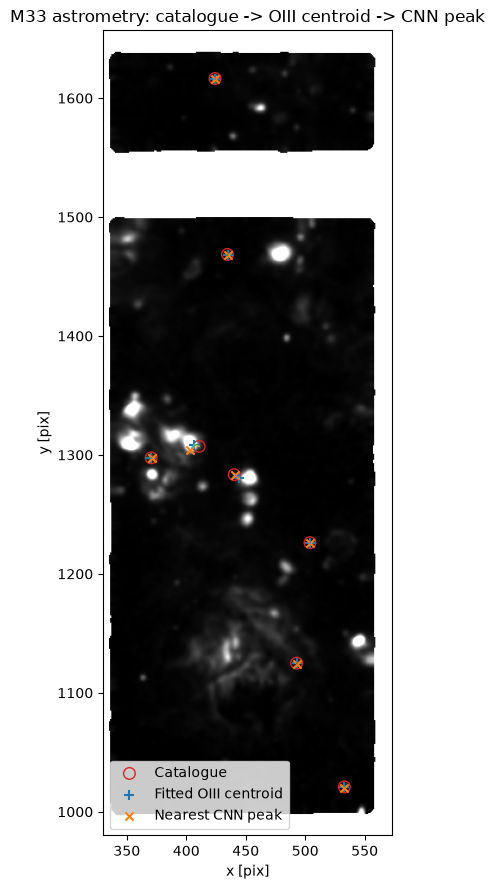

In [172]:
# Independent OIII centroid fit at every covered catalogue position.
centroid_rows = []
for _, r in catalog_in_image.iterrows():
    fit = fit_fixed_beta_moffat(oiii_flux, oiii_err, float(r["x"]), float(r["y"]))
    rec = r.to_dict()
    rec.update(fit)
    rec["catalog_x_original"] = float(r["x"])
    rec["catalog_y_original"] = float(r["y"])
    rec["catalog_to_moffat_dx_pix"] = (fit["moffat_x"] - float(r["x"])) if fit.get("moffat_success", False) else np.nan
    rec["catalog_to_moffat_dy_pix"] = (fit["moffat_y"] - float(r["y"])) if fit.get("moffat_success", False) else np.nan
    rec["catalog_to_moffat_distance_pix"] = (
        np.hypot(rec["catalog_to_moffat_dx_pix"], rec["catalog_to_moffat_dy_pix"])
        if fit.get("moffat_success", False) else np.nan
    )
    rec["catalog_to_moffat_distance_arcsec"] = rec["catalog_to_moffat_distance_pix"] * PIXEL_SCALE_ARCSEC
    centroid_rows.append(rec)

catalog_centroid_fits = pd.DataFrame(centroid_rows)
fit_success = catalog_centroid_fits["moffat_success"].fillna(False).astype(bool)

print(f"Successful independent OIII centroid fits: {int(fit_success.sum())} / {len(catalog_centroid_fits)}")
centroid_cols = [c for c in [
    CATALOG_ID_COLUMN, "catalog_x_original", "catalog_y_original",
    "moffat_x", "moffat_y", "catalog_to_moffat_dx_pix", "catalog_to_moffat_dy_pix",
    "catalog_to_moffat_distance_pix", "catalog_to_moffat_distance_arcsec",
    "moffat_fwhm_pix", "moffat_reduced_chi2", "moffat_success"
] if c is not None]
display(catalog_centroid_fits[centroid_cols])

catalog_centroid_fits.to_csv(OUTPUT_DIR / "M33_catalogue_to_OIII_centroid.csv", index=False)

if fit_success.any():
    fitted = catalog_centroid_fits.loc[fit_success].copy()
    print("\nCatalogue -> fitted OIII centroid offsets:")
    print(f"median dx = {np.nanmedian(fitted['catalog_to_moffat_dx_pix']):+.3f} pix")
    print(f"median dy = {np.nanmedian(fitted['catalog_to_moffat_dy_pix']):+.3f} pix")
    print(f"median separation = {np.nanmedian(fitted['catalog_to_moffat_distance_pix']):.3f} pix")

    # match_catalog_to_detections expects columns x,y; replace only in this copy.
    centroid_reference = fitted.copy()
    centroid_reference["x"] = centroid_reference["moffat_x"]
    centroid_reference["y"] = centroid_reference["moffat_y"]

    centroid_recovery_rows = []
    for tolerance in MATCH_TOLERANCE_GRID:
        m, miss, un = match_catalog_to_detections(centroid_reference, detections, float(tolerance))
        centroid_recovery_rows.append({
            "tolerance_pix": float(tolerance),
            "n_fitted_centroids": len(centroid_reference),
            "n_centroid_matched": len(m),
            "n_centroid_missed": len(miss),
            "centroid_completeness": len(m) / len(centroid_reference) if len(centroid_reference) else np.nan,
            "n_unmatched_candidates": len(un),
        })
    centroid_recovery_sweep = pd.DataFrame(centroid_recovery_rows)
    print("\nRecovery using independently fitted OIII centroids:")
    display(centroid_recovery_sweep)

    matched_centroid, missed_centroid, _ = match_catalog_to_detections(
        centroid_reference, detections, MATCH_TOLERANCE
    )
    centroid_completeness = len(matched_centroid) / len(centroid_reference) if len(centroid_reference) else np.nan
    print(f"Centroid-refined completeness at {MATCH_TOLERANCE:.1f} pix: {100*centroid_completeness:.1f}% "
          f"({len(matched_centroid)}/{len(centroid_reference)})")

    # Nearest CNN peak to each fitted OIII centroid.
    centroid_nearest = nearest_detection_offsets(centroid_reference, detections)
    centroid_nearest["catalog_x_original"] = centroid_reference["catalog_x_original"].to_numpy()
    centroid_nearest["catalog_y_original"] = centroid_reference["catalog_y_original"].to_numpy()
    compare_cols = [c for c in [
        CATALOG_ID_COLUMN, "catalog_x_original", "catalog_y_original", "moffat_x", "moffat_y",
        "catalog_to_moffat_dx_pix", "catalog_to_moffat_dy_pix",
        "nearest_det_x", "nearest_det_y", "nearest_dx_pix", "nearest_dy_pix",
        "nearest_distance_pix", "nearest_det_score"
    ] if c is not None]
    print("\nCatalogue -> OIII centroid -> nearest CNN peak:")
    display(centroid_nearest[compare_cols])
    centroid_nearest.to_csv(OUTPUT_DIR / "M33_OIII_centroid_to_nearest_CNN_peak.csv", index=False)

    # Visual astrometry check: catalogue coordinate -> fitted OIII centroid -> nearest CNN peak.
    xvals = centroid_reference["catalog_x_original"].to_numpy(float)
    yvals = centroid_reference["catalog_y_original"].to_numpy(float)
    margin = 40
    x0 = max(0, int(np.floor(np.nanmin(xvals))) - margin)
    x1 = min(oiii_flux.shape[1], int(np.ceil(np.nanmax(xvals))) + margin)
    y0 = max(0, int(np.floor(np.nanmin(yvals))) - margin)
    y1 = min(oiii_flux.shape[0], int(np.ceil(np.nanmax(yvals))) + margin)
    view = oiii_flux[y0:y1, x0:x1]
    finite_view = view[np.isfinite(view)]
    if finite_view.size:
        vmin, vmax = np.nanpercentile(finite_view, [5, 99.5])
        fig, ax = plt.subplots(figsize=(9, 9))
        ax.imshow(view, origin="lower", cmap="gray", vmin=vmin, vmax=vmax, extent=[x0, x1, y0, y1])
        for _, rr in centroid_nearest.iterrows():
            cx, cy = rr["catalog_x_original"], rr["catalog_y_original"]
            mx, my = rr["moffat_x"], rr["moffat_y"]
            dxp, dyp = rr["nearest_det_x"], rr["nearest_det_y"]
            ax.plot([cx, mx], [cy, my], "-", lw=1)
            ax.plot([mx, dxp], [my, dyp], "--", lw=1)
        ax.scatter(centroid_nearest["catalog_x_original"], centroid_nearest["catalog_y_original"],
                   s=70, facecolors="none", edgecolors="tab:red", label="Catalogue")
        ax.scatter(centroid_nearest["moffat_x"], centroid_nearest["moffat_y"],
                   s=45, marker="+", label="Fitted OIII centroid")
        ax.scatter(centroid_nearest["nearest_det_x"], centroid_nearest["nearest_det_y"],
                   s=35, marker="x", label="Nearest CNN peak")
        ax.set_xlabel("x [pix]")
        ax.set_ylabel("y [pix]")
        ax.set_title("M33 astrometry: catalogue -> OIII centroid -> CNN peak")
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    centroid_recovery_sweep = pd.DataFrame()
    print("No successful Moffat centroid fits; centroid-refined recovery was not computed.")


## Fixed score-stratified visual sample

In [173]:
visual_pool = diagnostic_table[
    diagnostic_table["population"].isin(["Recovered catalogue PN", "Unmatched candidate"])
    & (~diagnostic_table["edge_object"])
    & (diagnostic_table["network_score"] >= DIAGNOSTIC_THRESHOLD)
].copy()

visual_pool["visual_score_bin"] = pd.cut(
    visual_pool["network_score"],
    bins=SCORE_BIN_EDGES,
    labels=SCORE_BIN_LABELS,
    right=False,
    include_lowest=True,
)

sample_parts = []
for b_idx, score_bin in enumerate(SCORE_BIN_LABELS):
    for p_idx, population in enumerate(["Recovered catalogue PN", "Unmatched candidate"]):
        subset = visual_pool[
            (visual_pool["visual_score_bin"] == score_bin)
            & (visual_pool["population"] == population)
        ]
        n = min(VISUAL_N_PER_POP_PER_BIN, len(subset))
        if n > 0:
            sample_parts.append(
                subset.sample(n=n, replace=False, random_state=VISUAL_SEED + 100*b_idx + p_idx)
            )

visual_sample = pd.concat(sample_parts, ignore_index=True) if sample_parts else pd.DataFrame()
visual_sample.to_csv(OUTPUT_DIR / "visual_sample_M33_v4.5.csv", index=False)

display(pd.crosstab(visual_sample["population"], visual_sample["visual_score_bin"]))
print("Saved:", OUTPUT_DIR / "visual_sample_M33_v4.5.csv")


visual_score_bin,0.45-0.60,0.60-0.80,>=0.80
population,,,
Recovered catalogue PN,0,4,3
Unmatched candidate,25,25,6


Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/visual_sample_M33_v4.5.csv


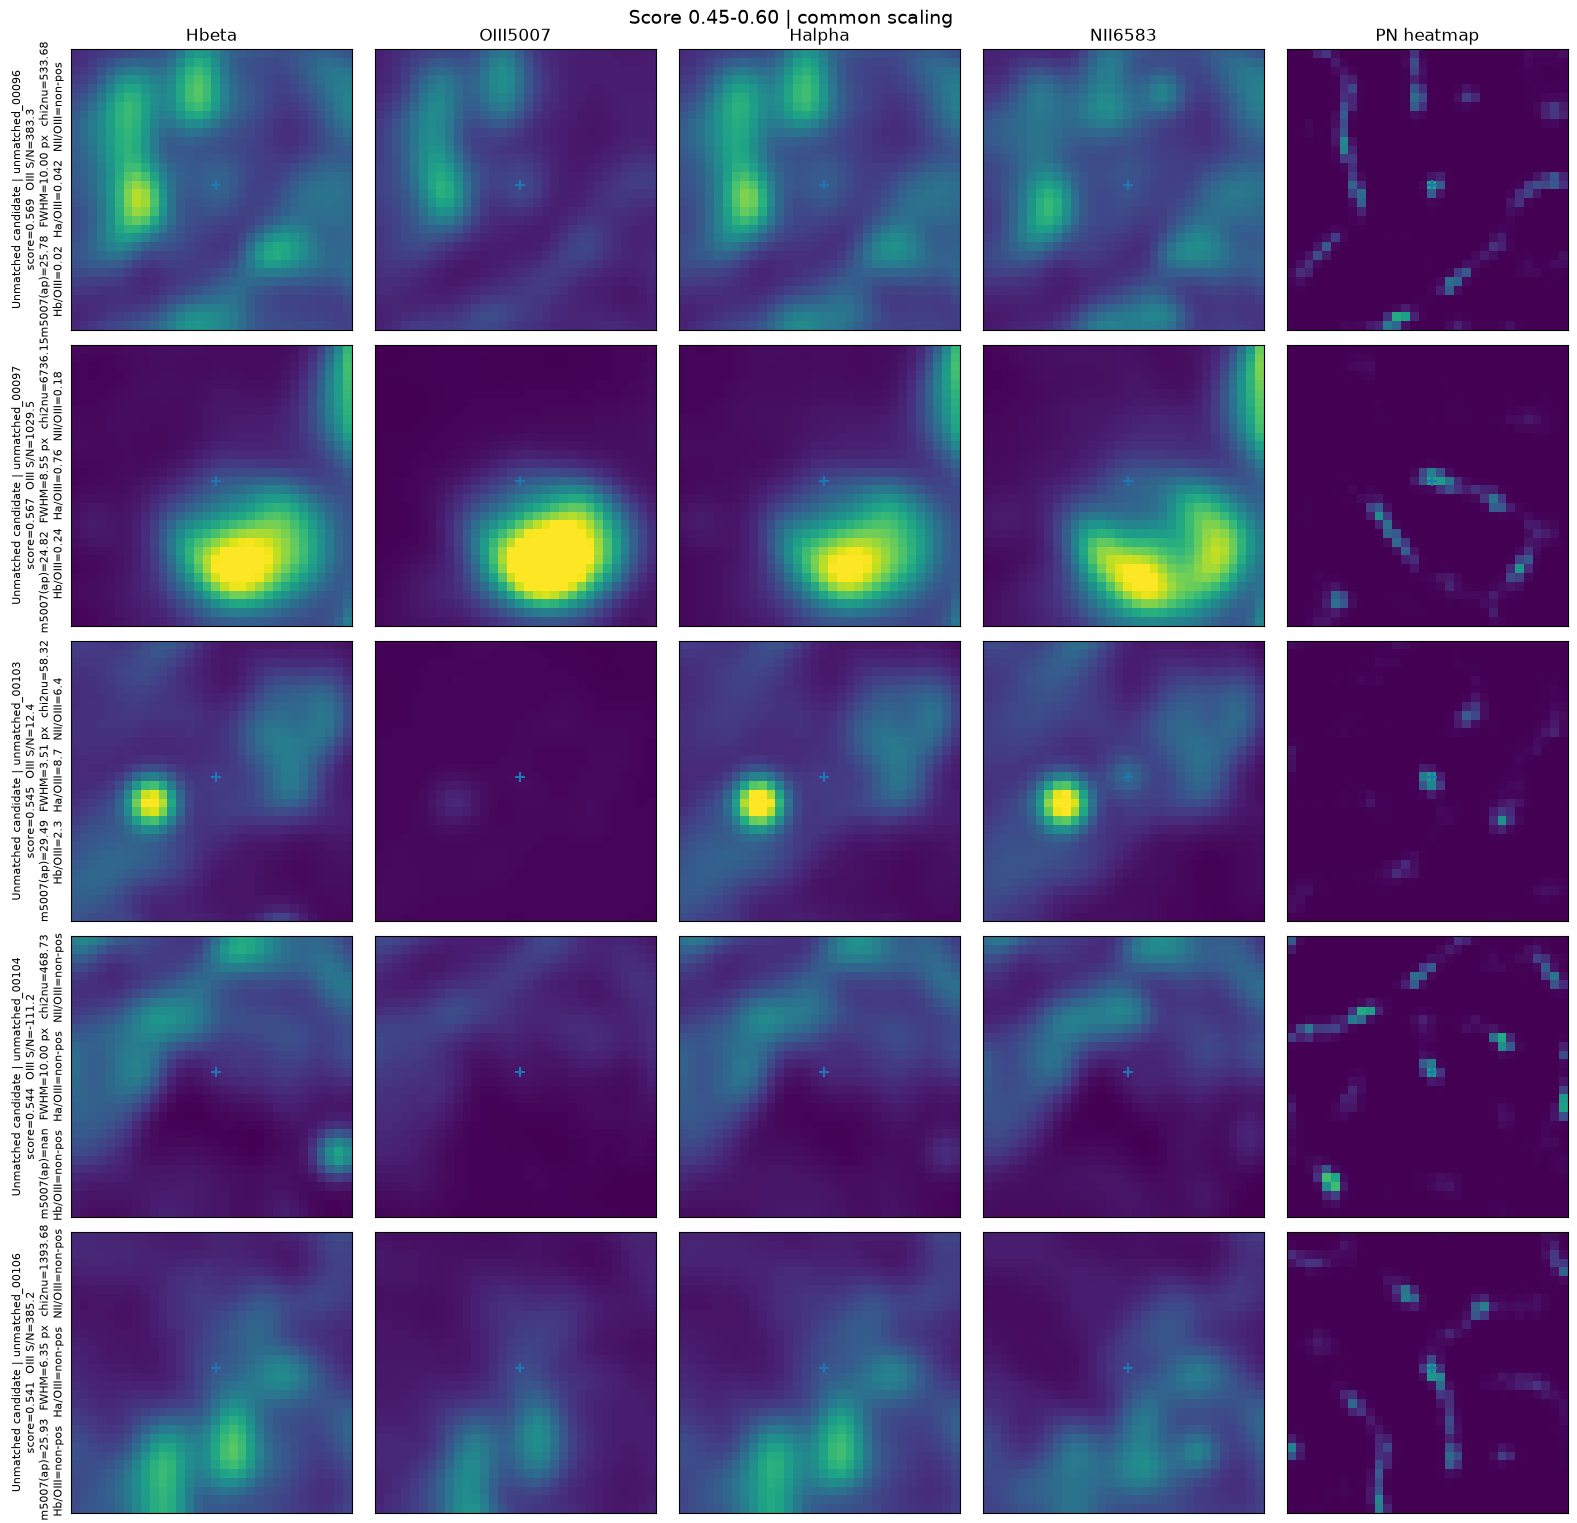

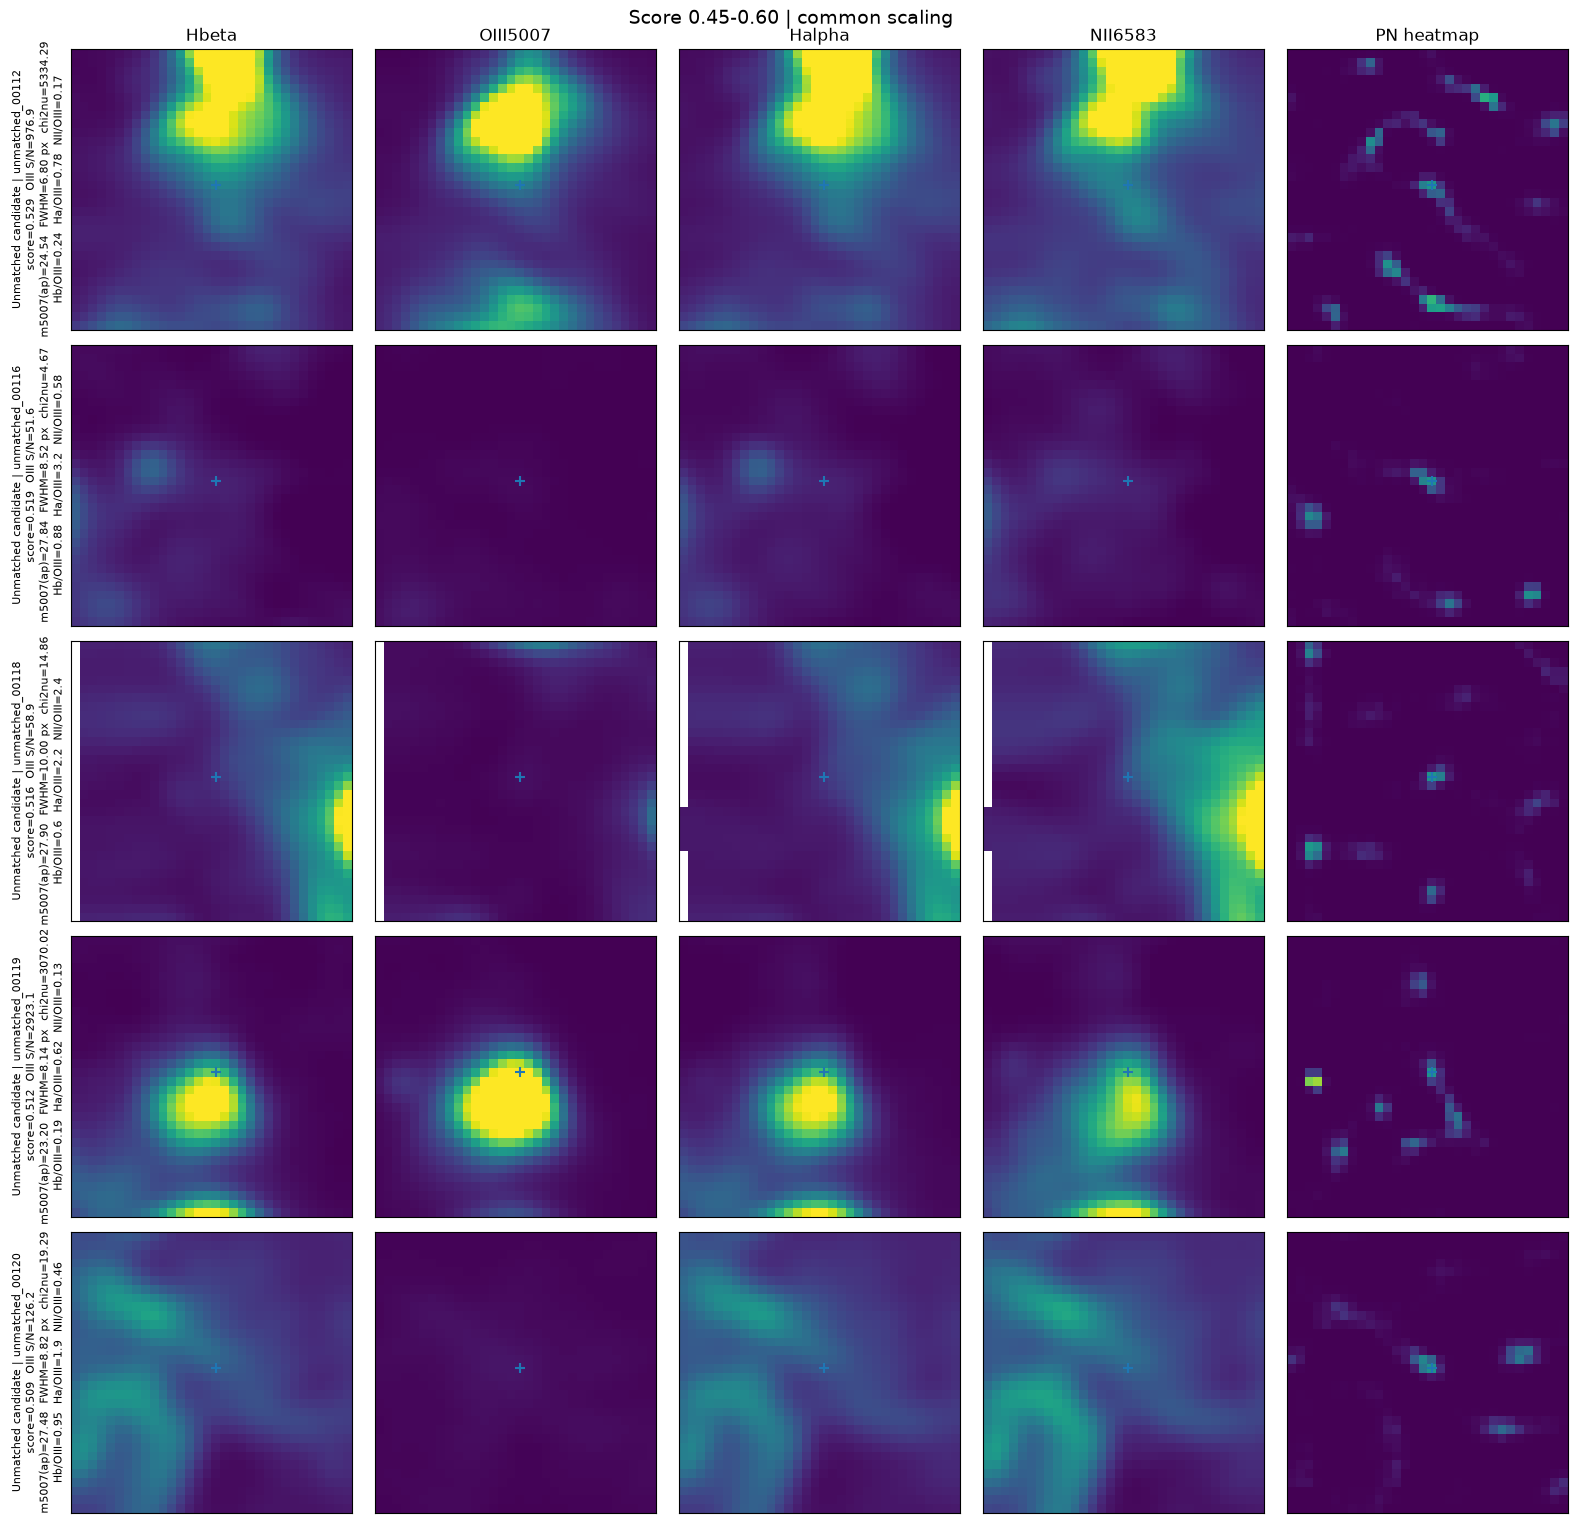

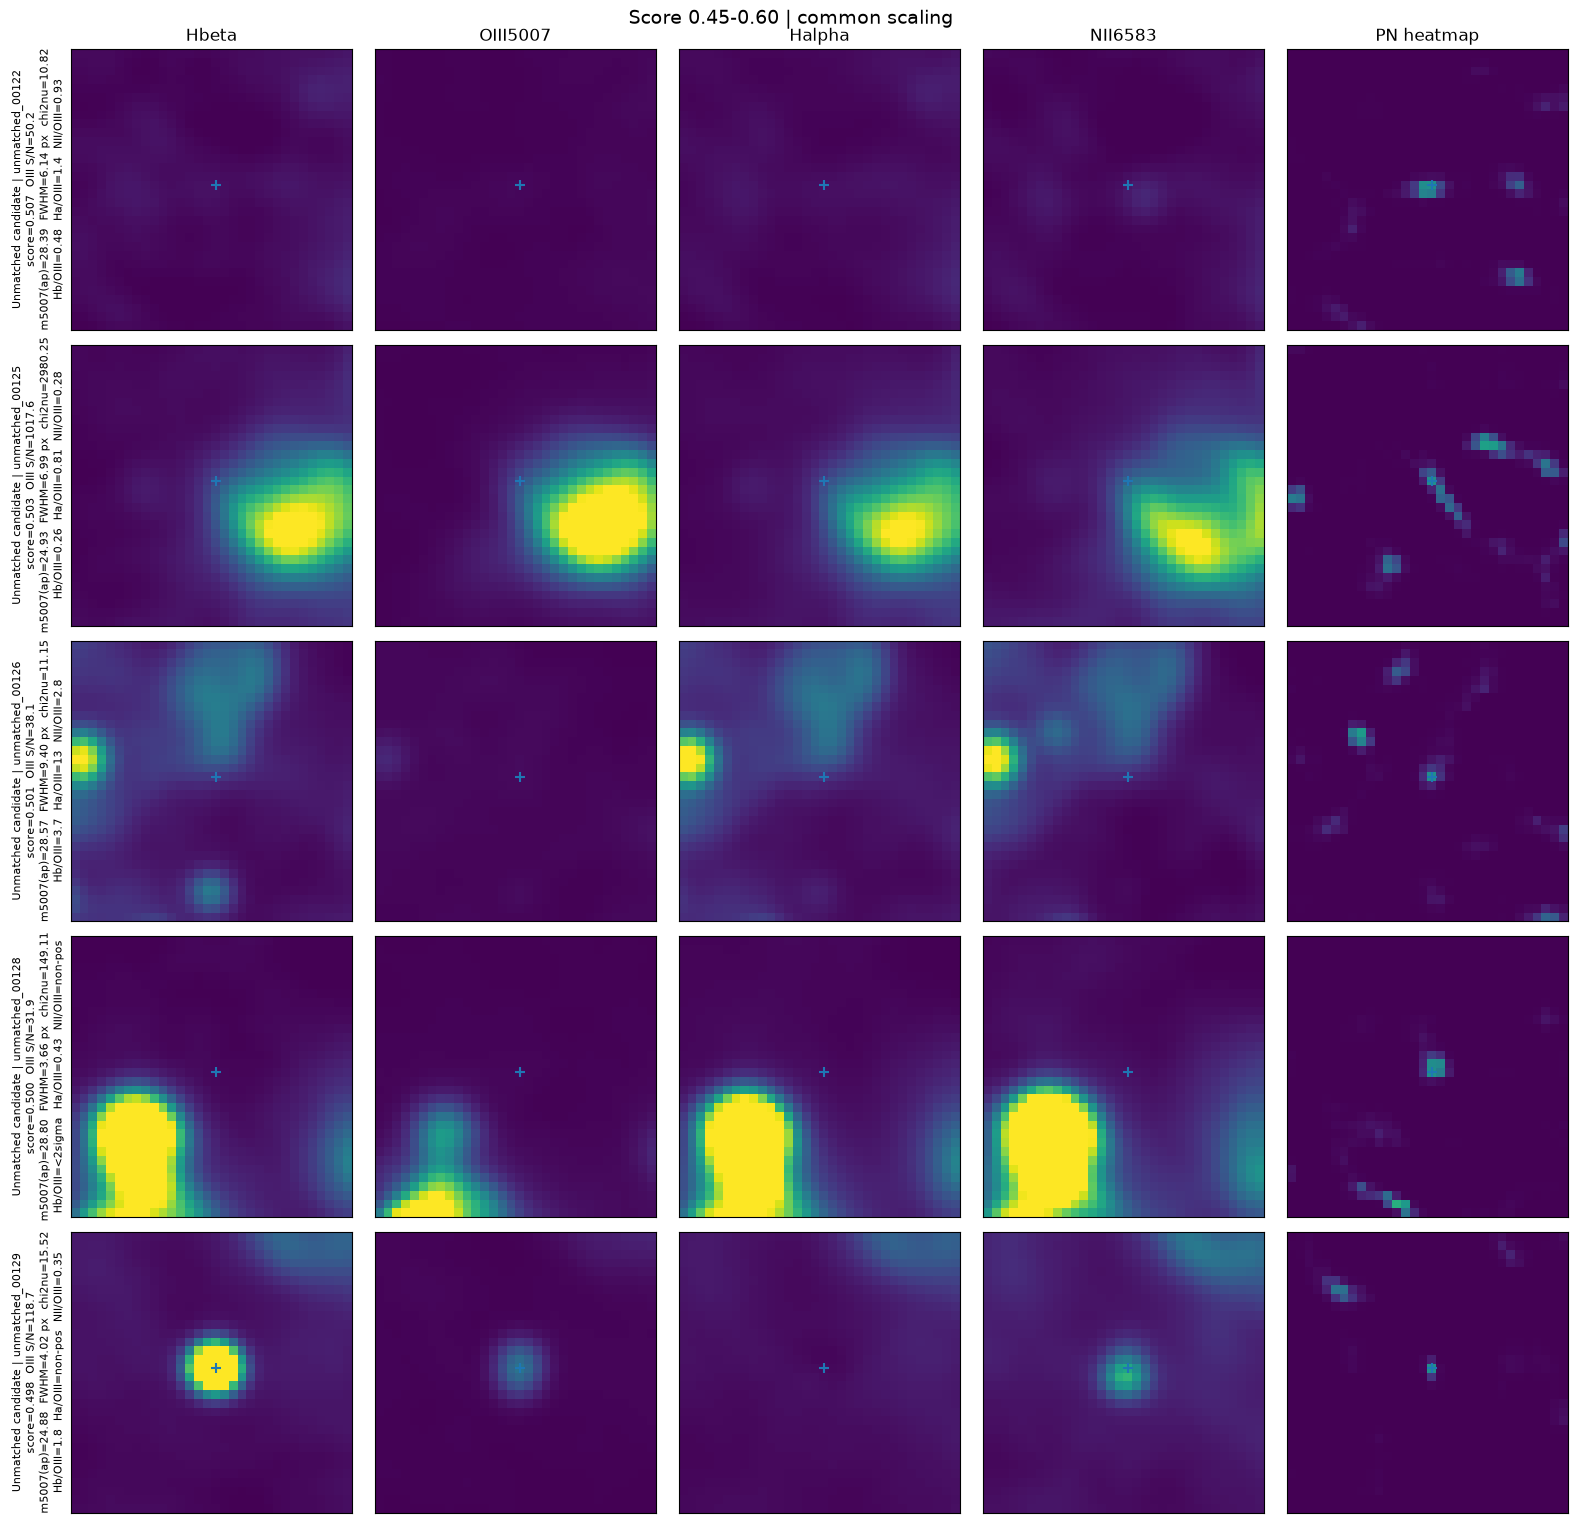

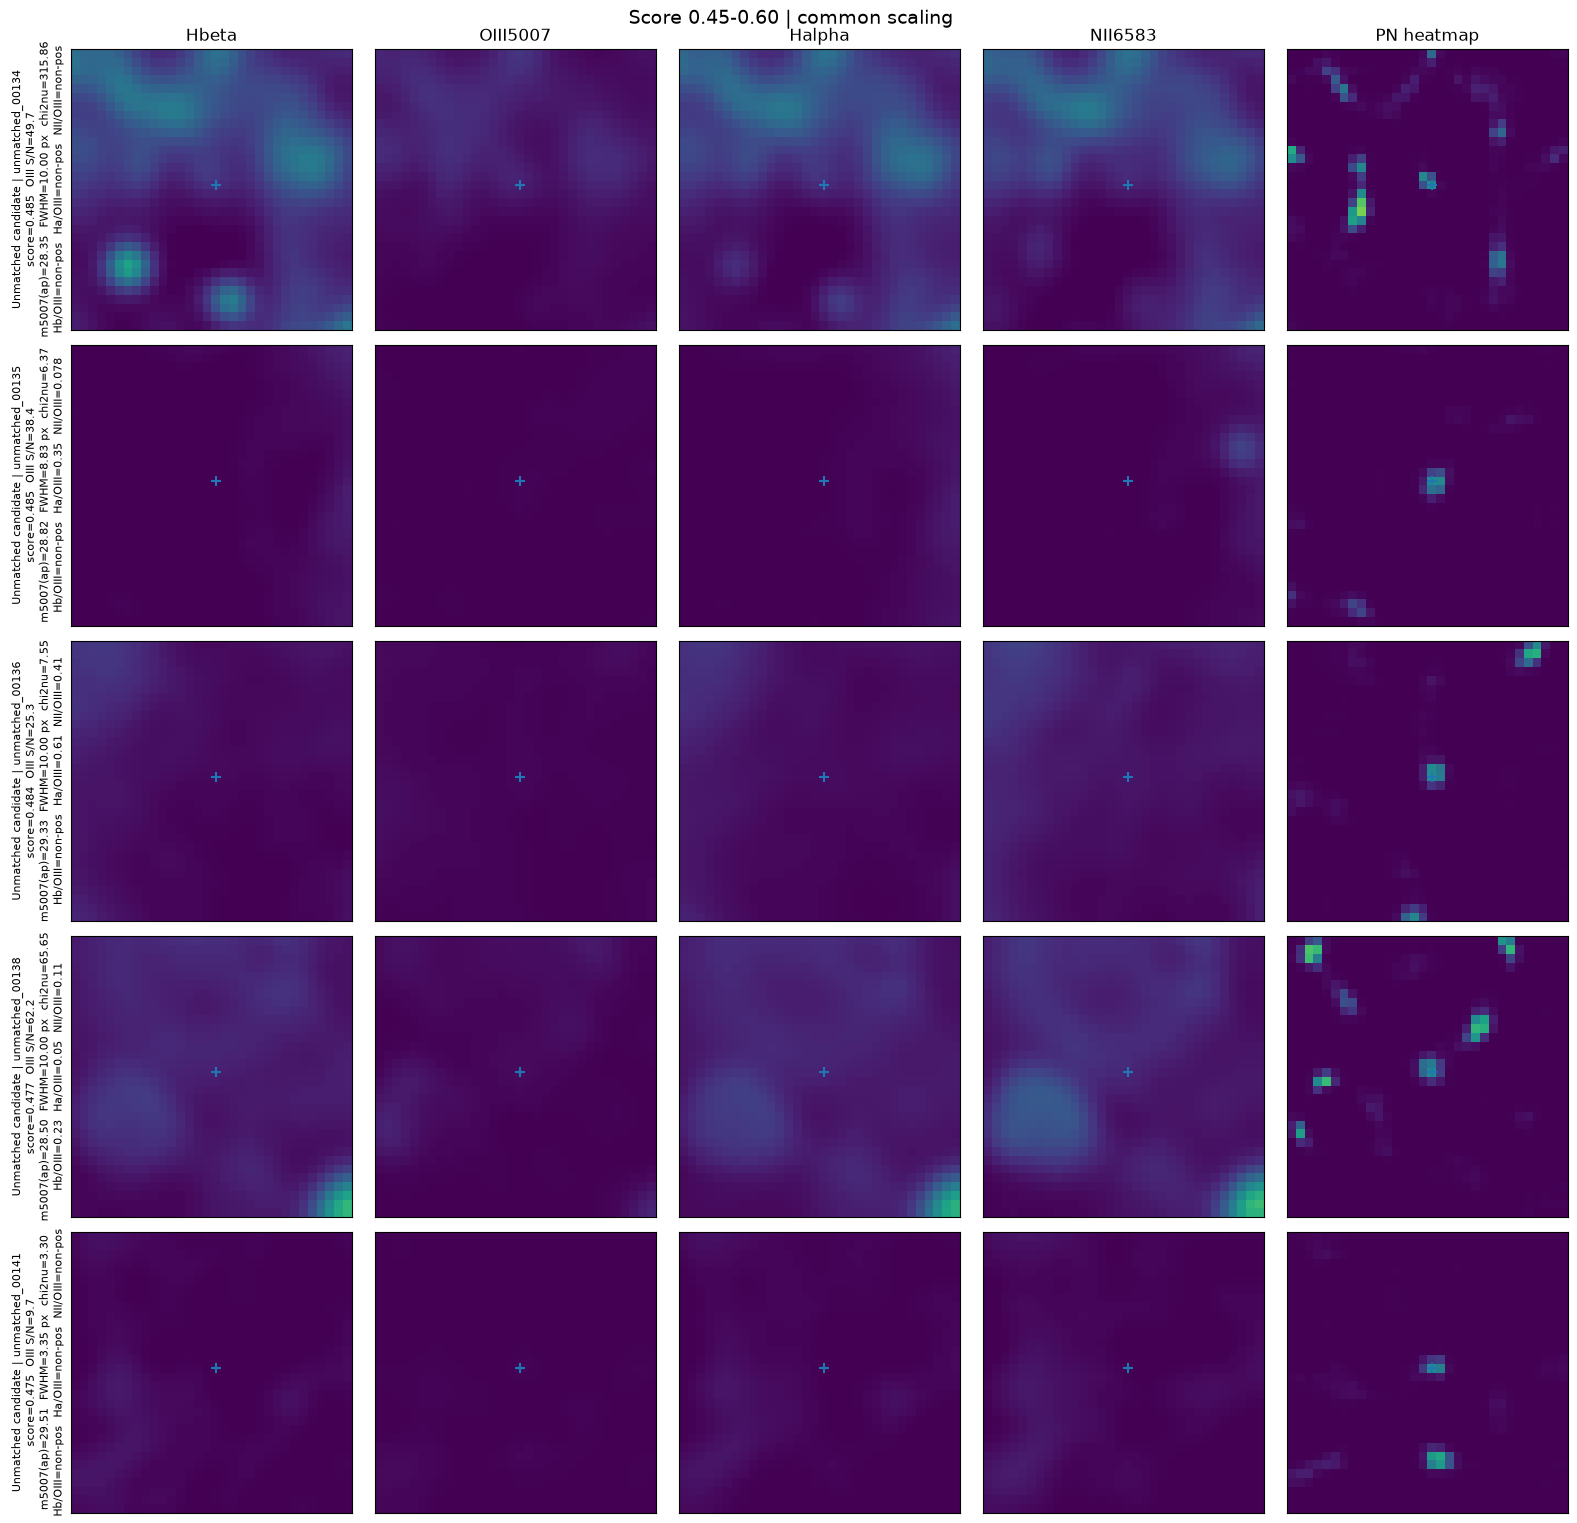

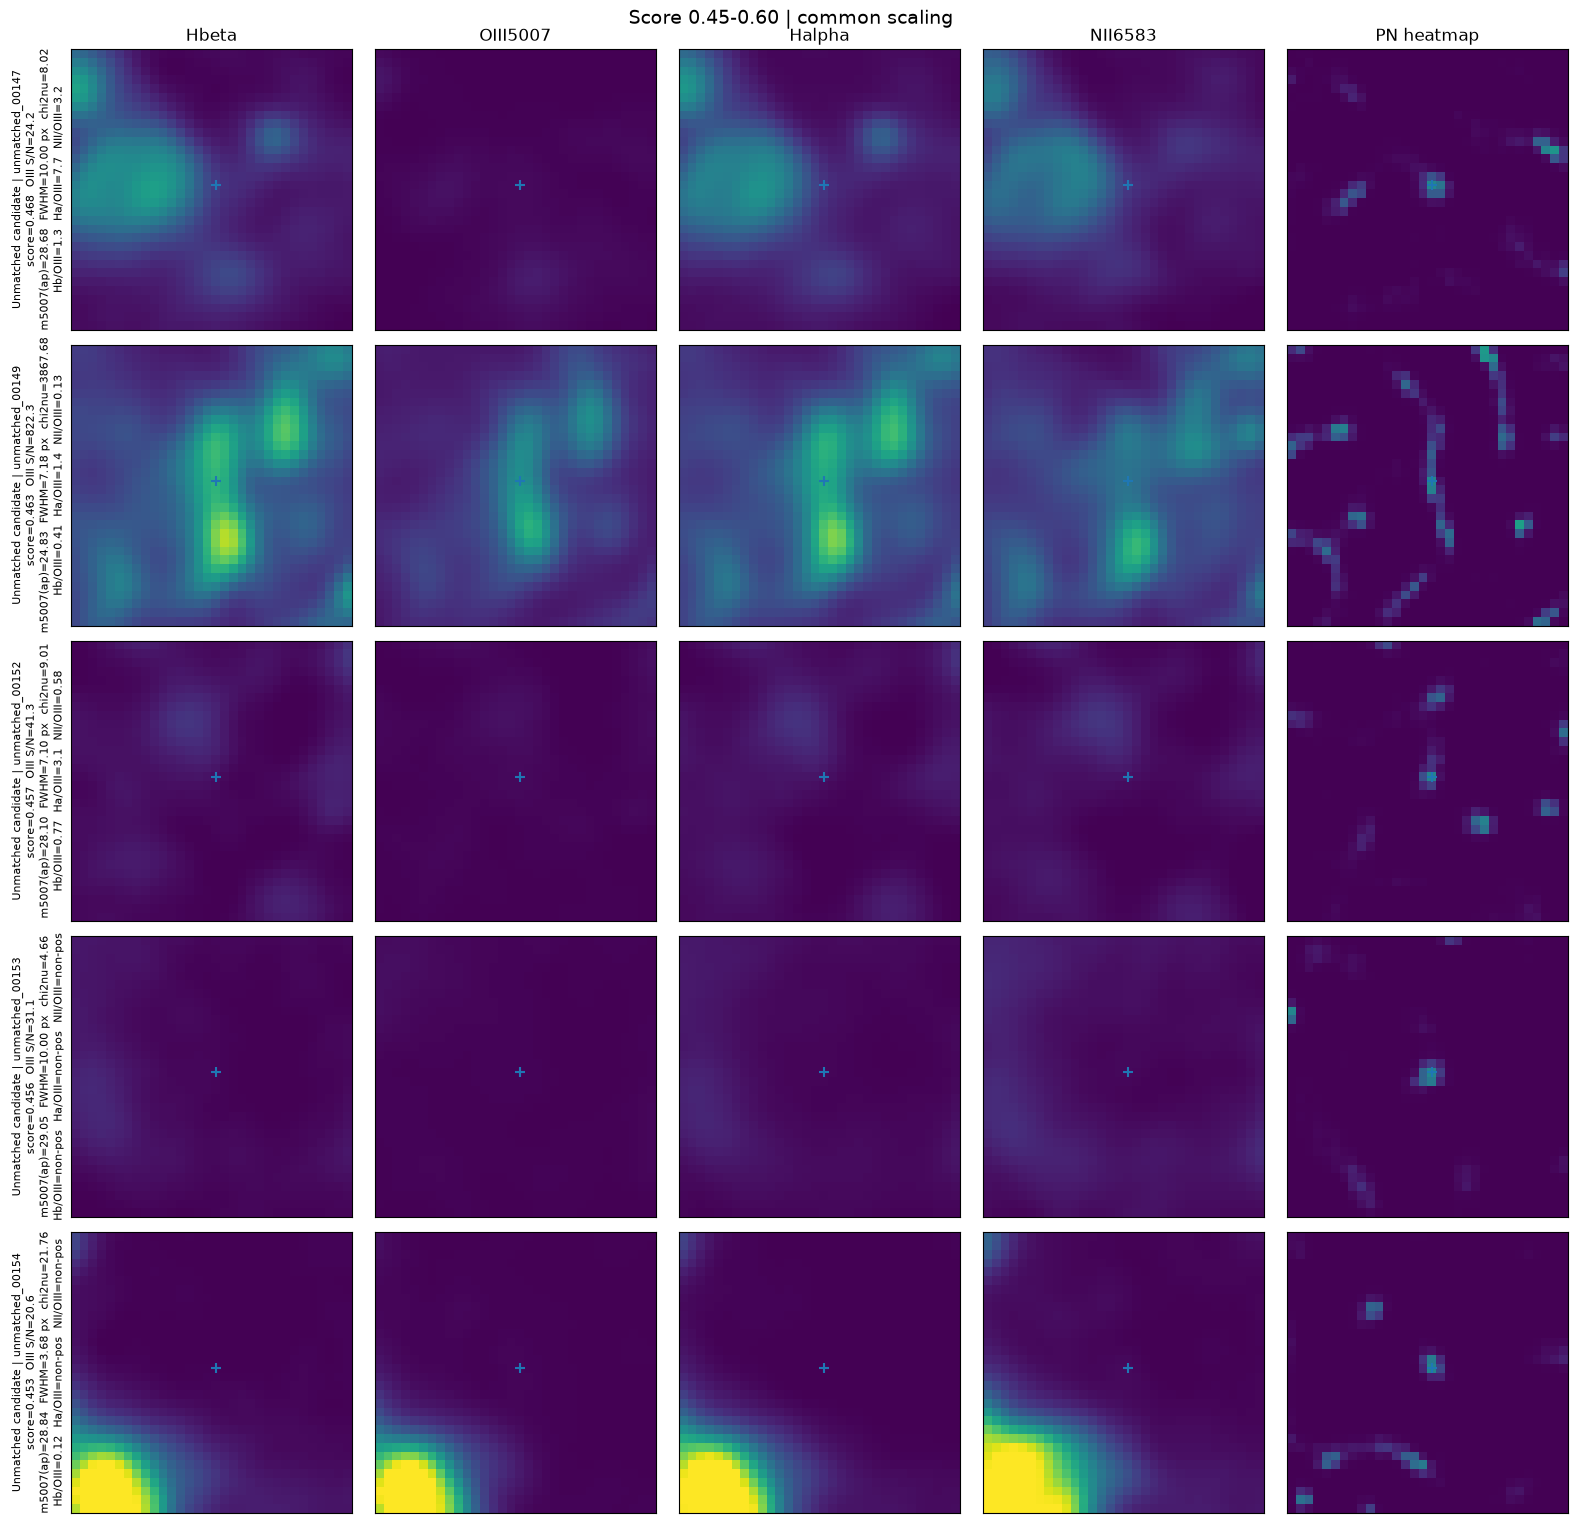

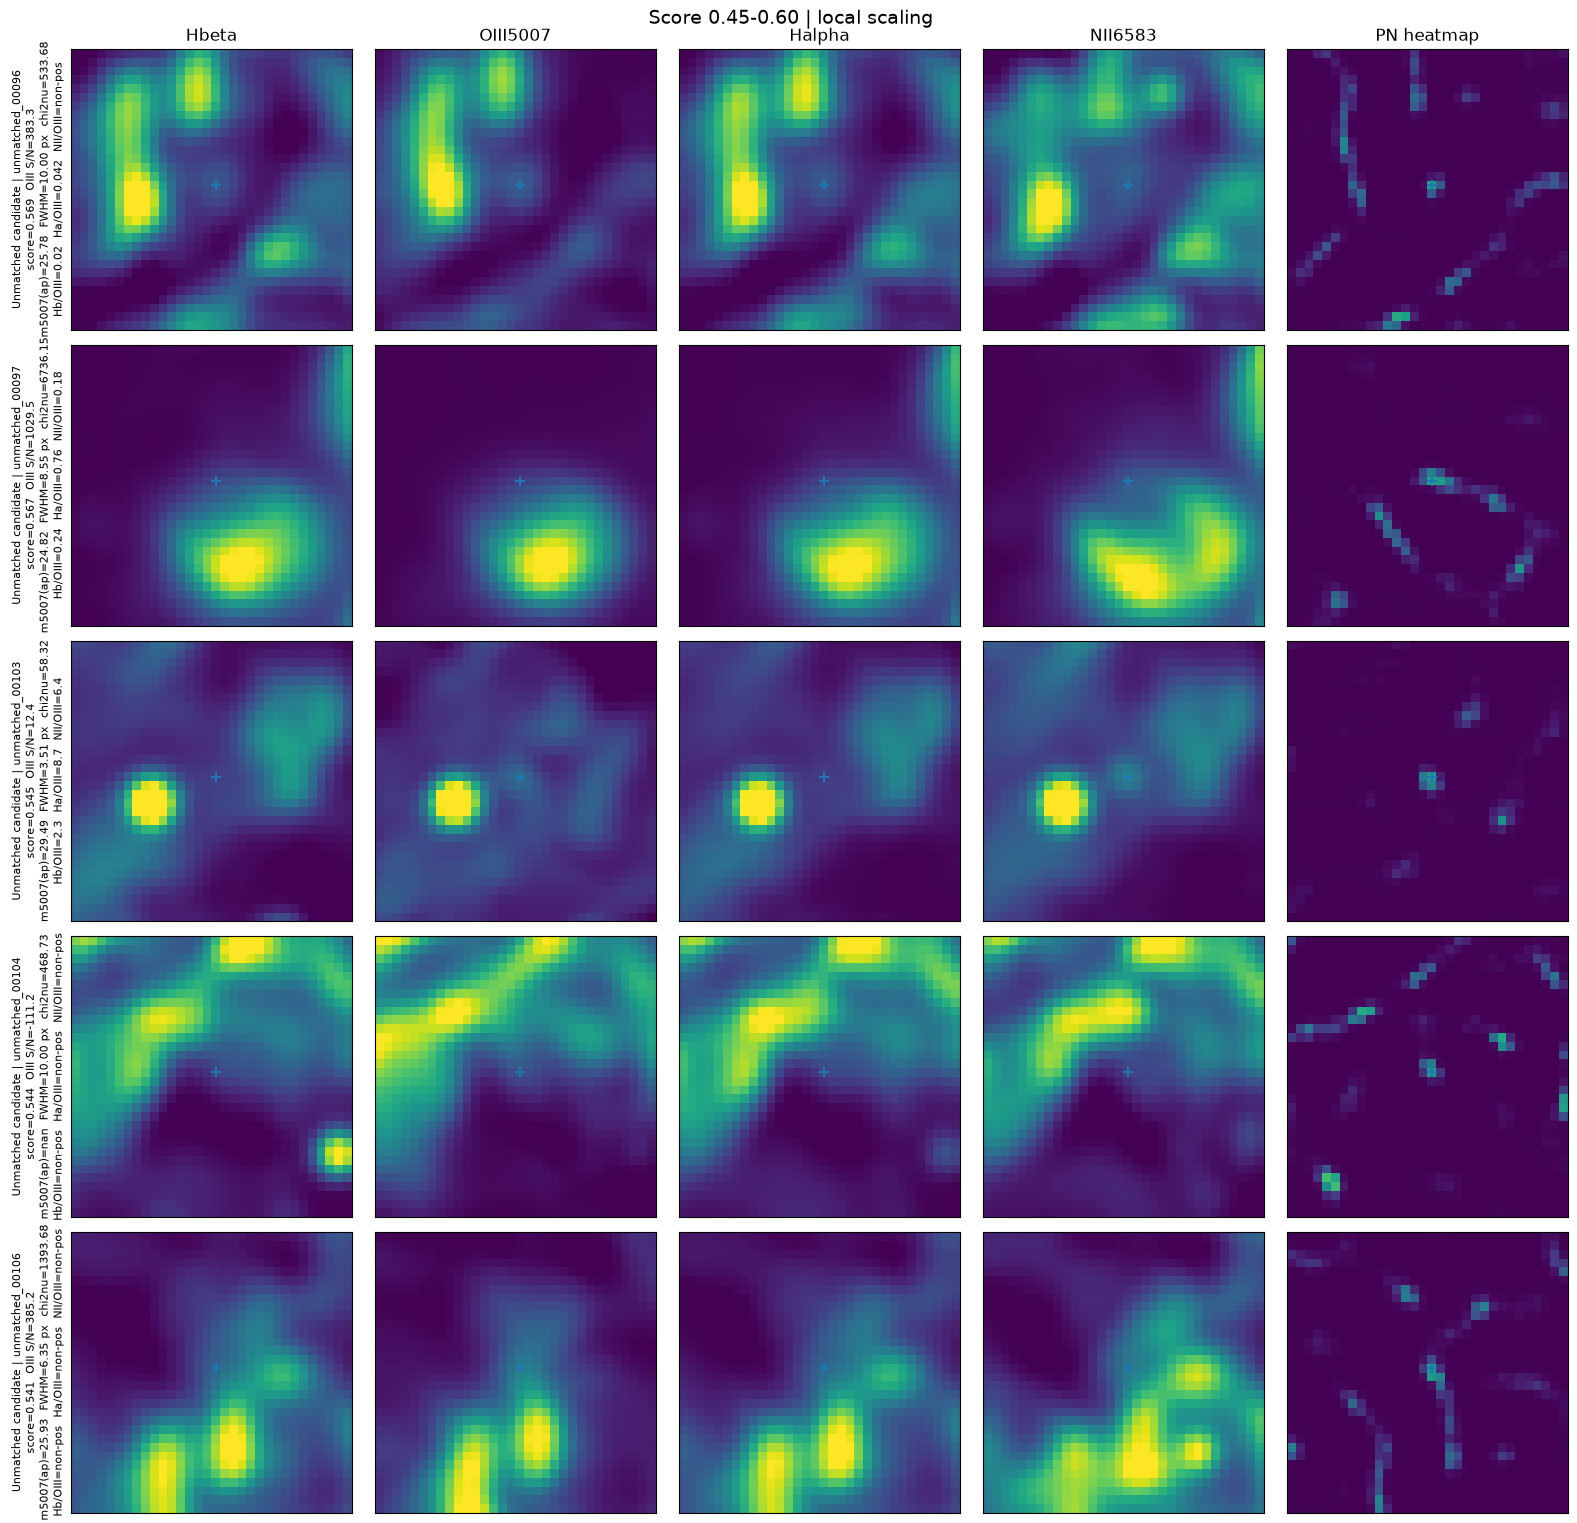

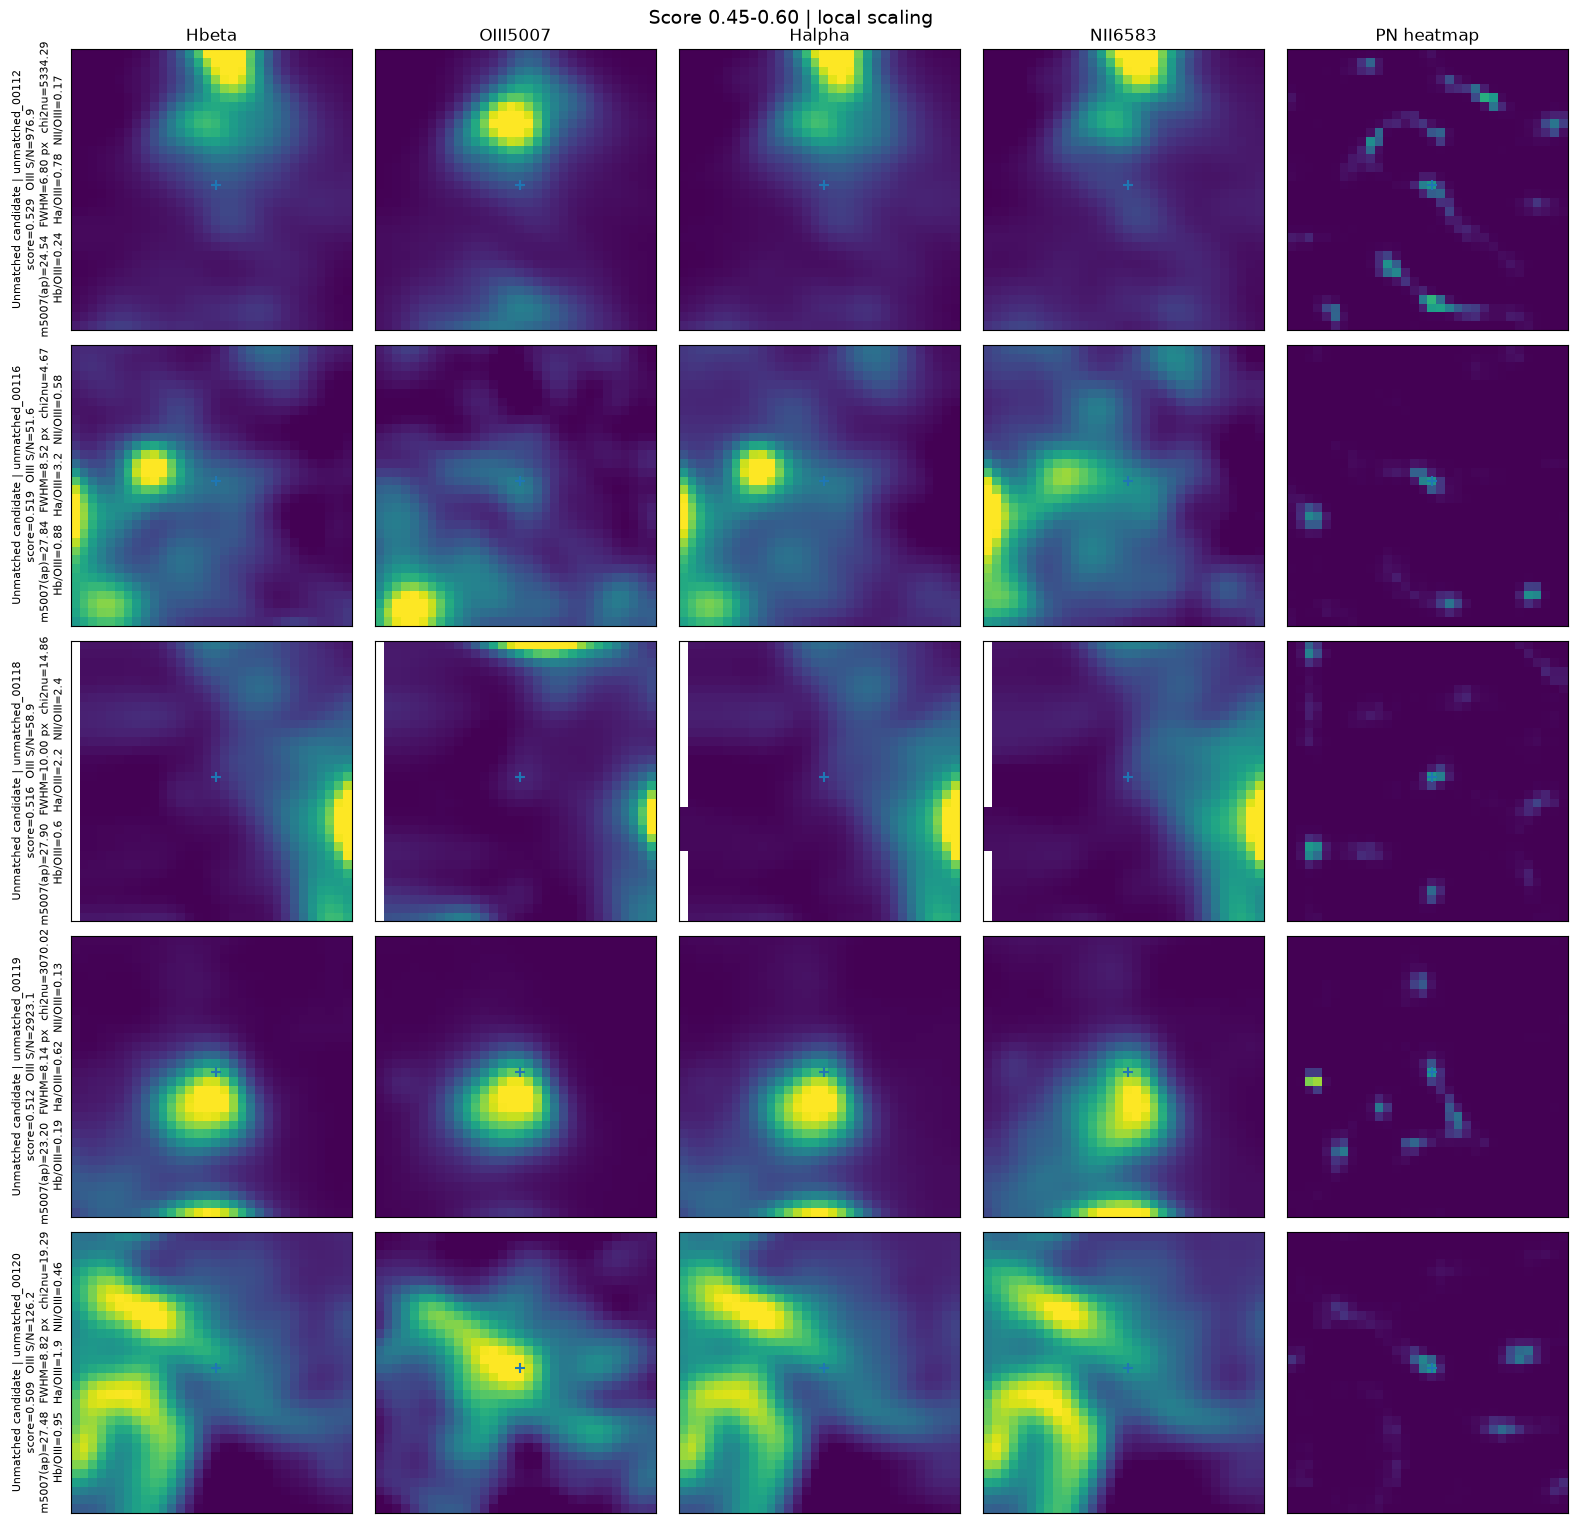

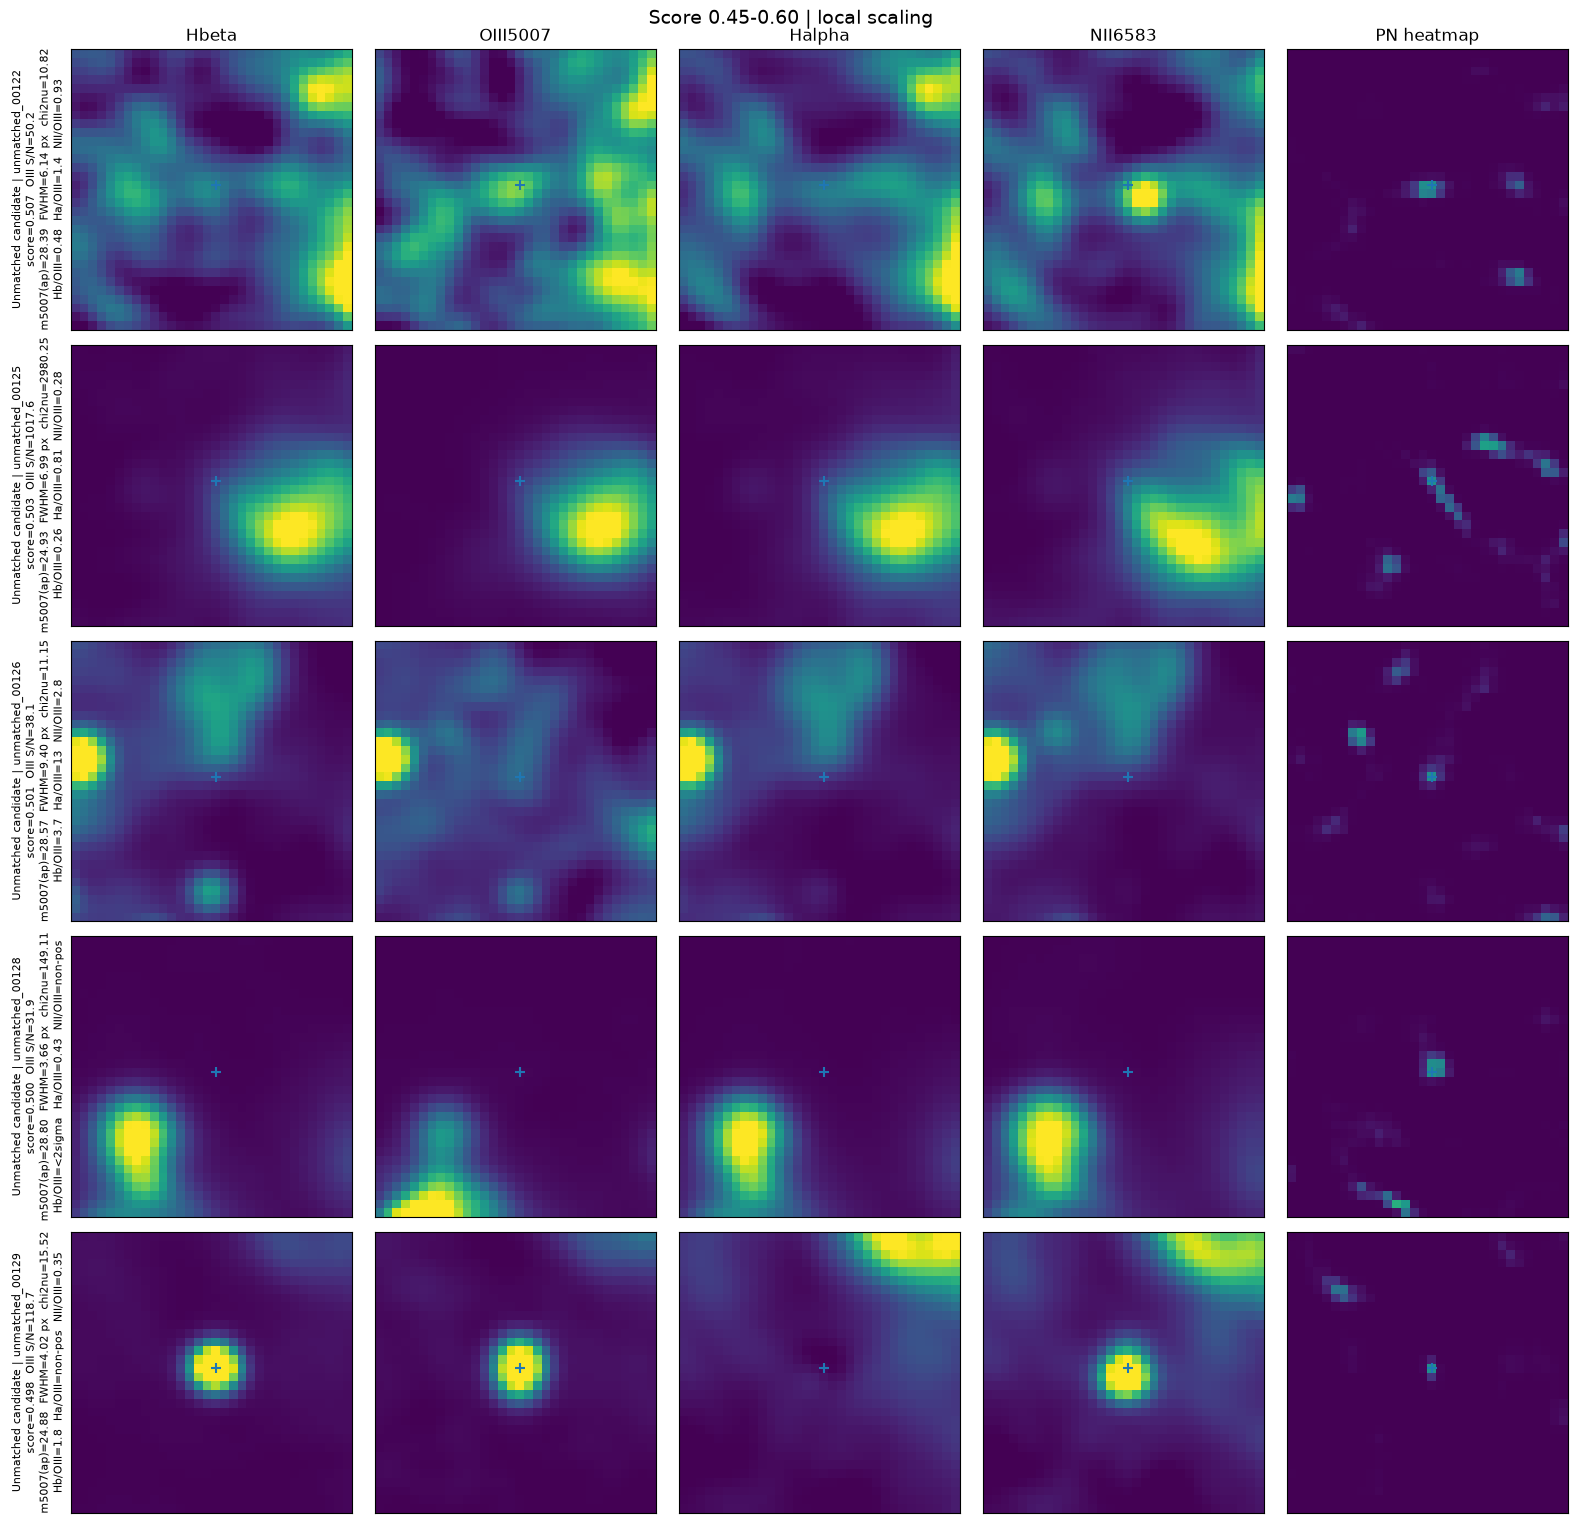

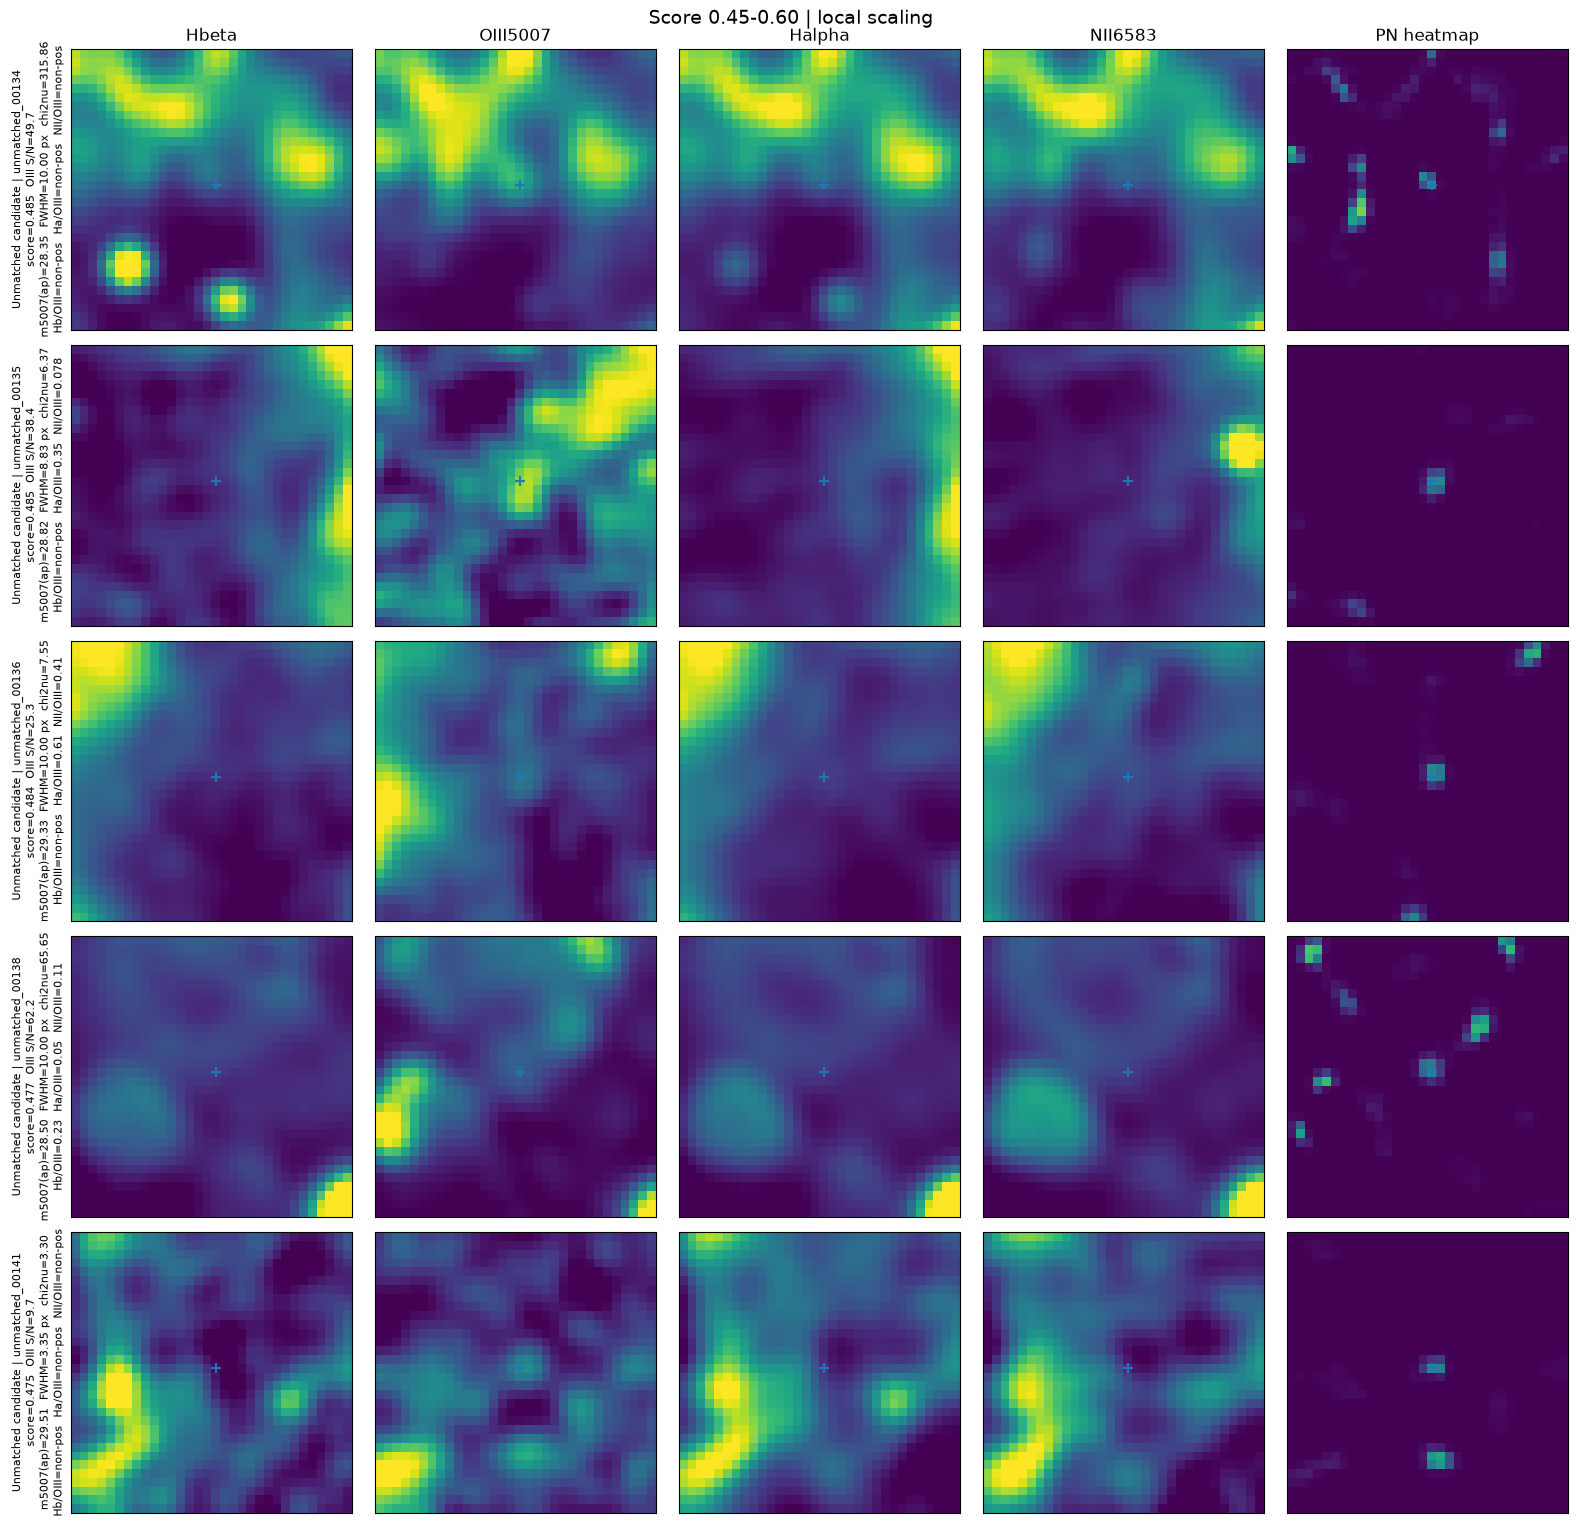

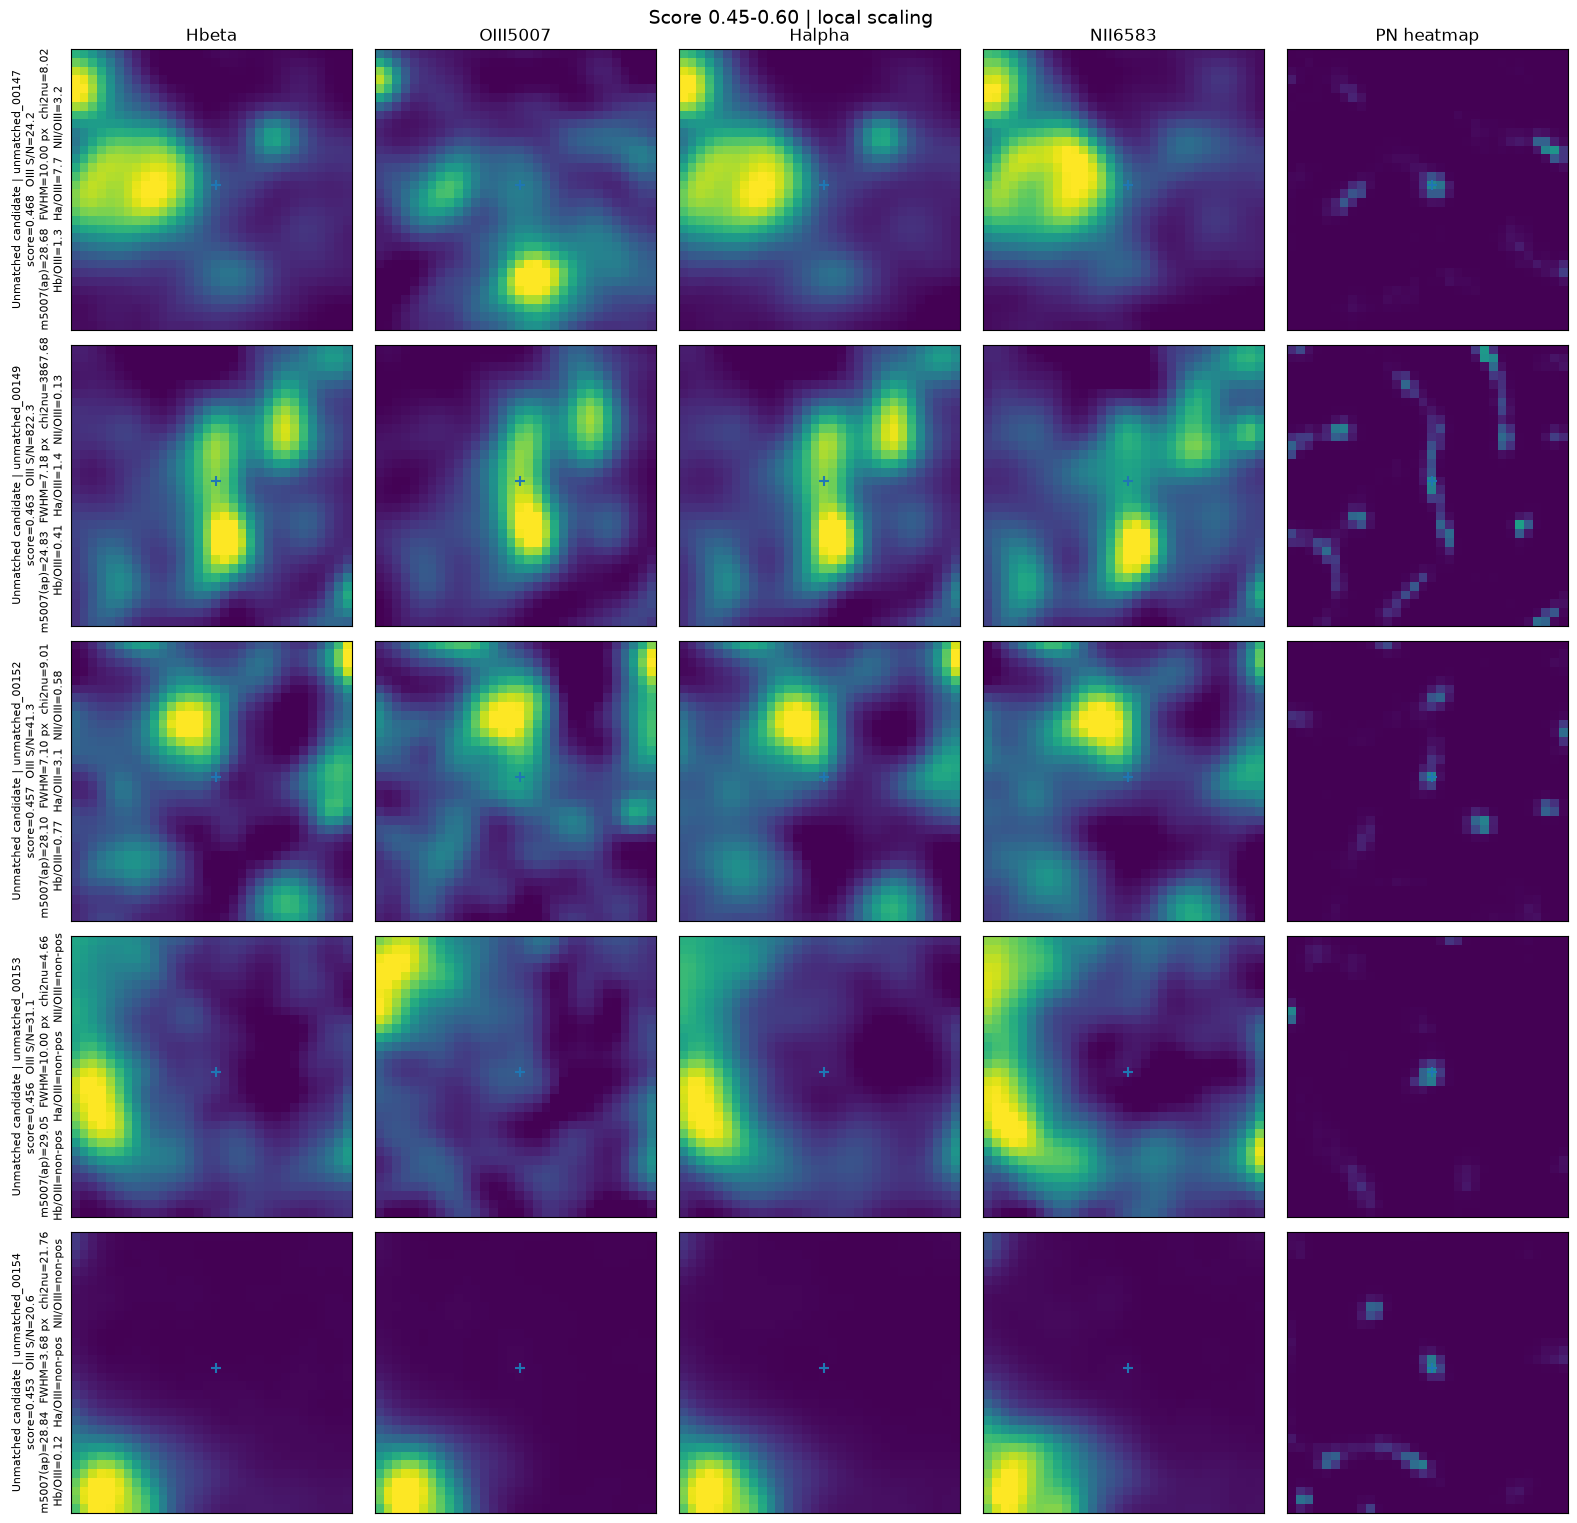

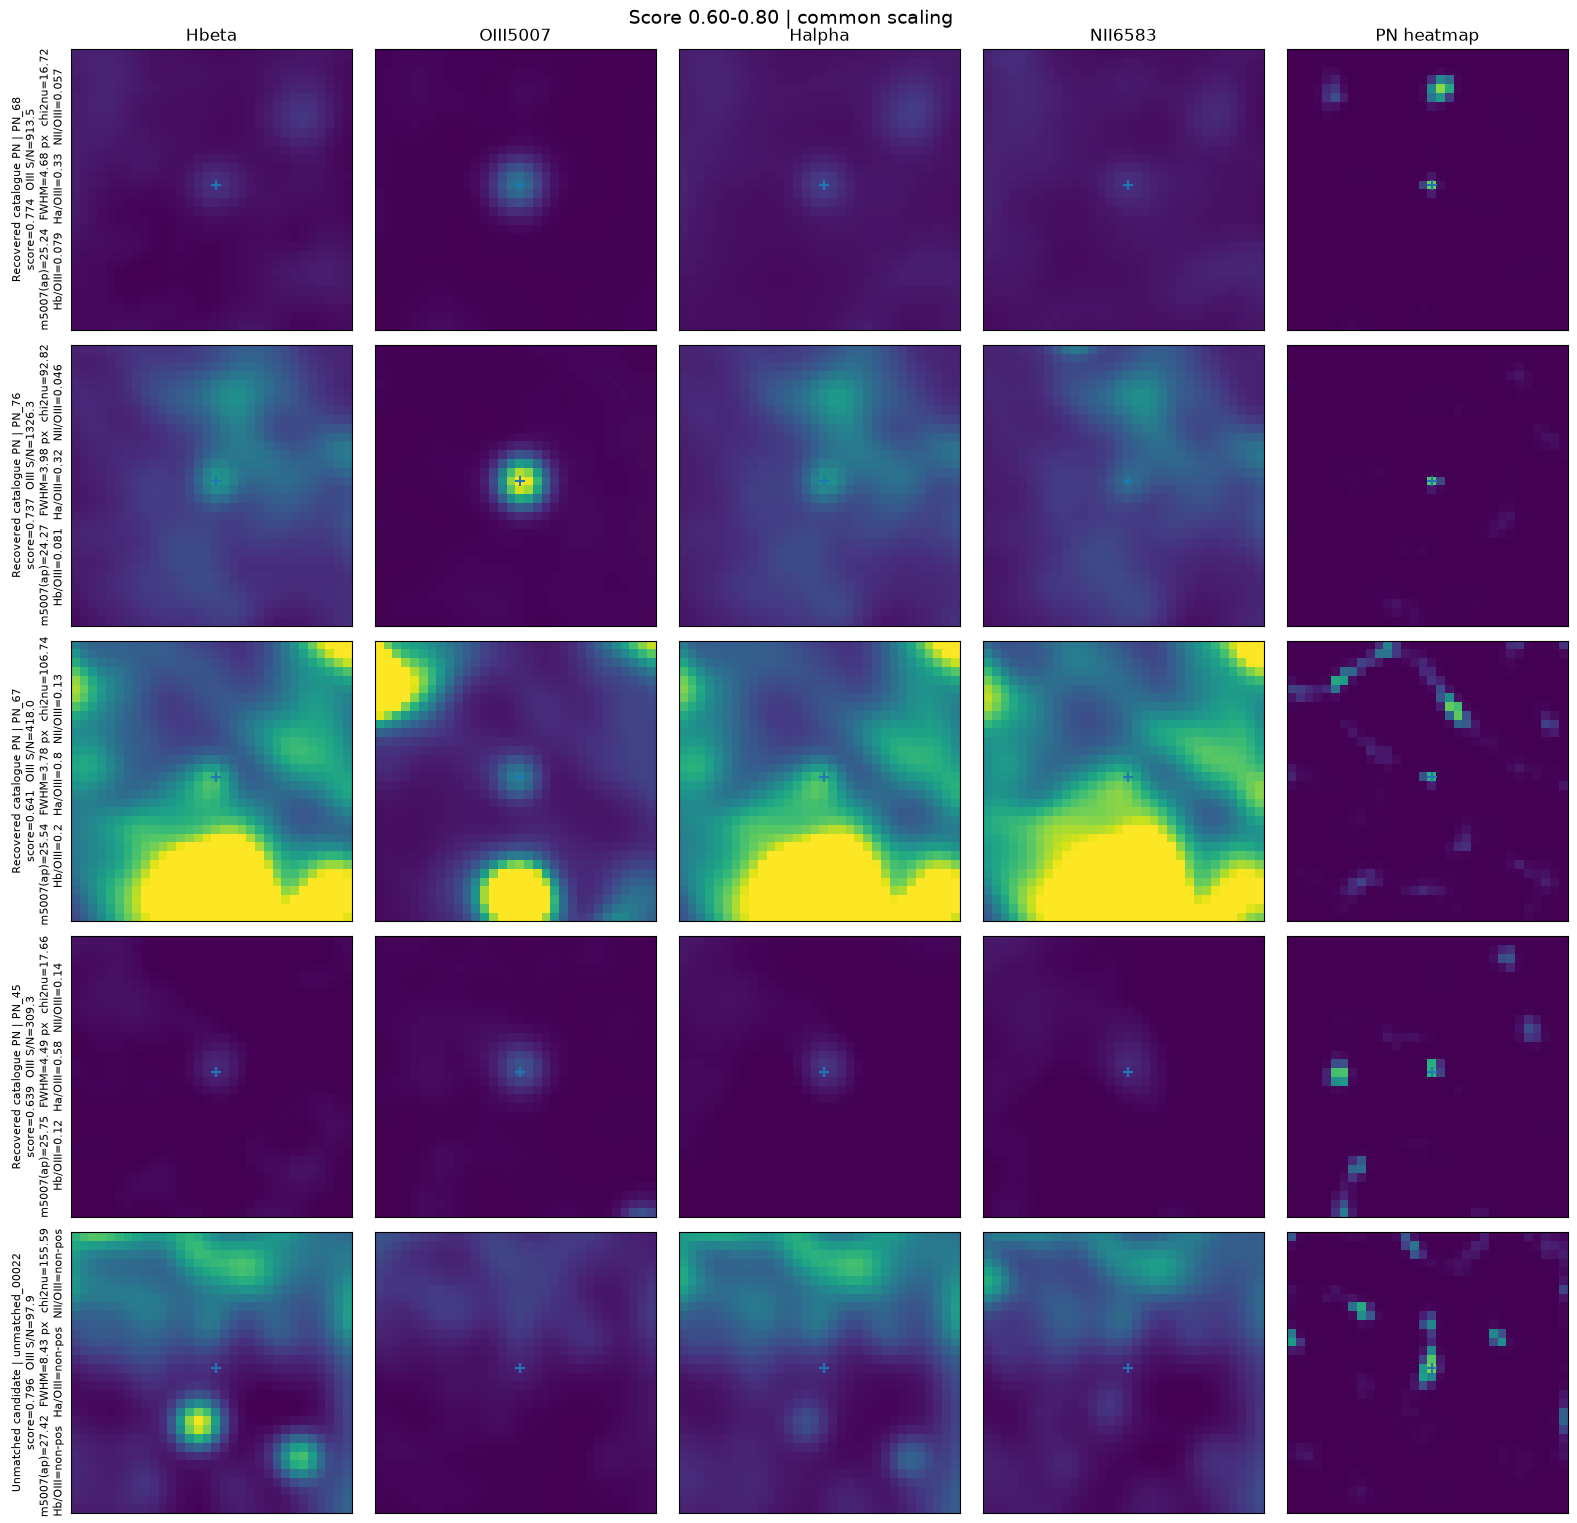

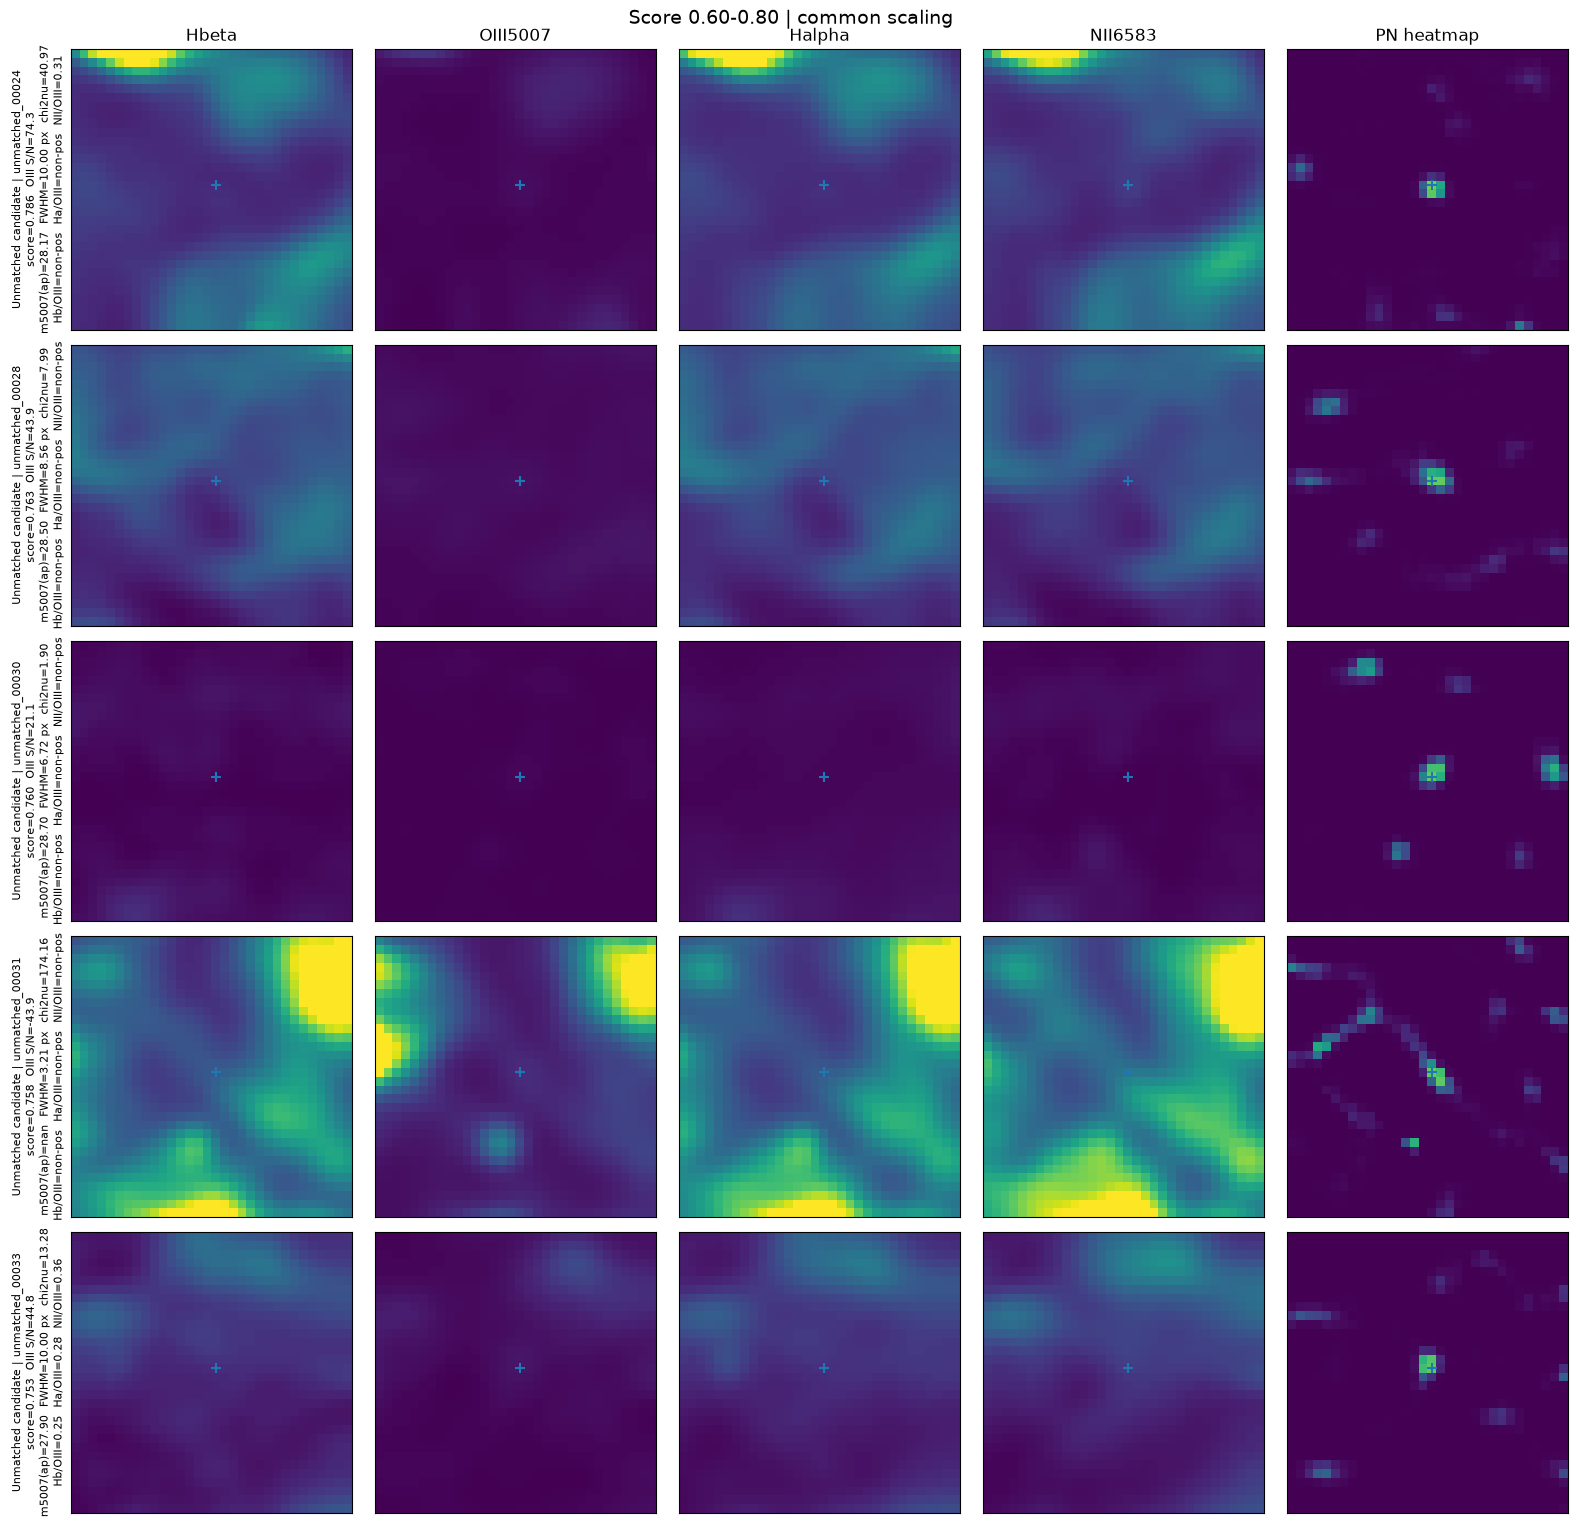

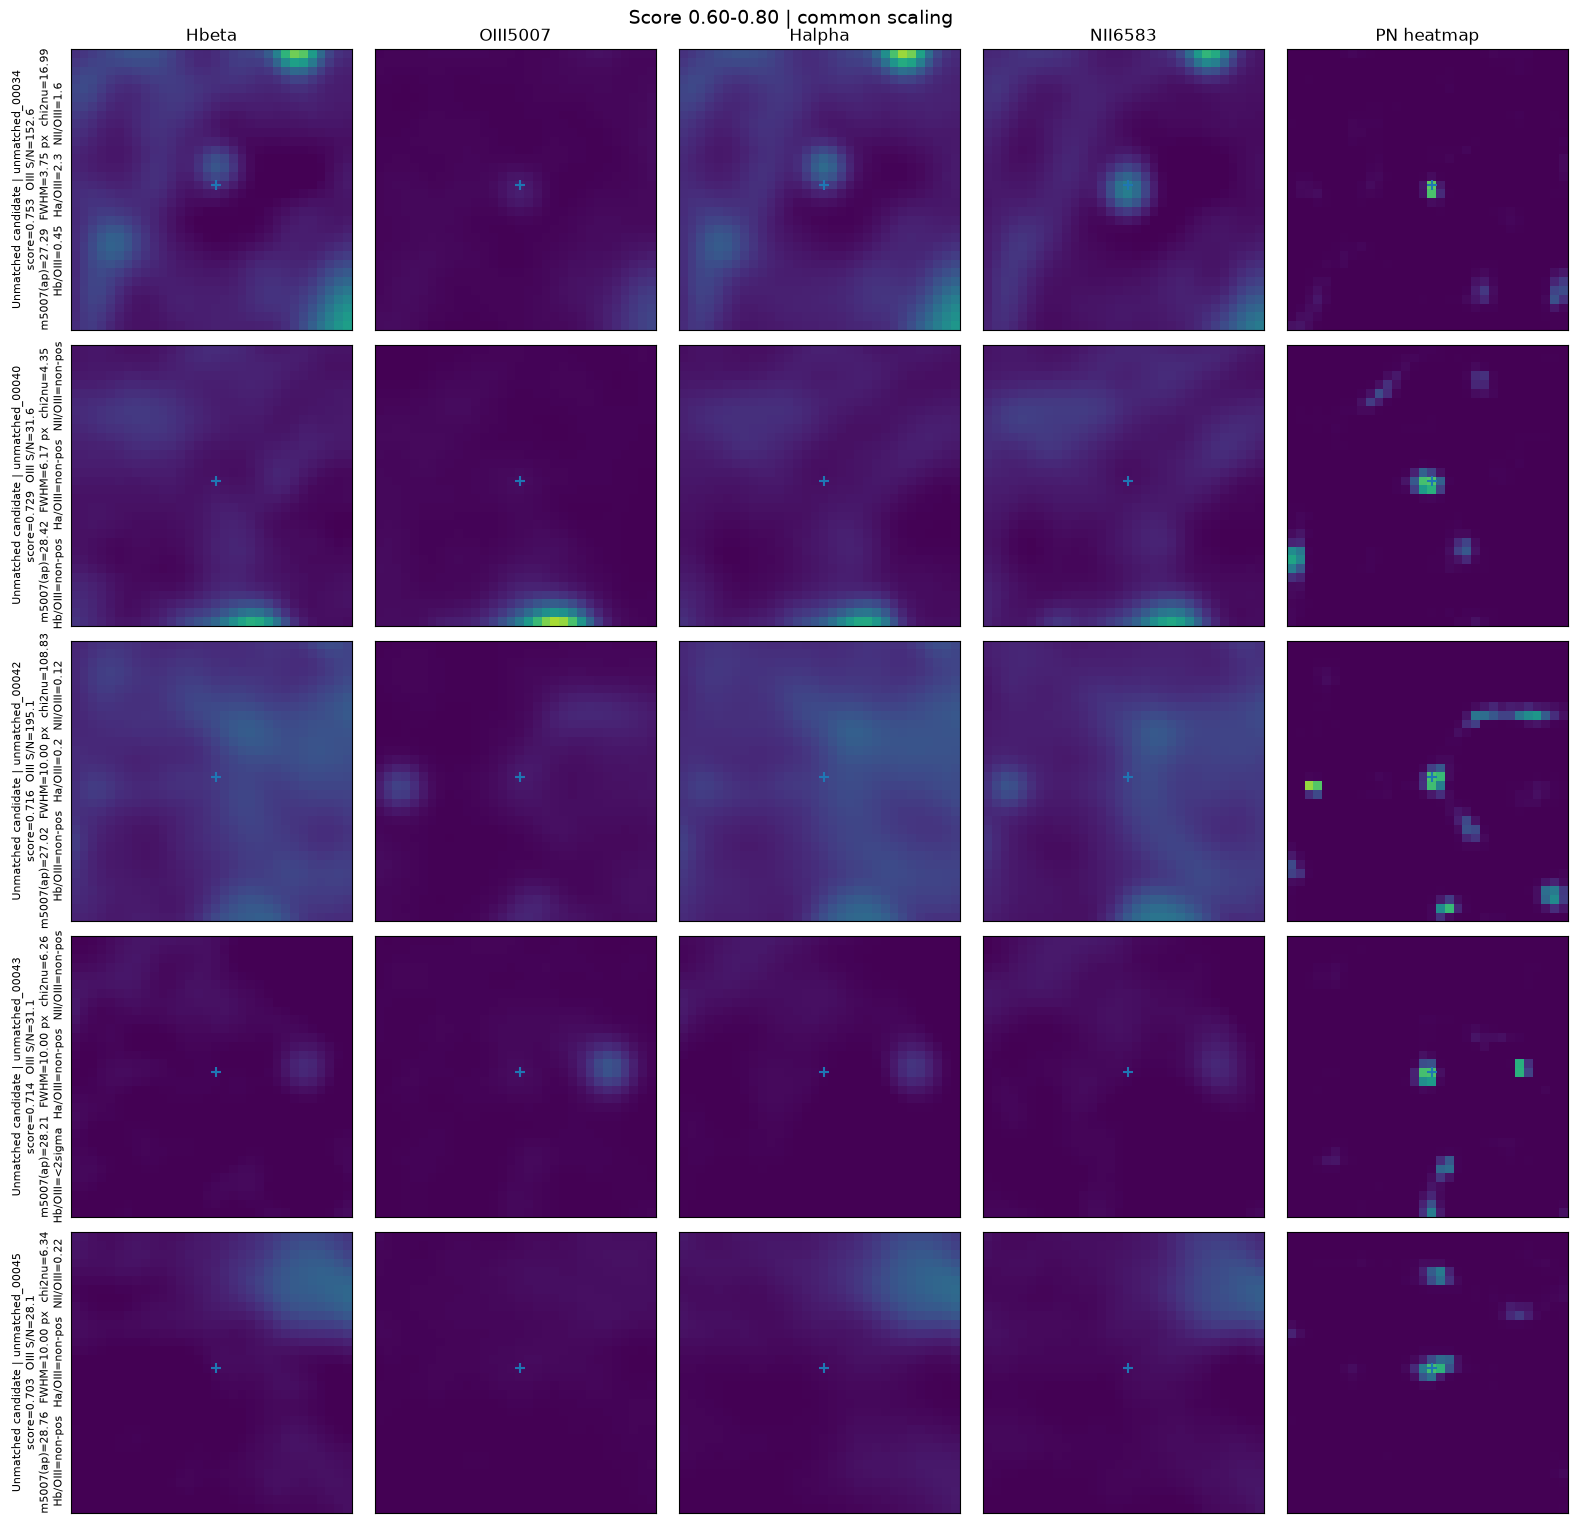

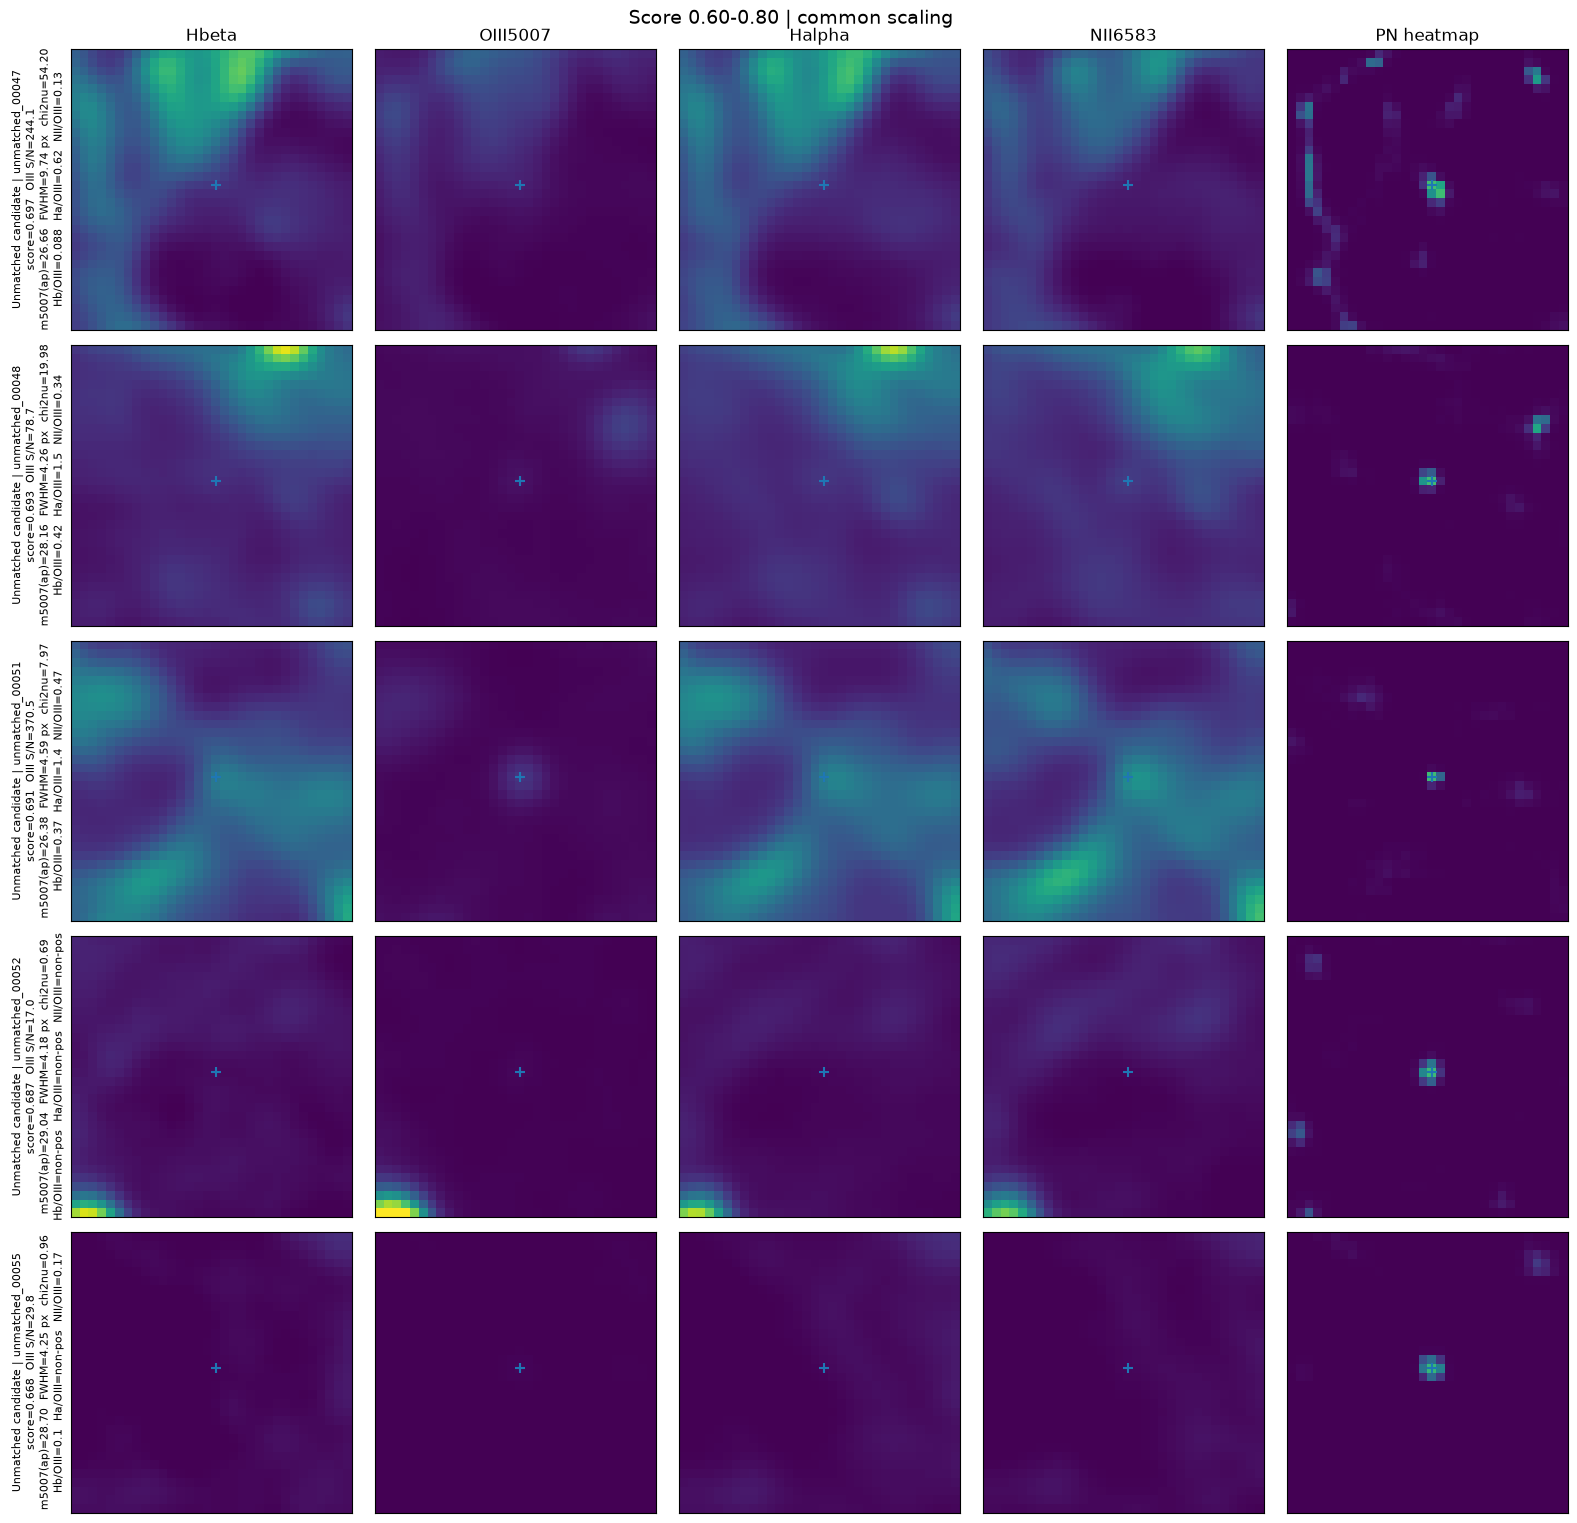

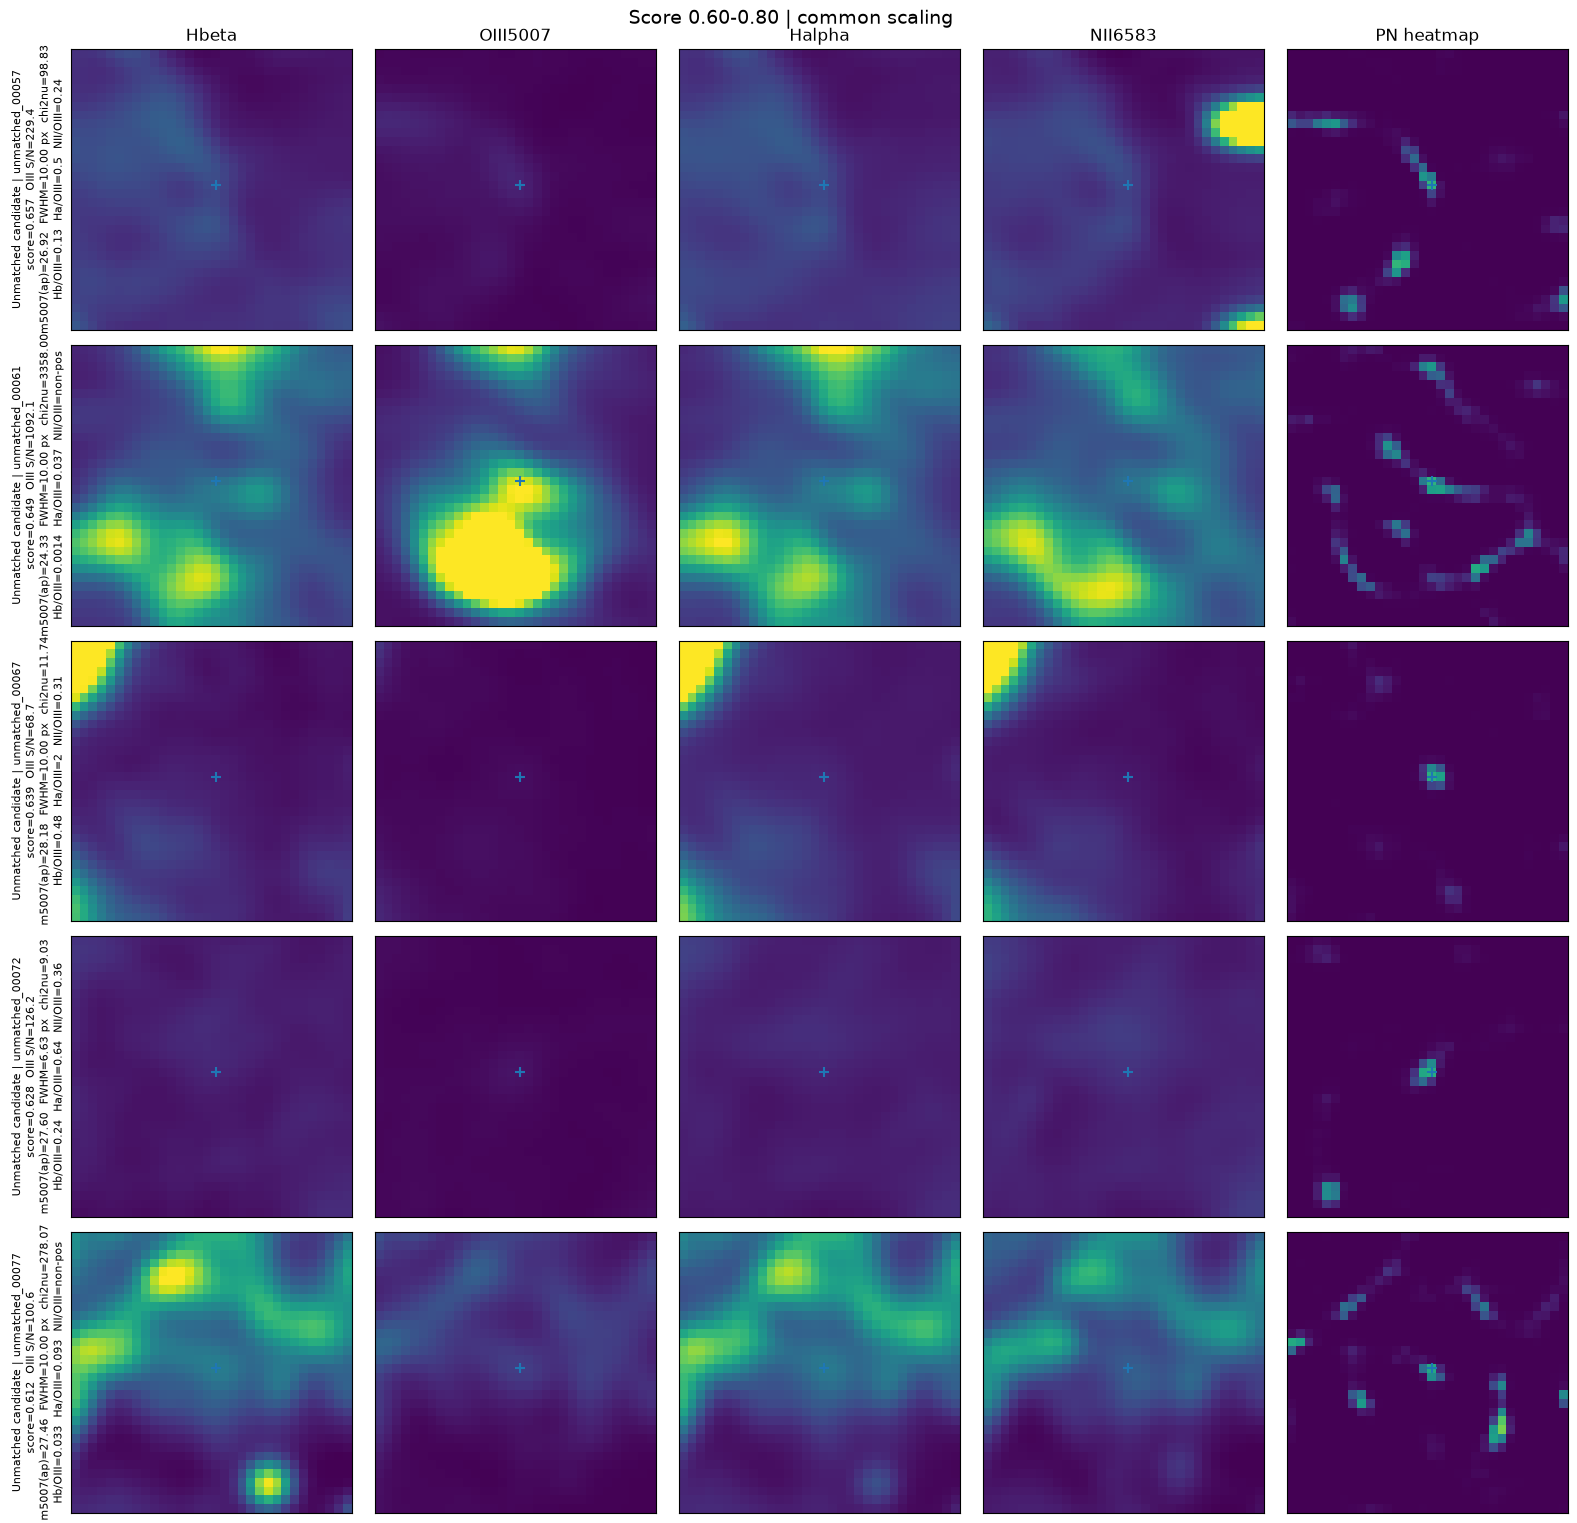

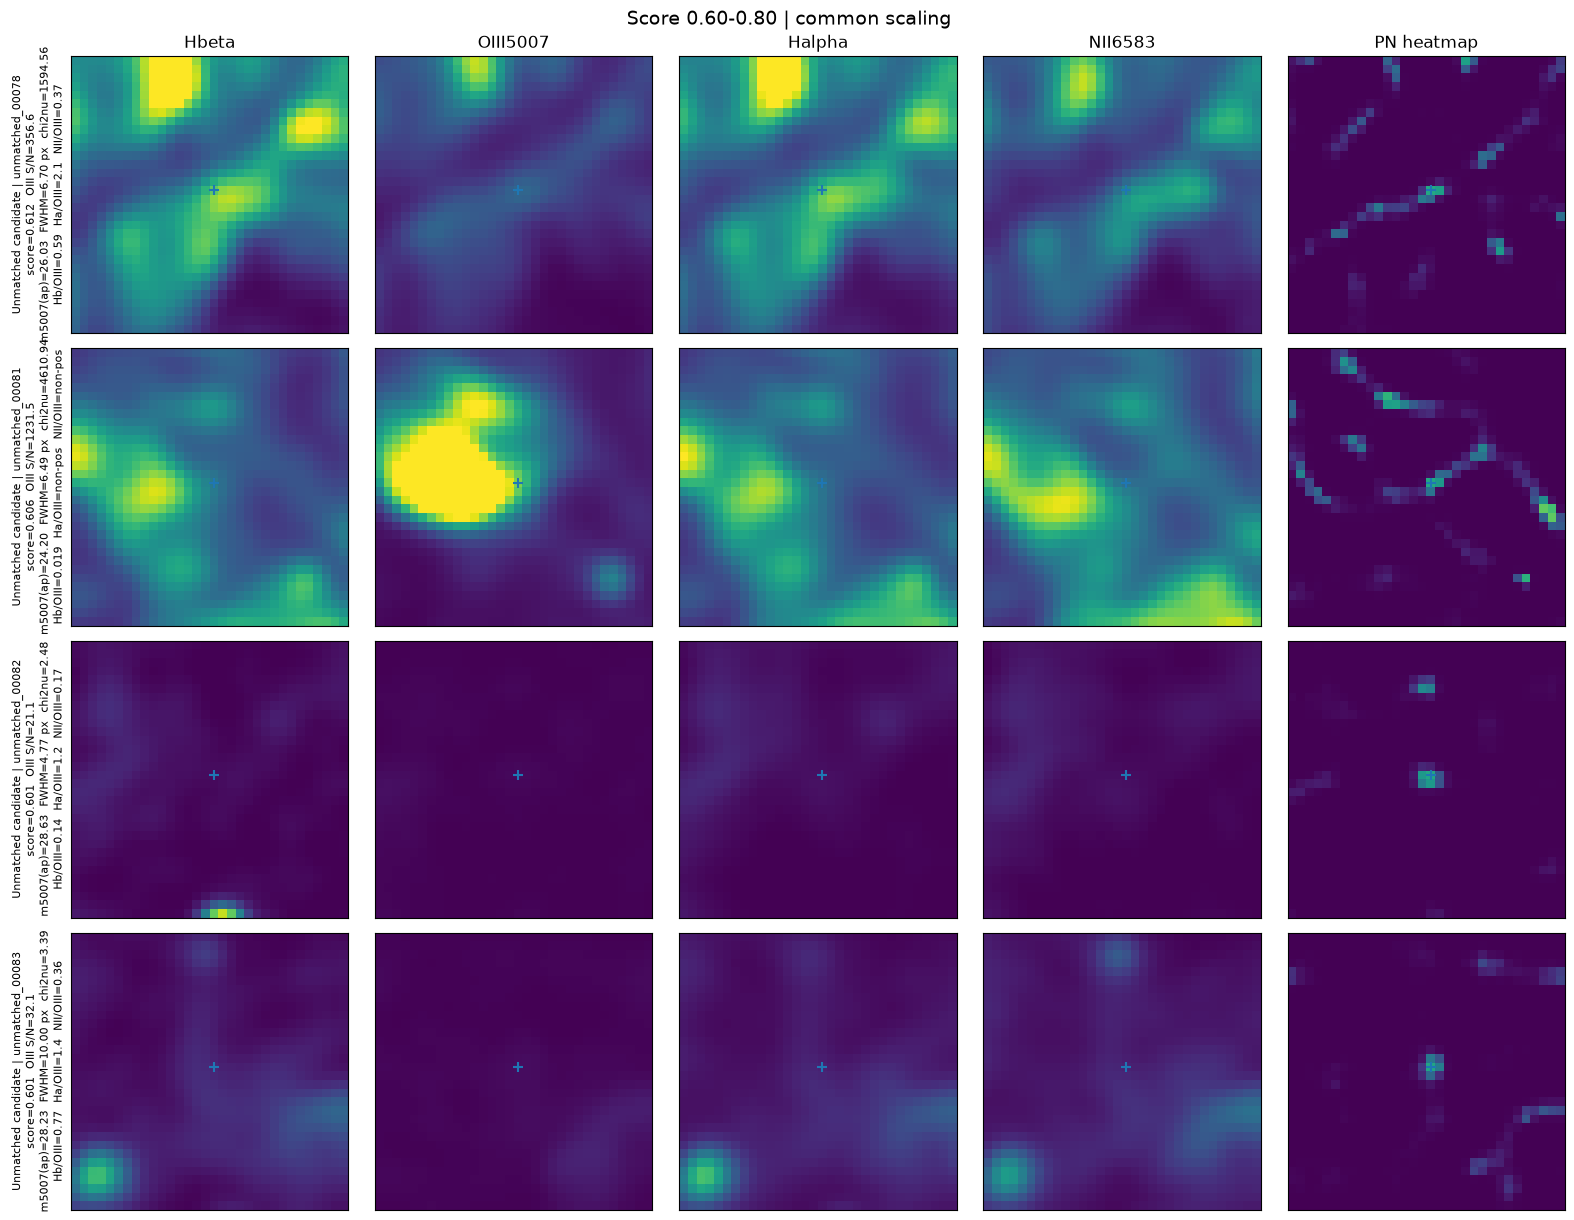

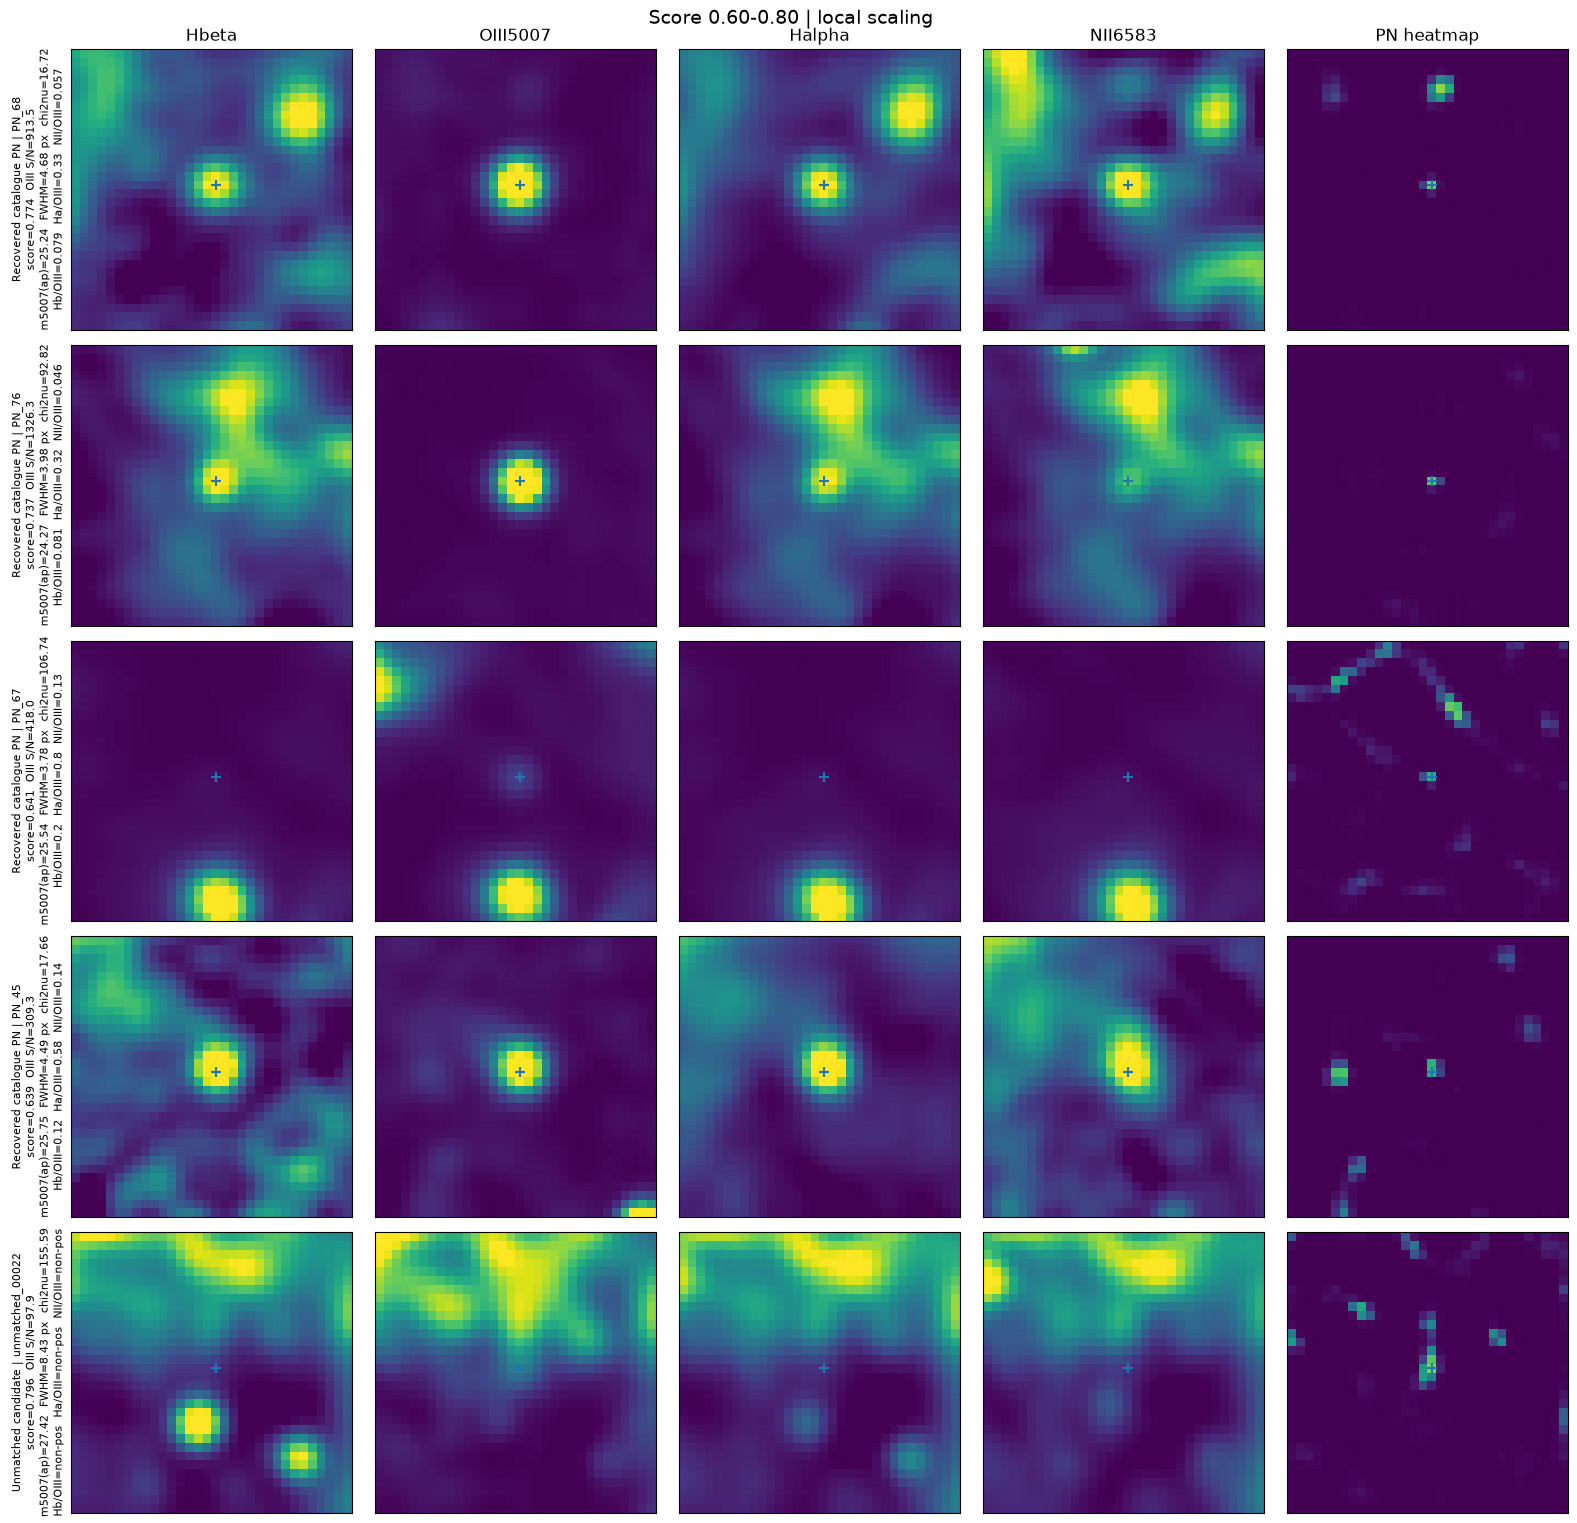

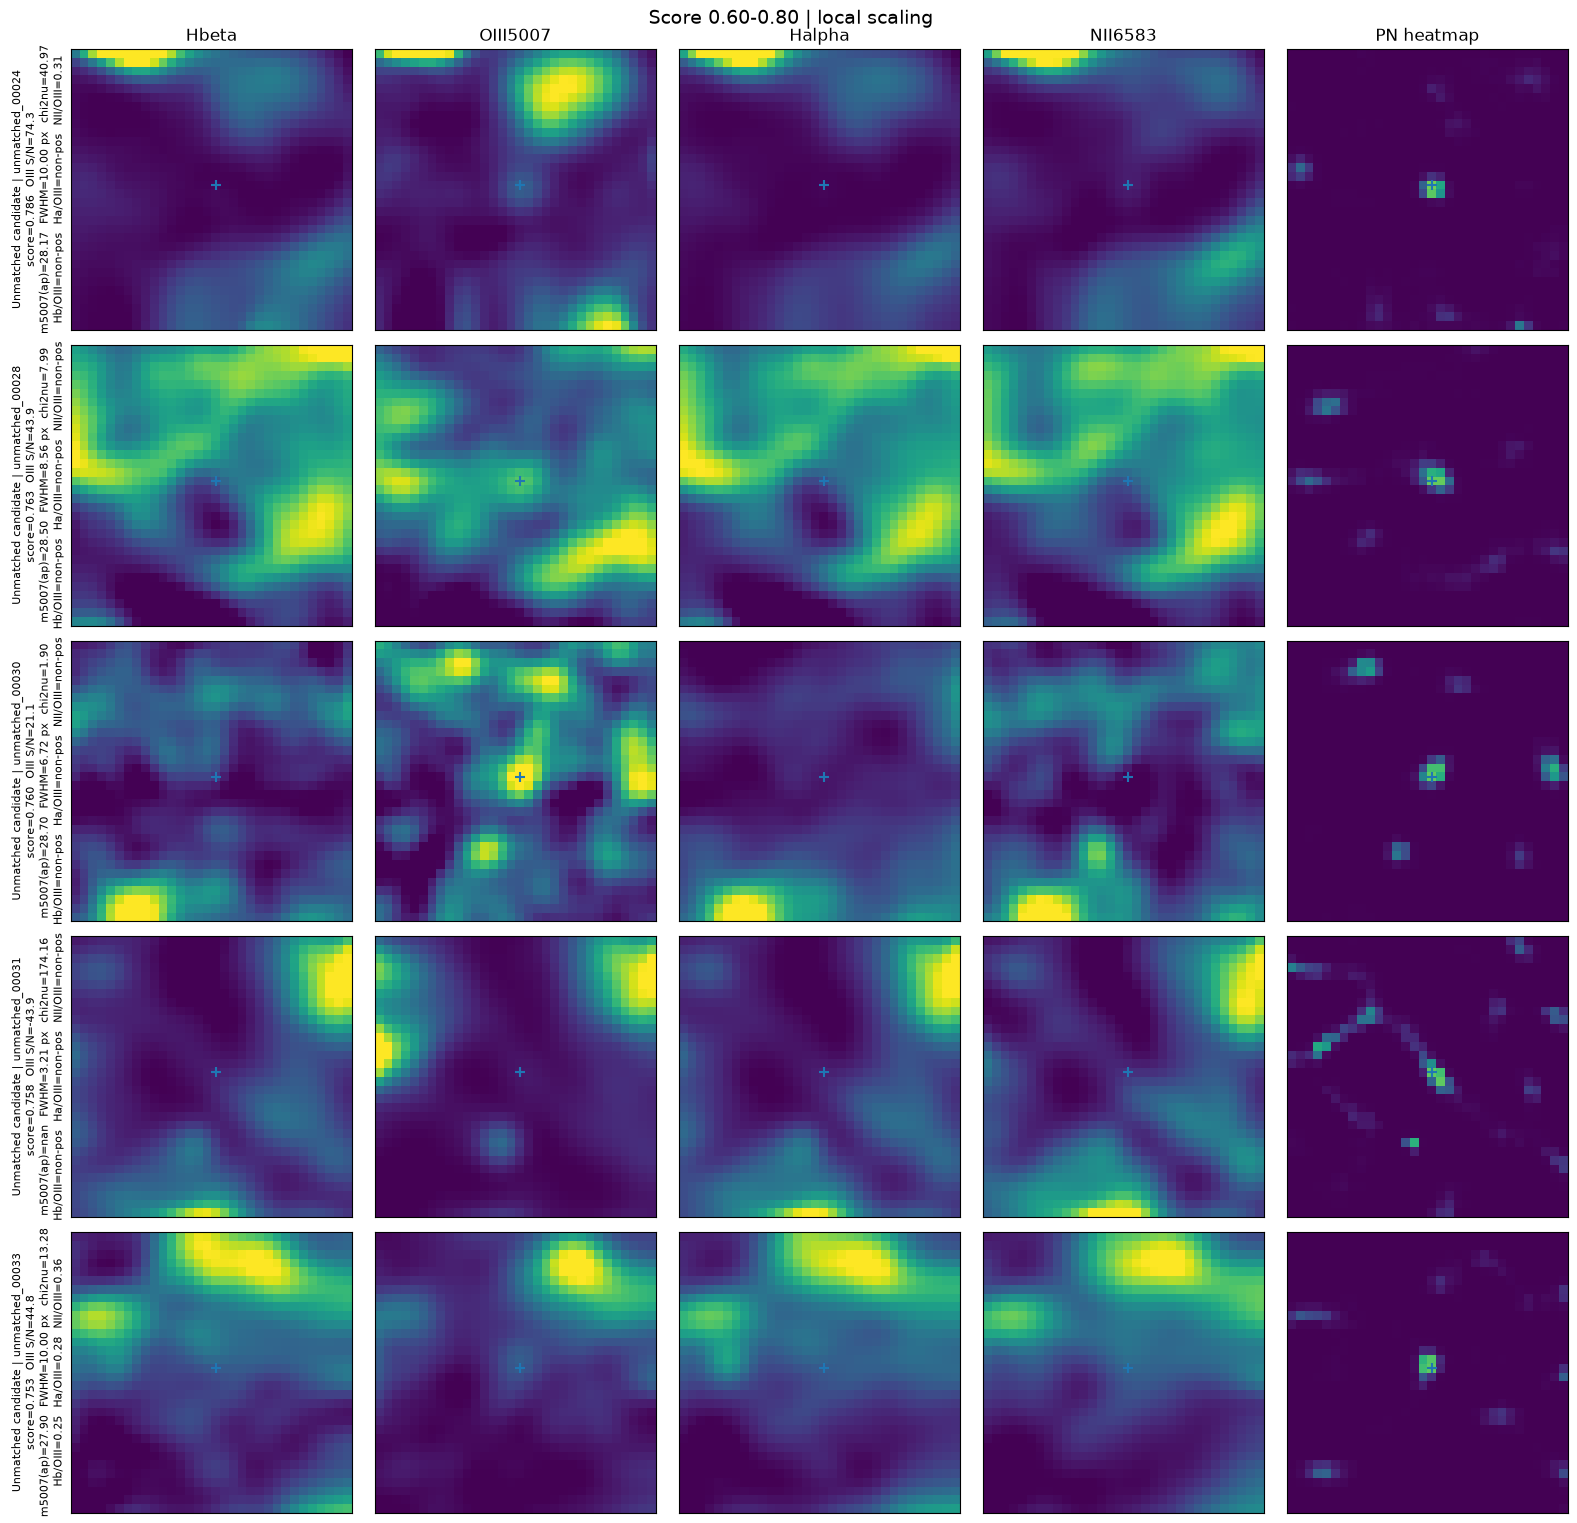

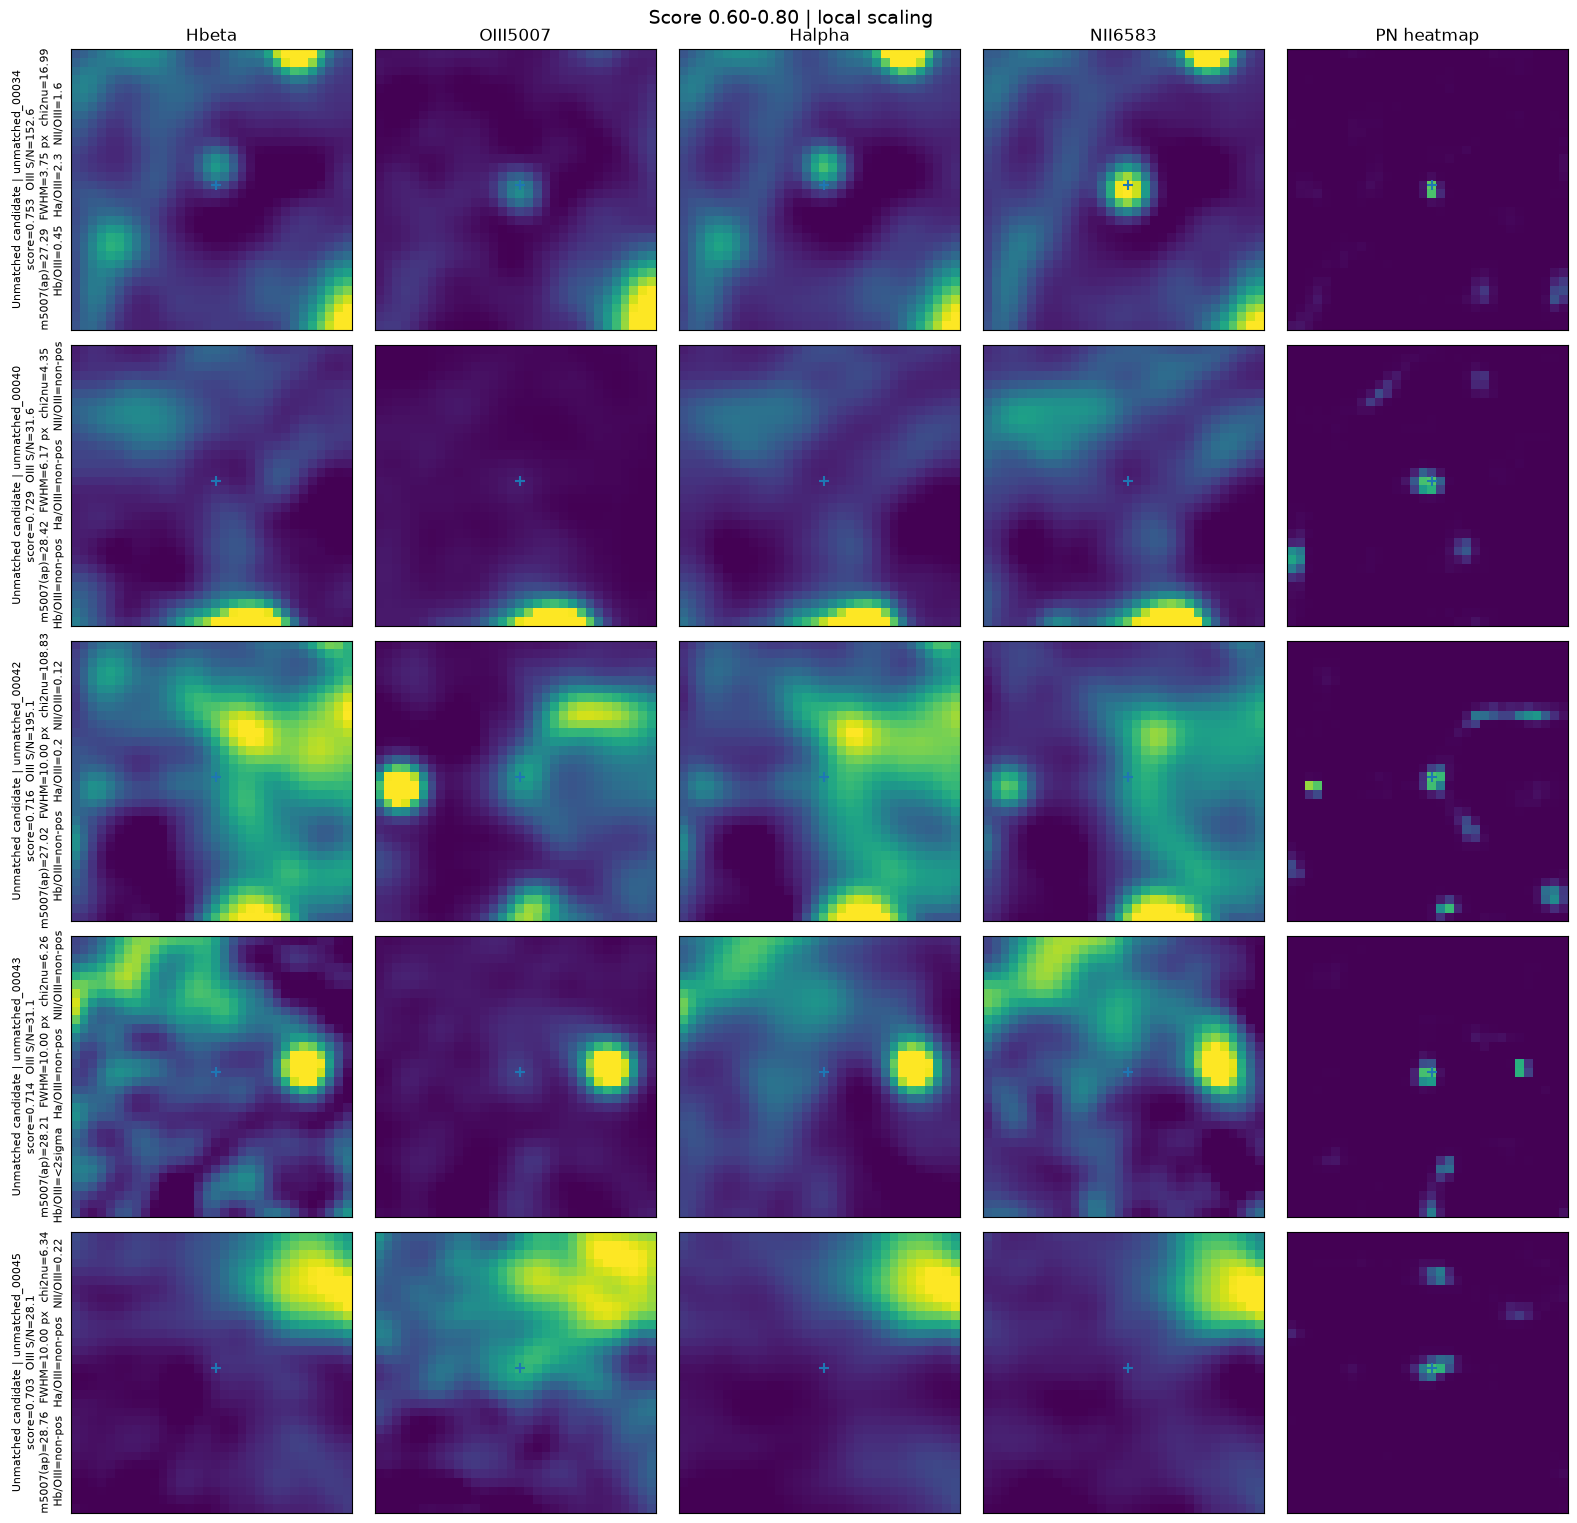

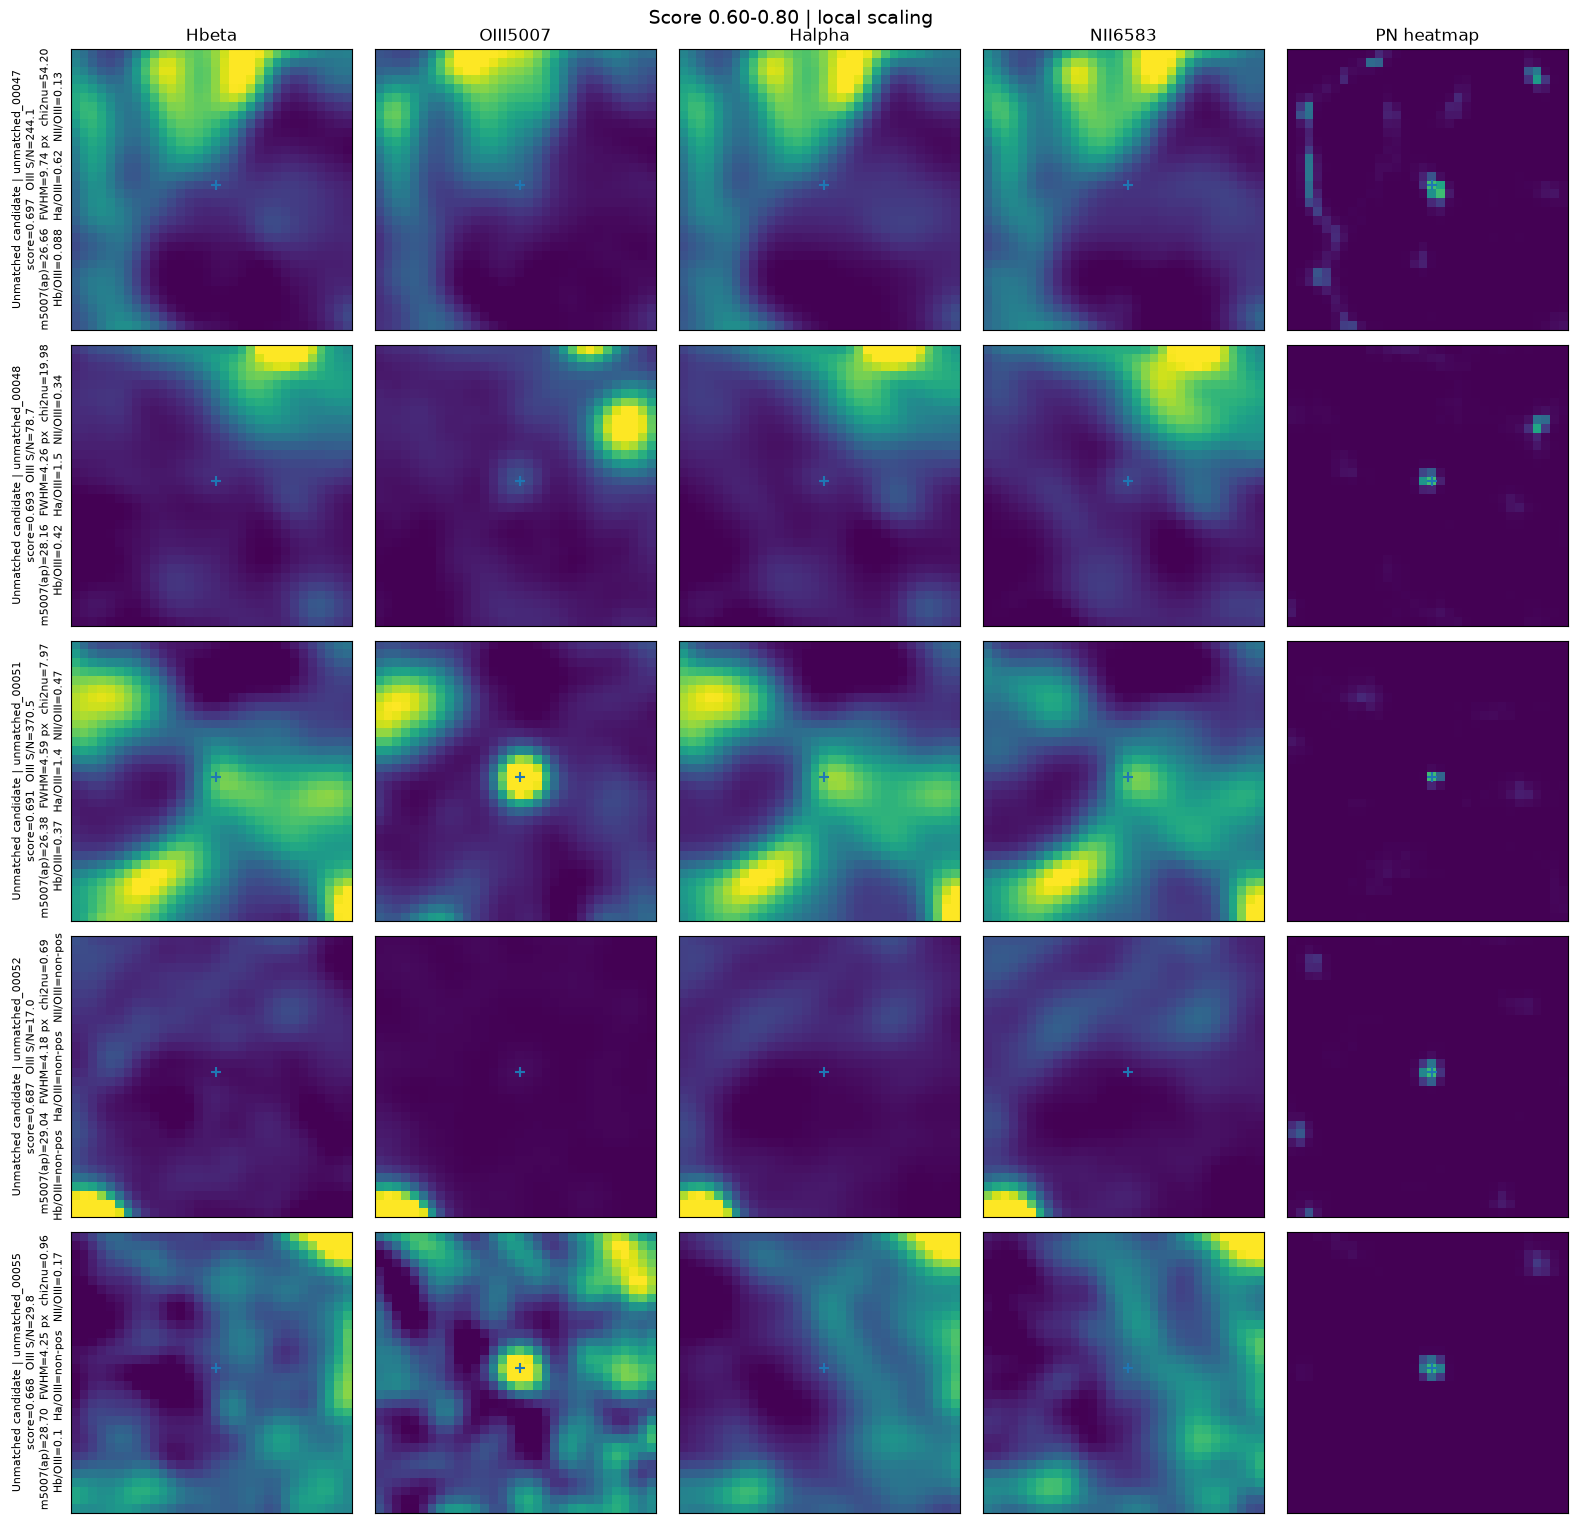

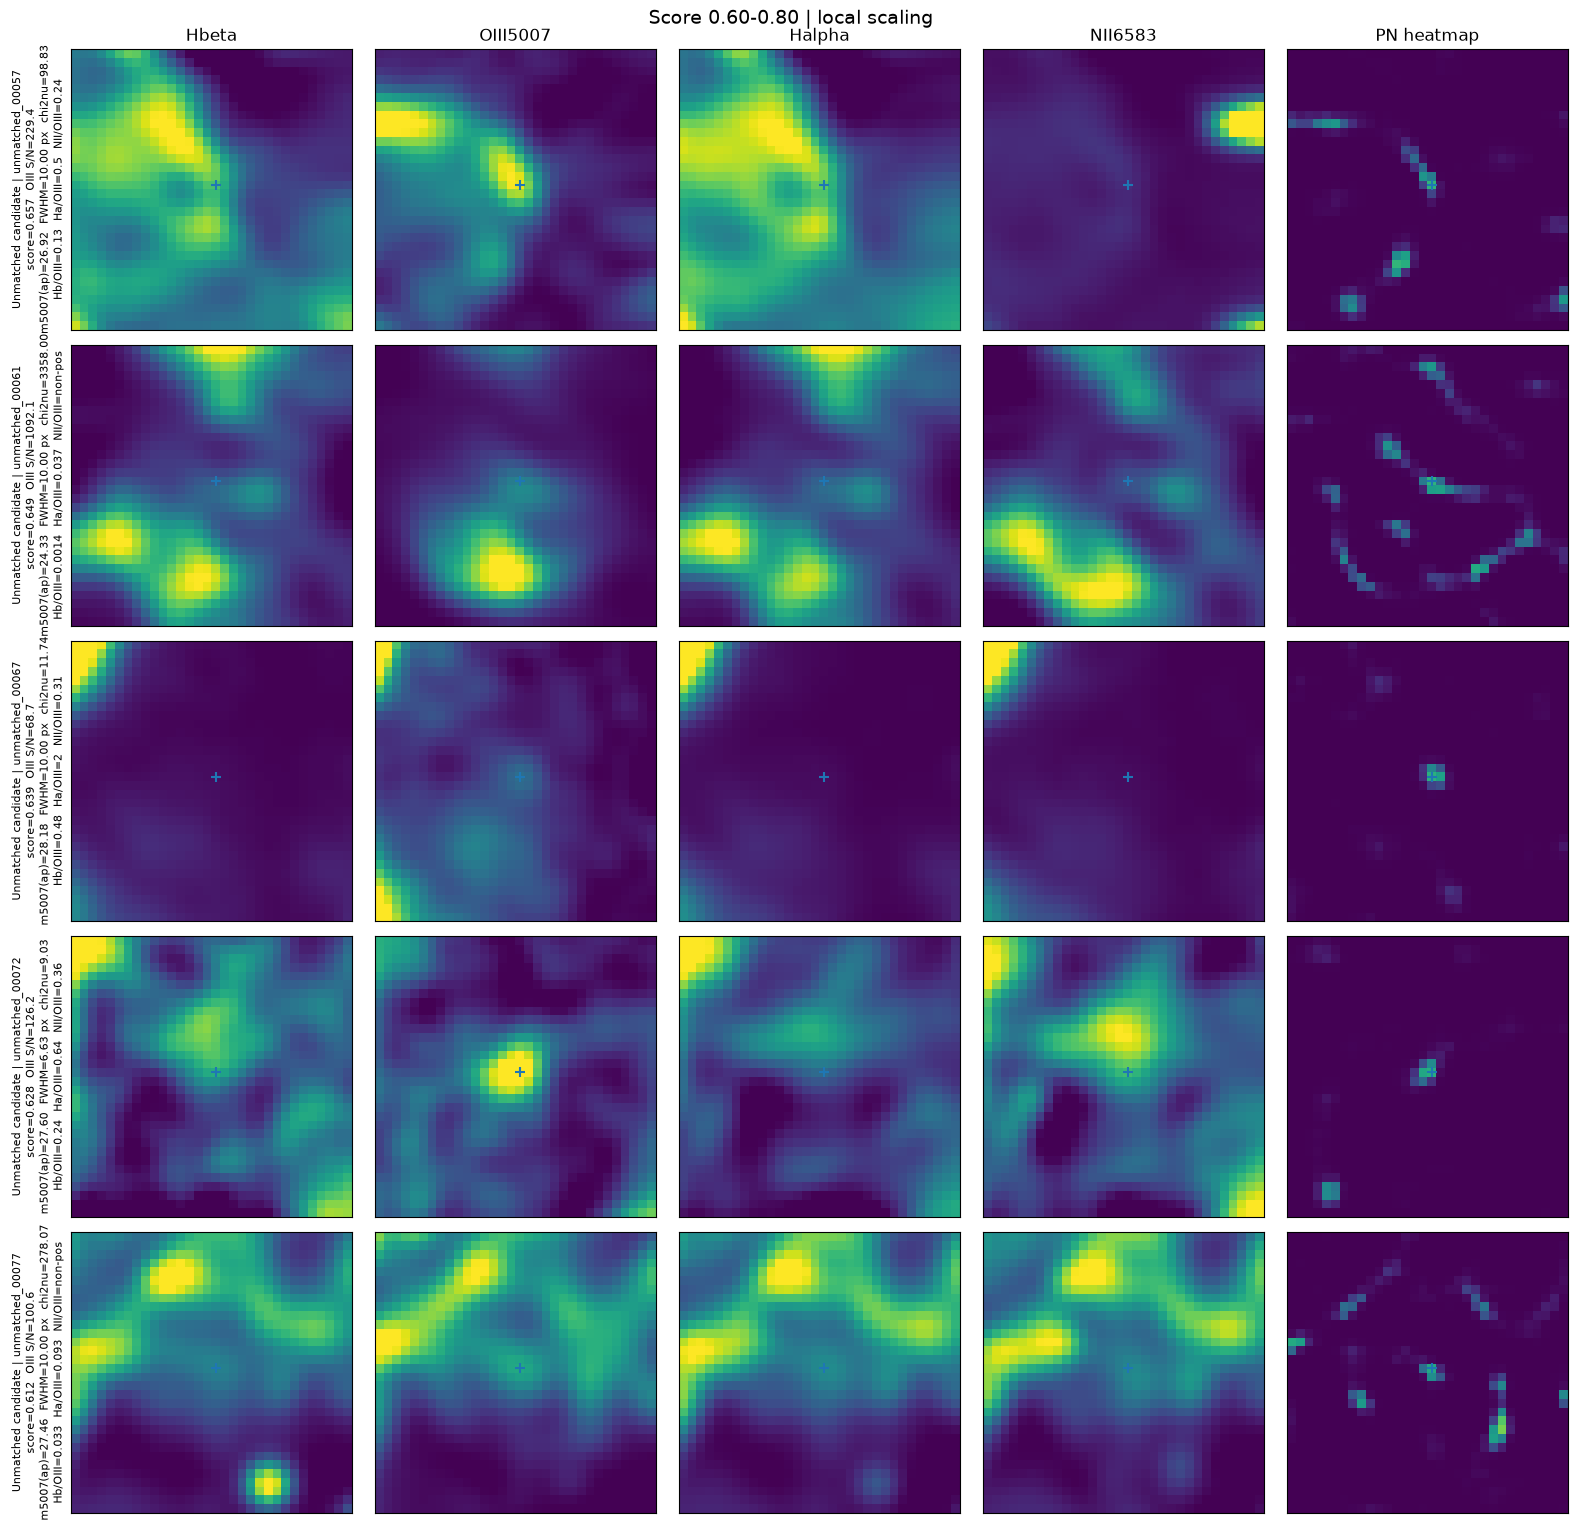

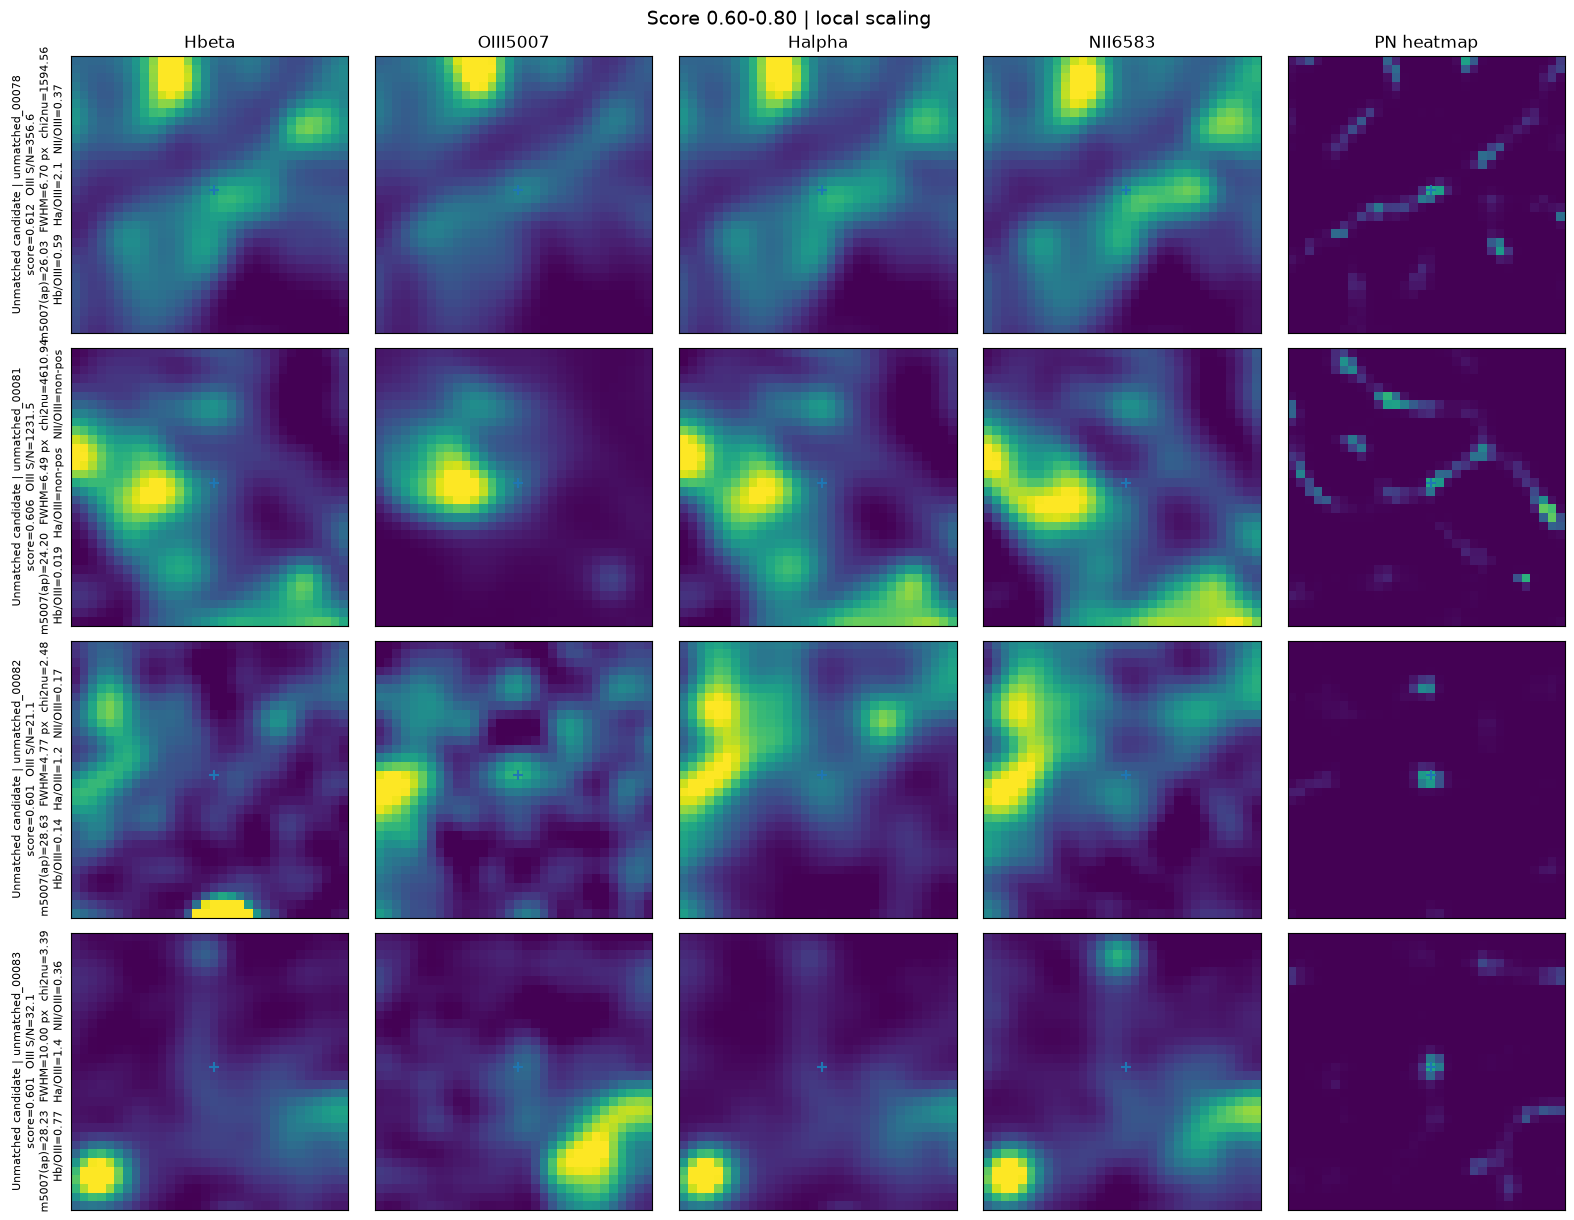

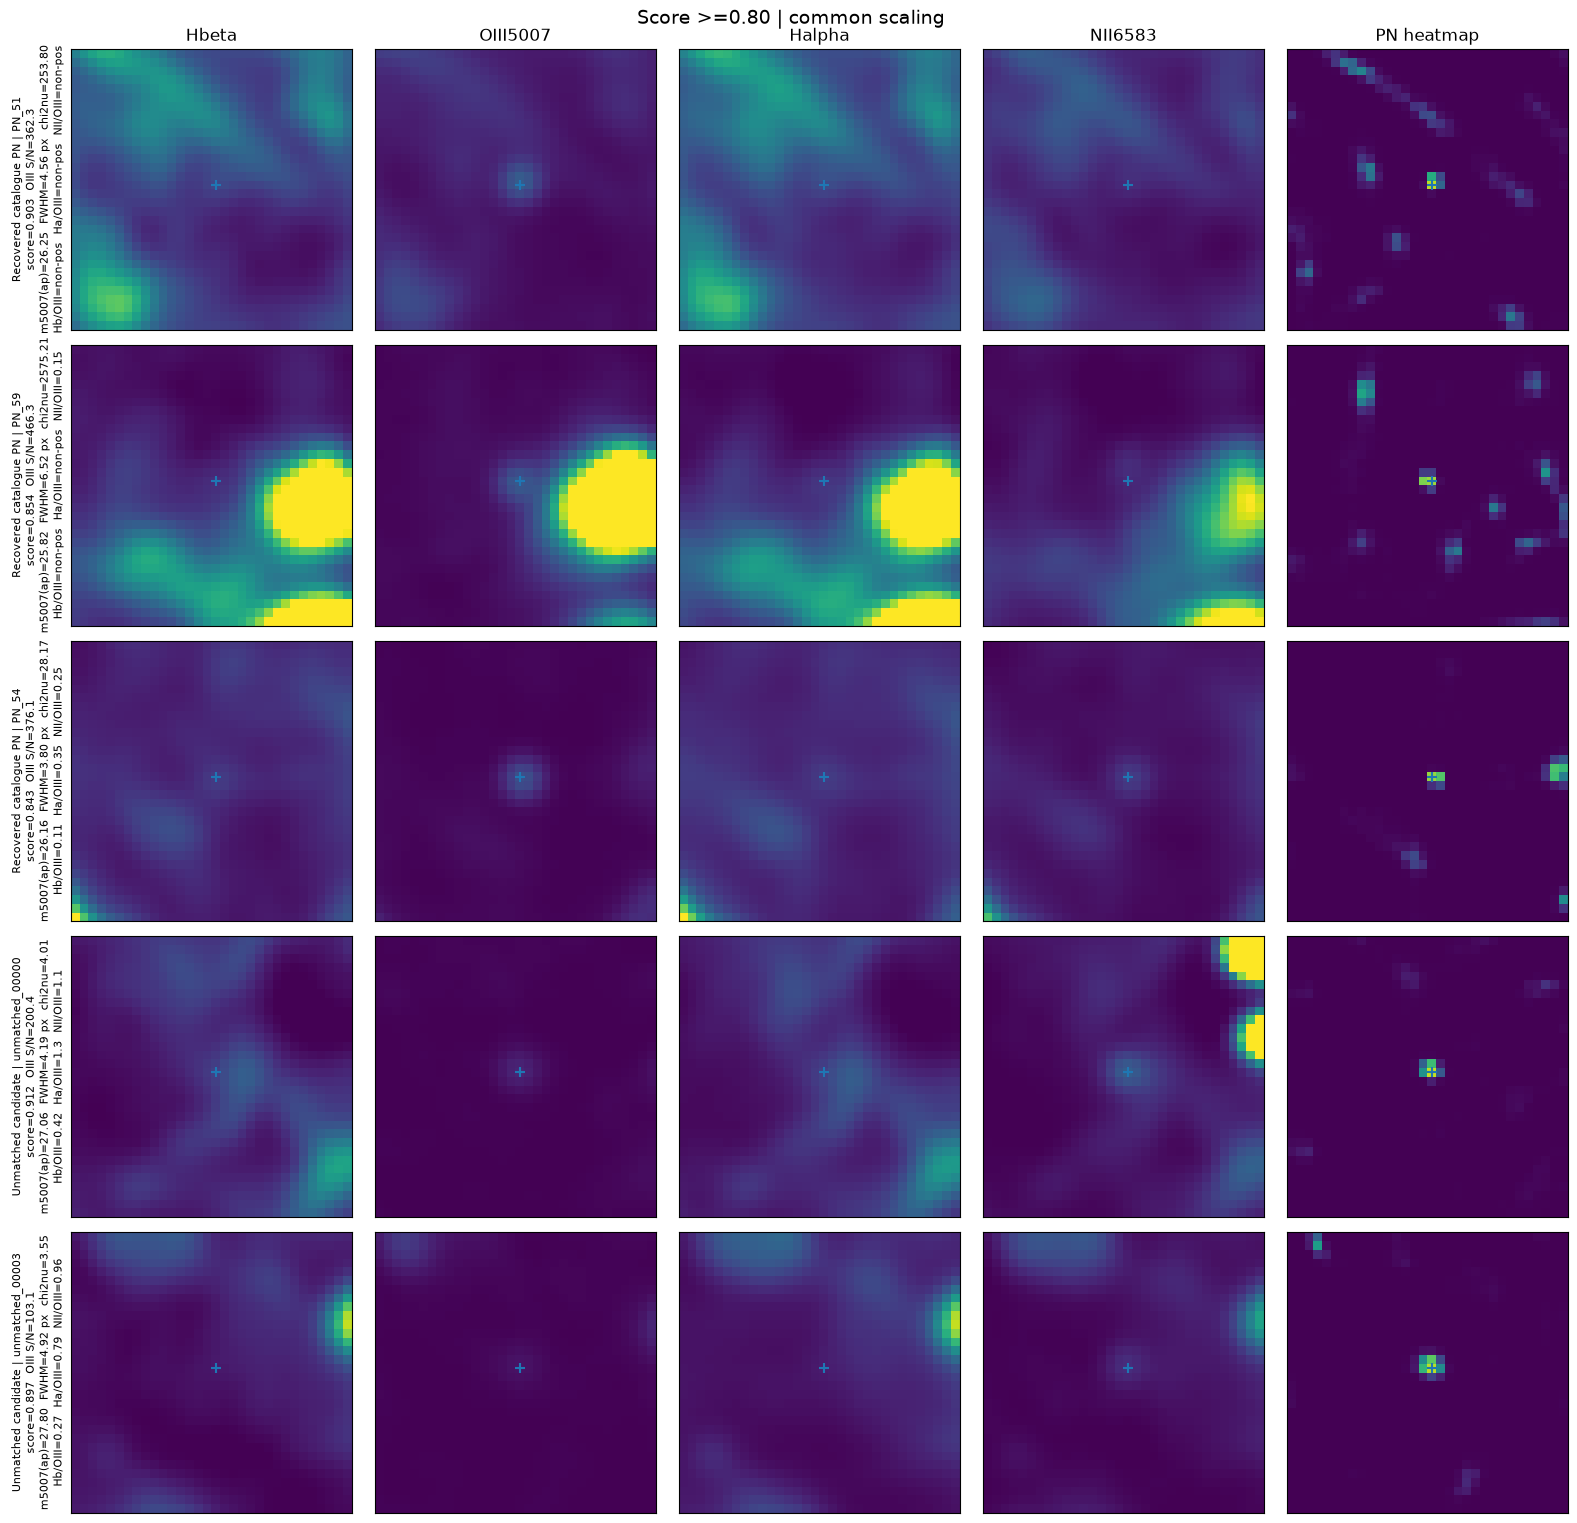

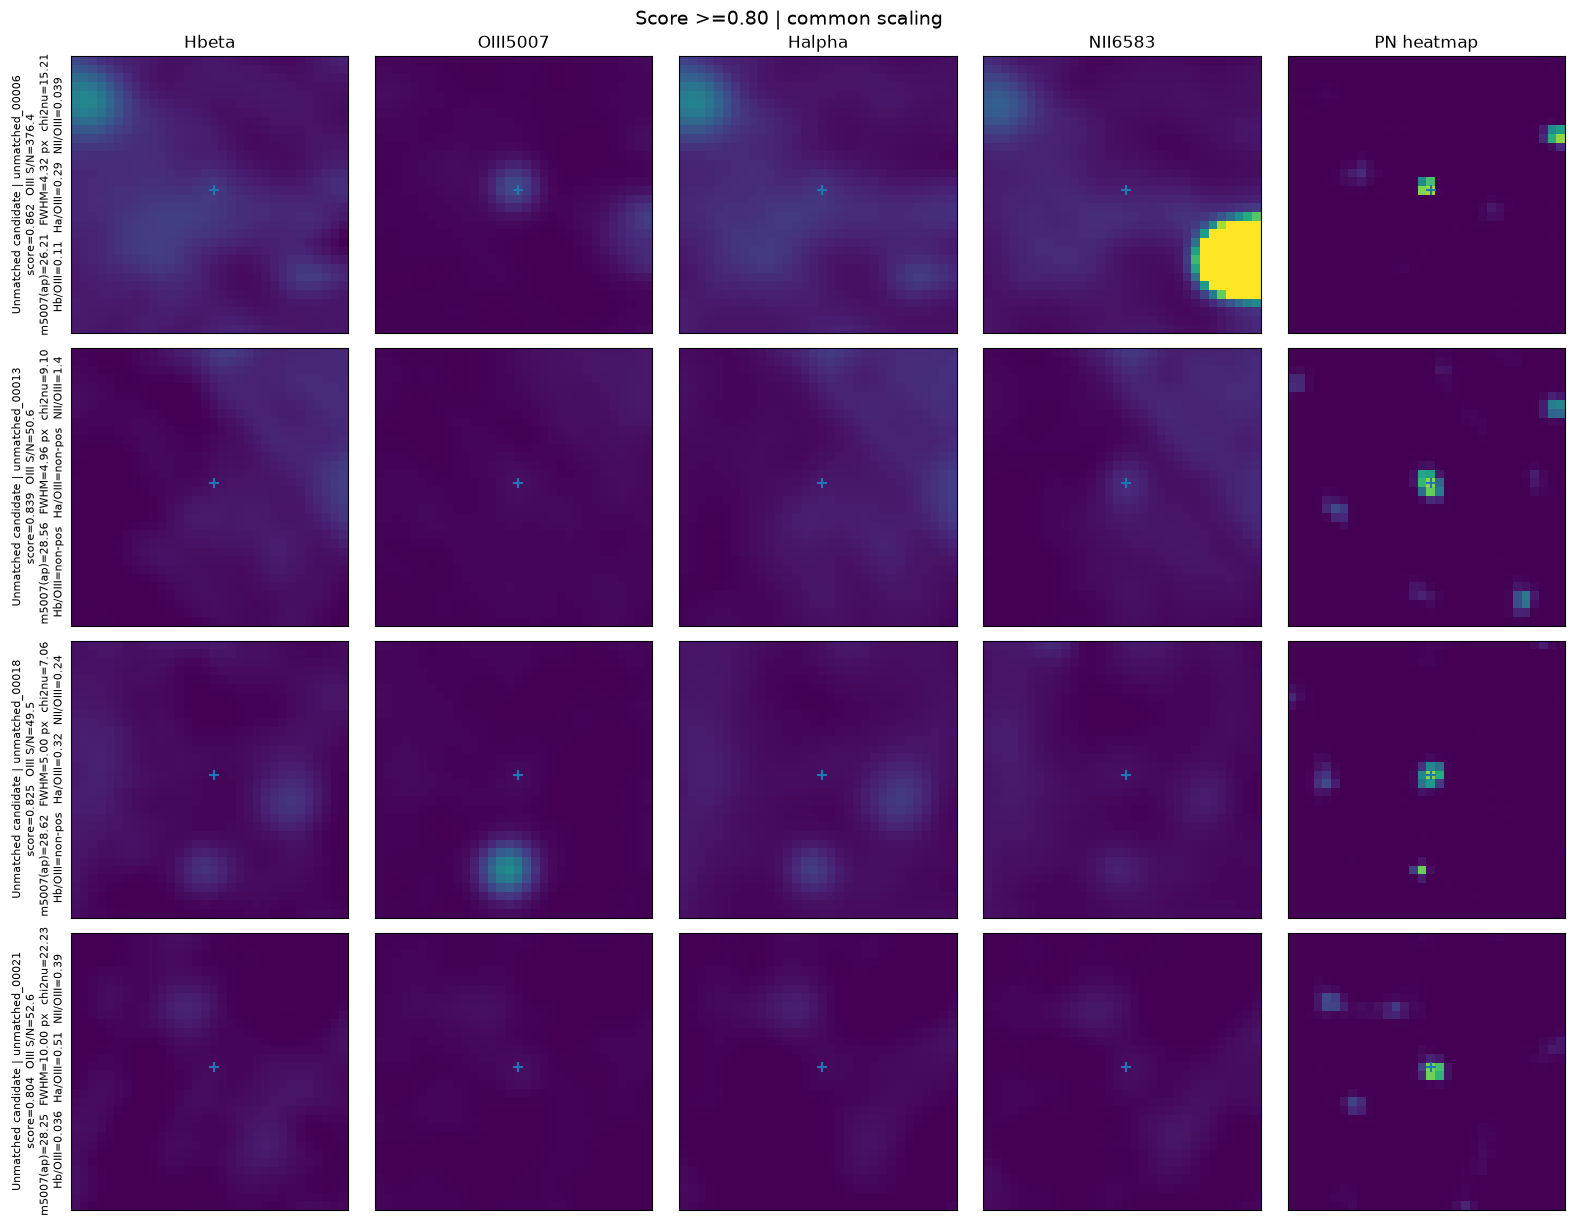

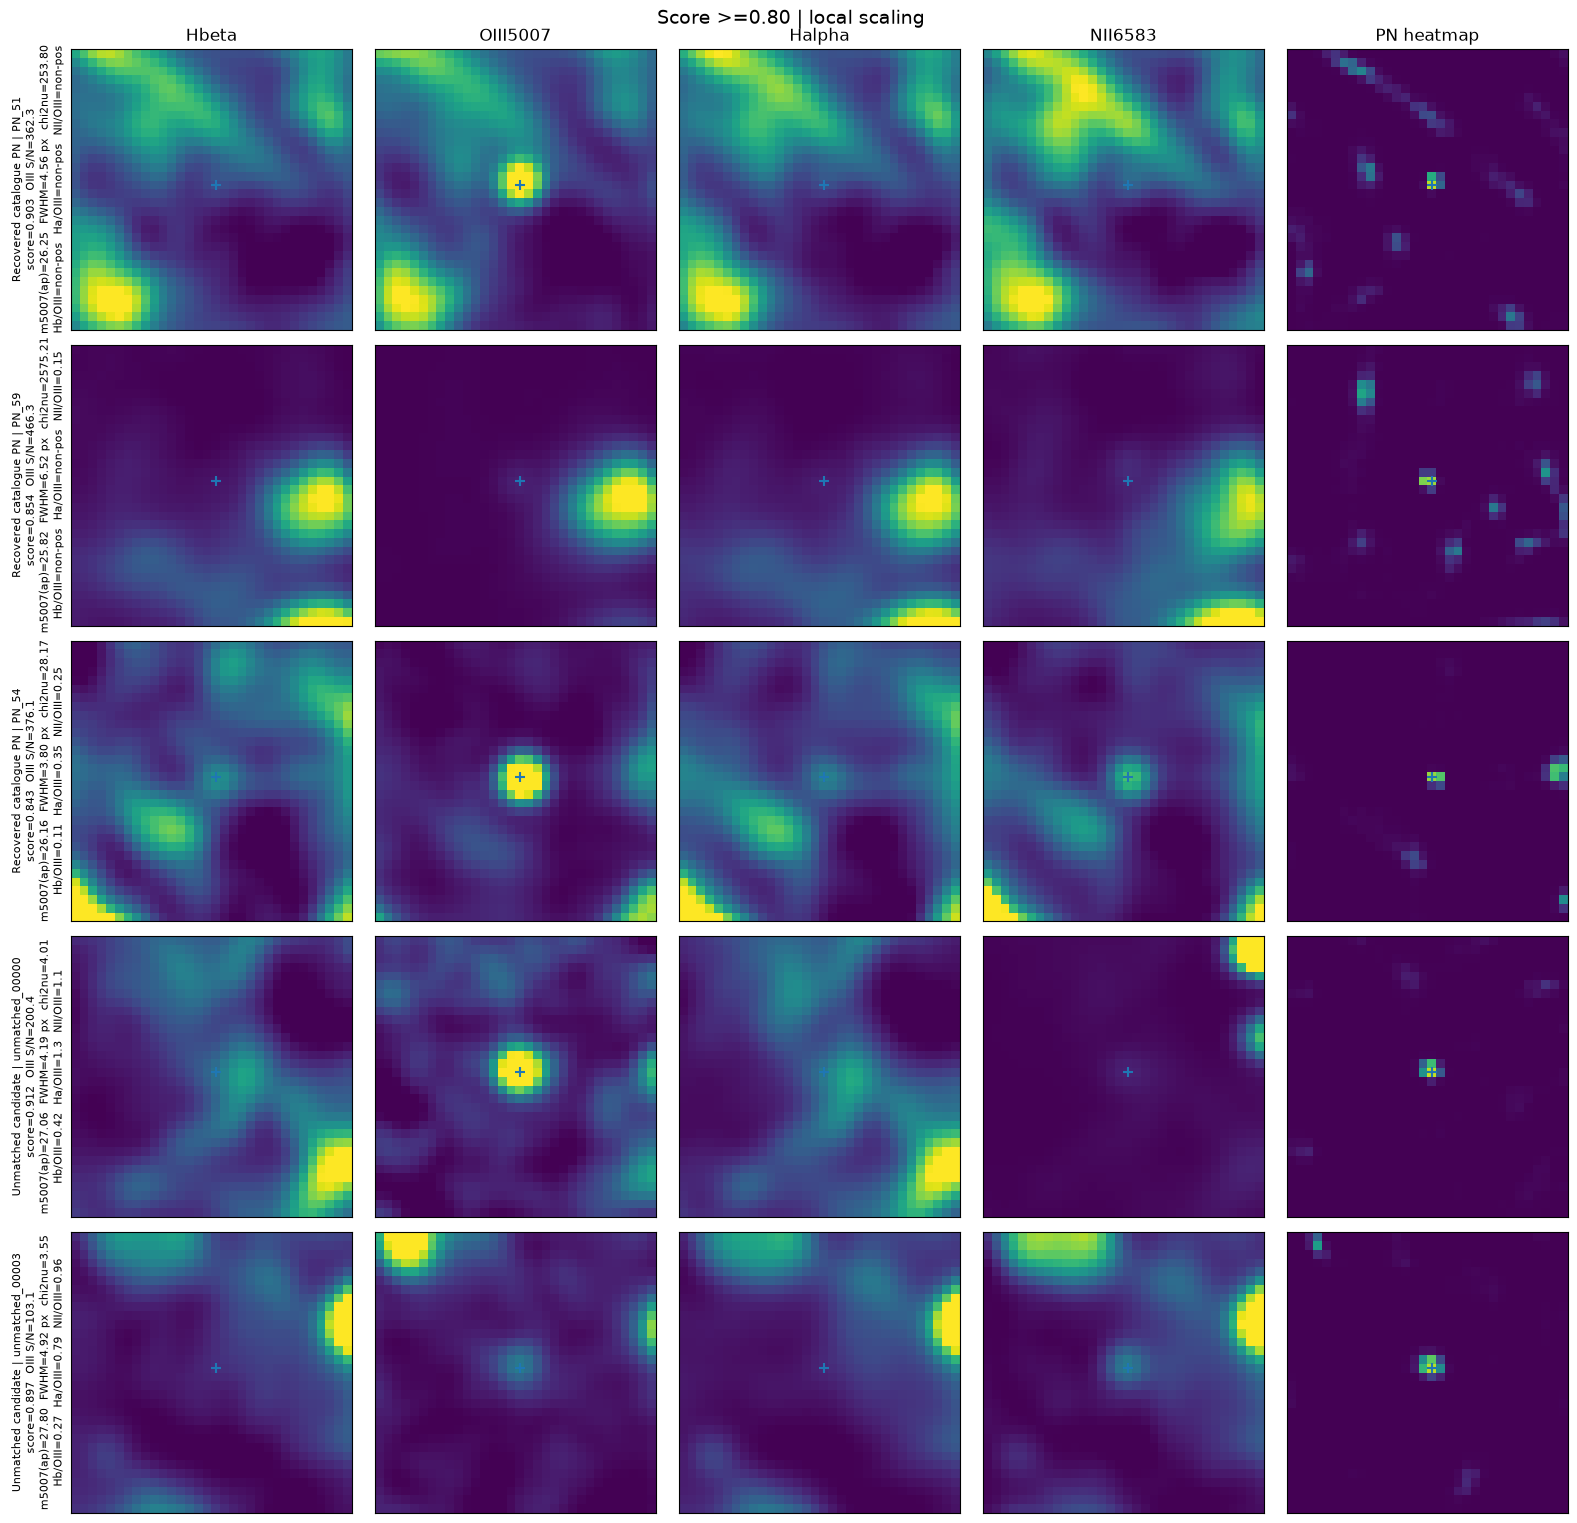

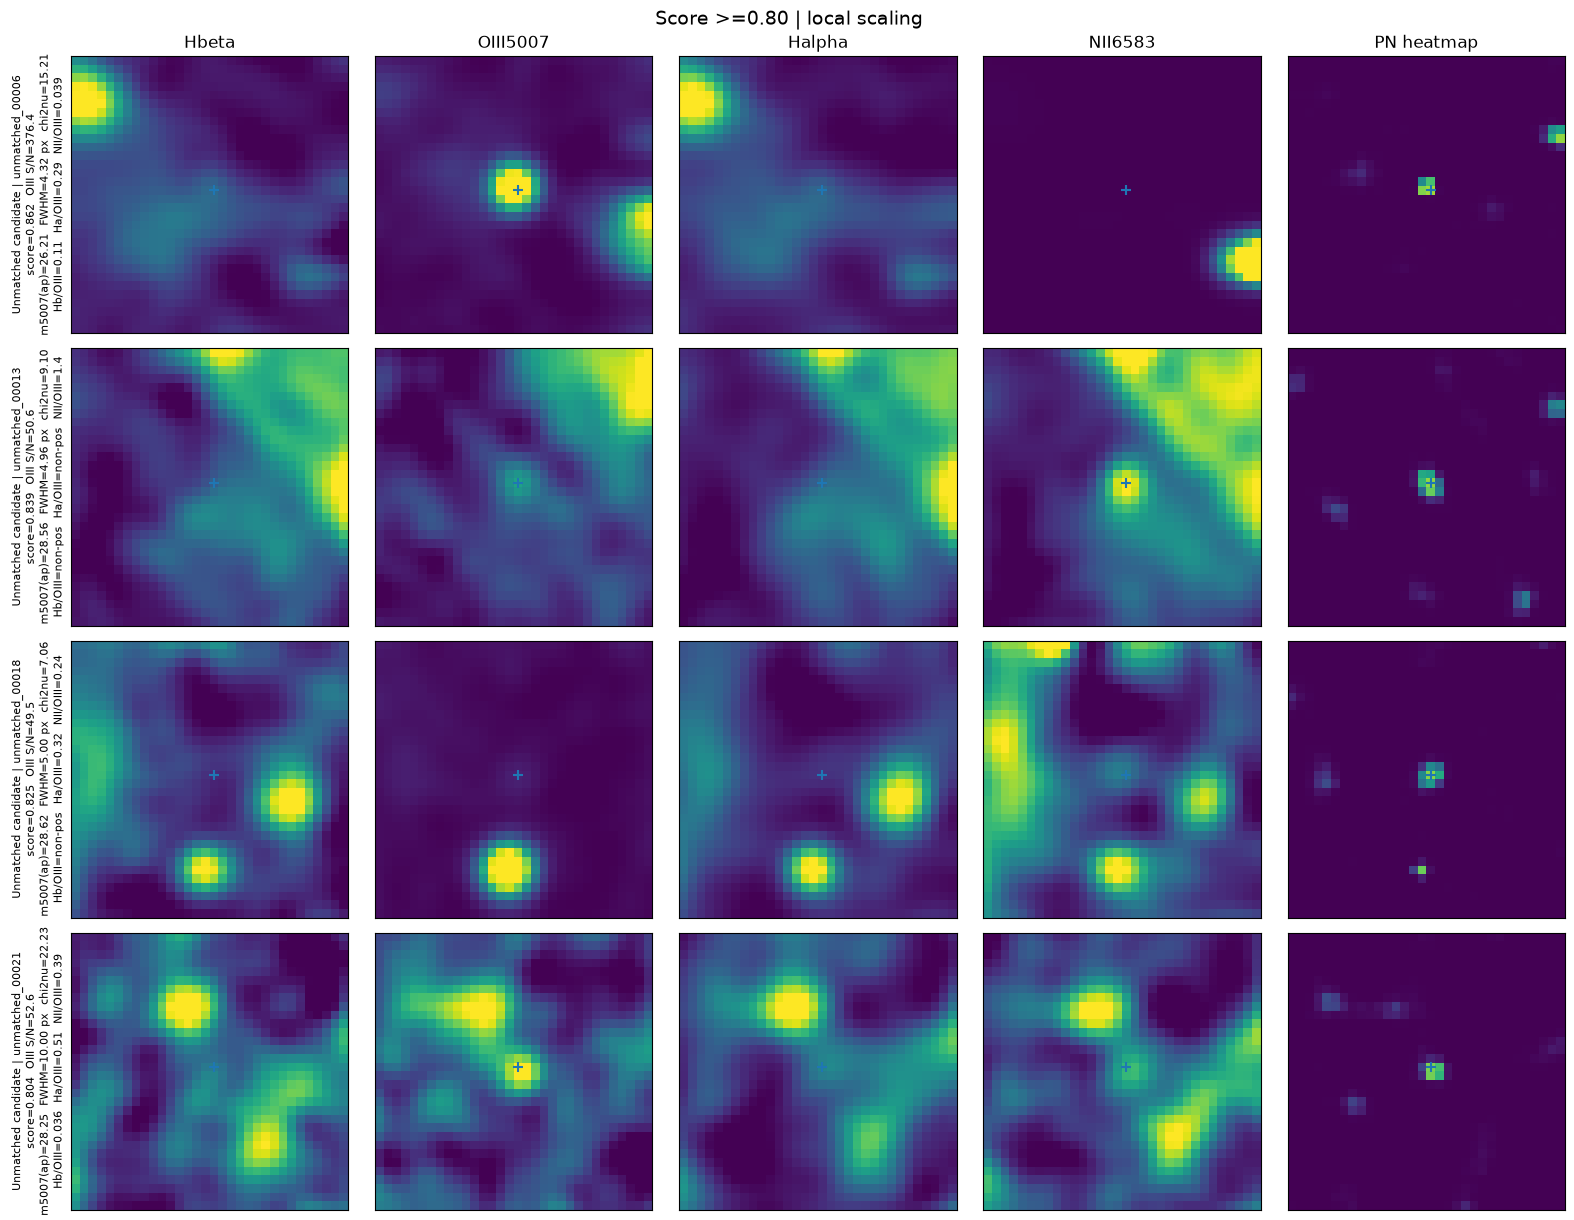

In [174]:
DISPLAY_MAPS = {
    "Hbeta": hb_flux,
    "OIII5007": oiii_flux,
    "Halpha": ha_flux,
    "NII6583": nii_flux,
    "PN heatmap": pn_heatmap,
}


def extract_centered_cutout(arr, x, y, size=DIAG_CUTOUT_SIZE):
    half = size // 2
    cx, cy = int(round(x)), int(round(y))
    x0, y0 = cx - half, cy - half
    x1, y1 = x0 + size, y0 + size
    if x0 < 0 or y0 < 0 or x1 > arr.shape[1] or y1 > arr.shape[0]:
        return None, None
    return arr[y0:y1, x0:x1], (x0, y0)


def robust_limits(values, lo=5, hi=99):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0.0, 1.0
    vmin, vmax = np.percentile(values, [lo, hi])
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        center = float(np.nanmedian(values)) if values.size else 0.0
        scale = float(np.nanstd(values)) if values.size else 1.0
        scale = scale if np.isfinite(scale) and scale > 0 else 1.0
        return center - scale, center + scale
    return float(vmin), float(vmax)


def common_scales_for_sample(sample):
    scales = {}
    for name, arr in DISPLAY_MAPS.items():
        if name == "PN heatmap":
            scales[name] = (0.0, 1.0)
            continue
        vals = []
        for _, r in sample.iterrows():
            cut, _ = extract_centered_cutout(arr, r["center_x"], r["center_y"])
            if cut is not None:
                vals.append(cut.ravel())
        scales[name] = robust_limits(np.concatenate(vals) if vals else np.array([]))
    return scales


def fmt_value(v, fmt=".2f"):
    return "nan" if not np.isfinite(v) else format(v, fmt)


def fmt_ratio_with_status(r, value_col, status_col, label):
    value = r.get(value_col, np.nan)
    if np.isfinite(value):
        return f"{label}={value:.2g}"
    status = str(r.get(status_col, "unavailable"))
    if "S/N <=" in status:
        return f"{label}=<2sigma"
    if "flux <= 0" in status:
        return f"{label}=non-pos"
    if status == "edge object":
        return f"{label}=edge"
    return f"{label}=unreliable"


def row_annotation(r):
    ident = str(r["object_id"])
    return (
        f"{r['population']} | {ident}\n"
        f"score={fmt_value(r['network_score'], '.3f')}  "
        f"OIII S/N={fmt_value(r['oiii_snr'], '.1f')}\n"
        f"m5007(ap)={fmt_value(r['m5007_aperture'], '.2f')}  "
        f"FWHM={fmt_value(r['moffat_fwhm_pix'], '.2f')} px  "
        f"chi2nu={fmt_value(r['moffat_reduced_chi2'], '.2f')}\n"
        f"{fmt_ratio_with_status(r, 'hb_over_oiii', 'hb_over_oiii_status', 'Hb/OIII')}  "
        f"{fmt_ratio_with_status(r, 'ha_over_oiii', 'ha_over_oiii_status', 'Ha/OIII')}  "
        f"{fmt_ratio_with_status(r, 'nii_over_oiii', 'nii_over_oiii_status', 'NII/OIII')}"
    )


def plot_visual_sample_pages(sample, score_bin, scaling="common", page_size=5):
    """Plot all selected objects in one score bin, paginated in rows of 5 objects."""
    chosen = sample[sample["visual_score_bin"] == score_bin].copy()
    chosen = chosen.sort_values(["population", "network_score"], ascending=[True, False]).reset_index(drop=True)
    if len(chosen) == 0:
        print("No objects for", score_bin)
        return

    scales = common_scales_for_sample(chosen) if scaling == "common" else None
    channel_names = list(DISPLAY_MAPS.keys())

    for start in range(0, len(chosen), page_size):
        page = chosen.iloc[start:start + page_size]
        fig, axes = plt.subplots(len(page), len(channel_names), figsize=(16, 3.1 * len(page)), squeeze=False)

        for row_i, (_, r) in enumerate(page.iterrows()):
            for col_i, name in enumerate(channel_names):
                arr = DISPLAY_MAPS[name]
                cut, origin = extract_centered_cutout(arr, r["center_x"], r["center_y"])
                ax = axes[row_i, col_i]
                if cut is None:
                    ax.axis("off")
                    continue

                if name == "PN heatmap":
                    vmin, vmax = 0.0, 1.0
                elif scaling == "common":
                    vmin, vmax = scales[name]
                else:
                    vmin, vmax = robust_limits(cut)

                ax.imshow(cut, origin="lower", vmin=vmin, vmax=vmax)
                local_x = r["center_x"] - origin[0]
                local_y = r["center_y"] - origin[1]
                ax.scatter([local_x], [local_y], marker="+", s=55)
                if row_i == 0:
                    ax.set_title(name)
                ax.set_xticks([])
                ax.set_yticks([])

            axes[row_i, 0].set_ylabel(row_annotation(r), fontsize=8)

        fig.suptitle(f"Score {score_bin} | {scaling} scaling", fontsize=14)
        plt.tight_layout()
        plt.show()


# This intentionally produces multiple pages so all 25+25 objects per bin remain legible.
for score_bin in SCORE_BIN_LABELS:
    plot_visual_sample_pages(visual_sample, score_bin, scaling="common", page_size=5)
    plot_visual_sample_pages(visual_sample, score_bin, scaling="local", page_size=5)


## Full-population statistical comparisons

In [175]:
analysis_table = diagnostic_table[~diagnostic_table["edge_object"]].copy()

metrics_for_summary = [
    "network_score",
    "oiii_snr",
    "m5007_aperture",
    "m5007_moffat_corrected",
    "moffat_fwhm_pix",
    "moffat_reduced_chi2",
    "hb_over_oiii",
    "ha_over_oiii",
    "nii_over_oiii",
    "oiii_bkg",
    "ha_bkg",
    "oiii_bkg_scatter",
    "ha_bkg_scatter",
]

summary_rows = []
for population, group in analysis_table.groupby("population"):
    for metric in metrics_for_summary:
        vals = group[metric].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]
        summary_rows.append({
            "population": population,
            "metric": metric,
            "N": len(vals),
            "median": np.median(vals) if len(vals) else np.nan,
            "q25": np.percentile(vals, 25) if len(vals) else np.nan,
            "q75": np.percentile(vals, 75) if len(vals) else np.nan,
        })

population_summary = pd.DataFrame(summary_rows)
population_summary.to_csv(OUTPUT_DIR / "population_summary_M33_v4.5.csv", index=False)
print("Saved:", OUTPUT_DIR / "population_summary_M33_v4.5.csv")
display(population_summary)


Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/population_summary_M33_v4.5.csv


,population,metric,N,median,q25,q75
0,Missed catalogue PN,network_score,1,0.329035,0.329035,0.329035
1,Missed catalogue PN,oiii_snr,1,816.397200,816.397200,816.397200
2,Missed catalogue PN,m5007_aperture,1,24.899000,24.899000,24.899000
3,Missed catalogue PN,m5007_moffat_corrected,1,23.729214,23.729214,23.729214
4,Missed catalogue PN,moffat_fwhm_pix,1,6.234376,6.234376,6.234376
5,Missed catalogue PN,moffat_reduced_chi2,1,4440.676291,4440.676291,4440.676291
6,Missed catalogue PN,hb_over_oiii,1,0.324084,0.324084,0.324084
7,Missed catalogue PN,ha_over_oiii,1,1.378828,1.378828,1.378828
8,Missed catalogue PN,nii_over_oiii,1,0.390634,0.390634,0.390634
9,Missed catalogue PN,oiii_bkg,1,181.611221,181.611221,181.611221


### m5007 convention used here

For each object, the background-subtracted [O III] 5007 aperture flux is converted with

\[m_{5007}=-2.5\log_{10}F_{5007}-13.74,\]

where \(F_{5007}\) must be in erg s\(^{-1}\) cm\(^{-2}\). The notebook reports both the raw 3-pixel-aperture magnitude and an optional fixed-\(\beta=2.8\) Moffat aperture-corrected magnitude. The raw aperture value is used for the most assumption-free population comparison; the corrected value is included because catalogue magnitudes are commonly closer to total point-source fluxes.


## Direct comparison with catalogue OIII S/N, FWHM, and m5007

For catalogue PNe, compare the image-derived measurements against `PN_CAT.csv` directly. The catalogue `FWHM` column is treated as arcsec. Our fixed-β Moffat FWHM is converted from pixels using the OIII WCS pixel scale. Recovered and missed catalogue PNe are shown separately. For m5007, both the raw 3-pixel aperture magnitude and a fixed-β Moffat aperture-corrected magnitude are shown; the raw aperture quantity is the least assumption-dependent, while the corrected quantity is closer to a total point-source magnitude.


Pixel scale used for FWHM conversion: 0.20000 arcsec/pixel


/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_3606/3743317527.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


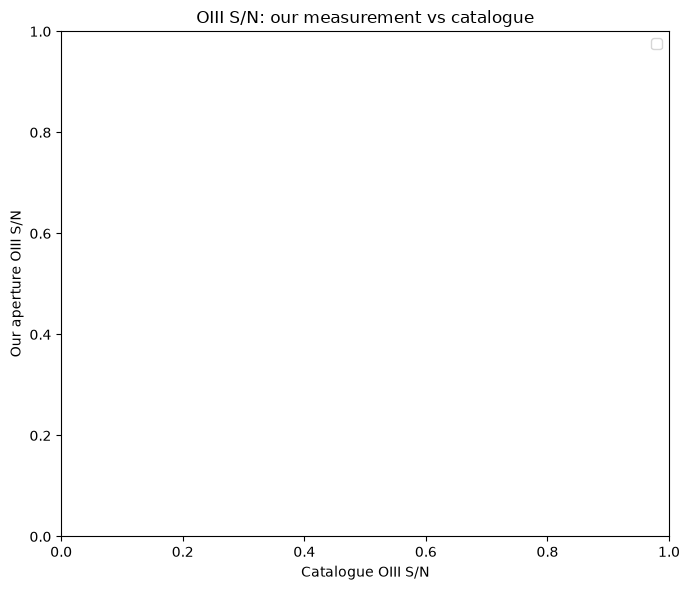

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_3606/3743317527.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


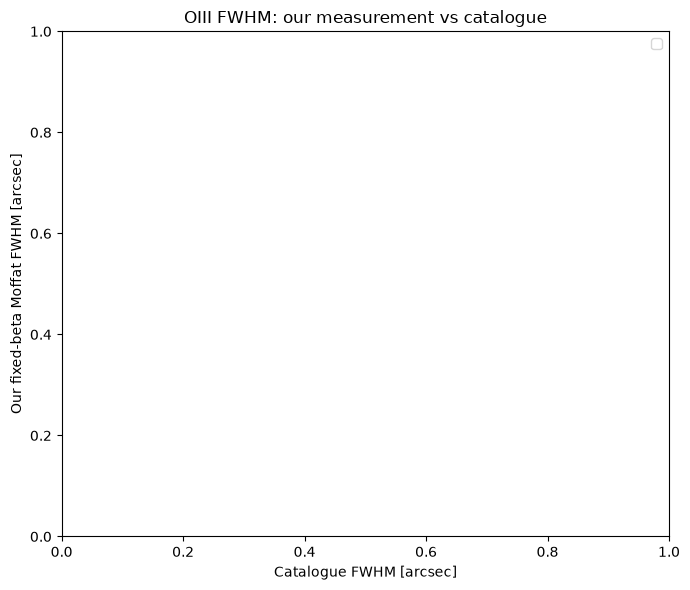

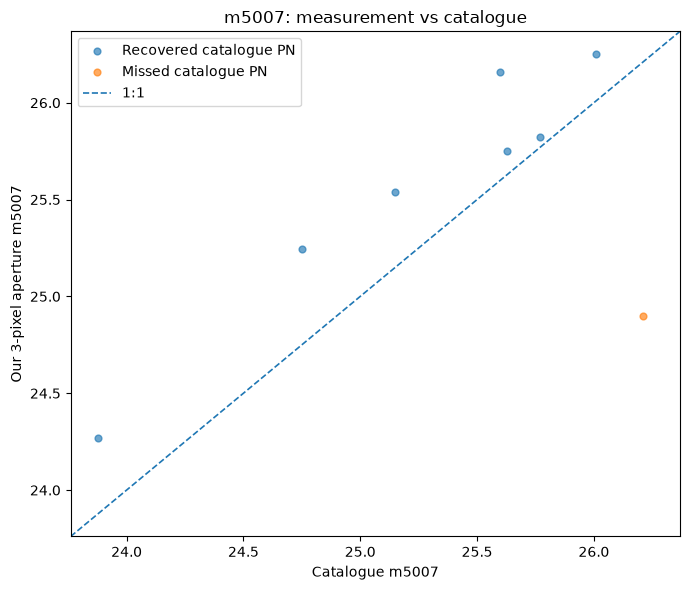

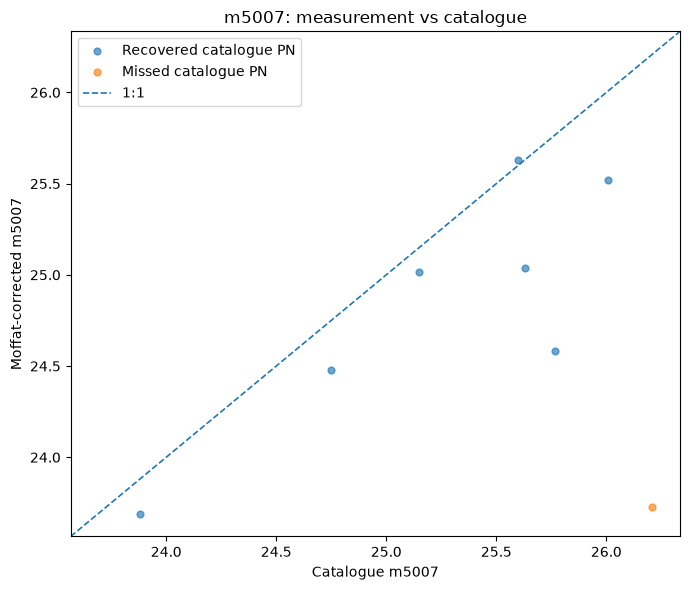

Median raw-aperture m5007 - catalogue m5007: +0.315 mag


,population,quantity,N,spearman_rho,median_ours_over_catalog,median_fractional_difference,median_ours_minus_catalog
0,Recovered catalogue PN,OIII S/N,0,NaN,NaN,NaN,NaN
1,Recovered catalogue PN,FWHM,0,NaN,NaN,NaN,NaN
2,Recovered catalogue PN,m5007 (3-pix aperture),7,0.892857,NaN,NaN,0.388187
3,Recovered catalogue PN,m5007 (Moffat corrected),7,0.642857,NaN,NaN,-0.268846
4,Missed catalogue PN,OIII S/N,0,NaN,NaN,NaN,NaN
5,Missed catalogue PN,FWHM,0,NaN,NaN,NaN,NaN
6,Missed catalogue PN,m5007 (3-pix aperture),1,NaN,NaN,NaN,-1.309944
7,Missed catalogue PN,m5007 (Moffat corrected),1,NaN,NaN,NaN,-2.479730
8,All catalogue PNe,OIII S/N,0,NaN,NaN,NaN,NaN
9,All catalogue PNe,FWHM,0,NaN,NaN,NaN,NaN


Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/catalog_vs_our_measurements_M33_v4.5.csv


,object_id,population,catalog_oiii_snr,oiii_snr,catalog_fwhm_arcsec,moffat_fwhm_arcsec,catalog_m5007,m5007_aperture,m5007_moffat_corrected,m5007_aperture_err,m5007_aperture_minus_catalog,m5007_corrected_minus_catalog,oiii_snr_ours_over_catalog,fwhm_ours_over_catalog
0,PN_45,Recovered catalogue PN,NaN,309.324475,NaN,0.898342,25.628944,25.750003,25.037304,0.003510,0.121059,-0.591640,NaN,NaN
1,PN_51,Recovered catalogue PN,NaN,362.322880,NaN,0.912531,26.008944,26.250076,25.518256,0.002997,0.241133,-0.490688,NaN,NaN
2,PN_54,Recovered catalogue PN,NaN,376.121390,NaN,0.759259,25.598944,26.157627,25.631411,0.002887,0.558683,0.032467,NaN,NaN
3,PN_59,Recovered catalogue PN,NaN,466.286528,NaN,1.303600,25.768944,25.822651,24.582416,0.002328,0.053707,-1.186527,NaN,NaN
4,PN_67,Recovered catalogue PN,NaN,418.024748,NaN,0.756648,25.148944,25.537783,25.015023,0.002597,0.388839,-0.133921,NaN,NaN
5,PN_68,Recovered catalogue PN,NaN,913.472200,NaN,0.936599,24.748944,25.244325,24.480098,0.001189,0.495381,-0.268846,NaN,NaN
6,PN_76,Recovered catalogue PN,NaN,1326.267853,NaN,0.796369,23.878944,24.267130,23.691541,0.000819,0.388187,-0.187403,NaN,NaN
7,PN_64,Missed catalogue PN,NaN,816.397200,NaN,1.246875,26.208944,24.899000,23.729214,0.001330,-1.309944,-2.479730,NaN,NaN


In [176]:
# Catalogue comparison uses catalogue objects only; unmatched candidates have no reference values.
cat_compare = diagnostic_table[
    diagnostic_table["population"].isin(["Recovered catalogue PN", "Missed catalogue PN"])
].copy()

print(f"Pixel scale used for FWHM conversion: {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")

# ---------- OIII S/N: our aperture S/N vs catalogue ----------
snr_cmp = cat_compare[
    np.isfinite(cat_compare["catalog_oiii_snr"])
    & np.isfinite(cat_compare["oiii_snr"])
    & (cat_compare["catalog_oiii_snr"] > 0)
    & (cat_compare["oiii_snr"] > 0)
].copy()

plt.figure(figsize=(7, 6))
for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
    g = snr_cmp[snr_cmp["population"] == population]
    if len(g):
        plt.scatter(g["catalog_oiii_snr"], g["oiii_snr"], s=24, alpha=0.65, label=population)
if len(snr_cmp):
    lo = max(0.5, min(snr_cmp["catalog_oiii_snr"].min(), snr_cmp["oiii_snr"].min()))
    hi = max(snr_cmp["catalog_oiii_snr"].max(), snr_cmp["oiii_snr"].max())
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlim(lo, hi)
    plt.ylim(lo, hi)
plt.xlabel("Catalogue OIII S/N")
plt.ylabel("Our aperture OIII S/N")
plt.title("OIII S/N: our measurement vs catalogue")
plt.legend()
plt.tight_layout()
plt.show()

# ---------- FWHM: our fixed-beta Moffat vs catalogue ----------
fwhm_cmp = cat_compare[
    np.isfinite(cat_compare["catalog_fwhm_arcsec"])
    & np.isfinite(cat_compare["moffat_fwhm_arcsec"])
    & (cat_compare["catalog_fwhm_arcsec"] > 0)
    & (cat_compare["moffat_fwhm_arcsec"] > 0)
].copy()

plt.figure(figsize=(7, 6))
for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
    g = fwhm_cmp[fwhm_cmp["population"] == population]
    if len(g):
        plt.scatter(g["catalog_fwhm_arcsec"], g["moffat_fwhm_arcsec"], s=24, alpha=0.65, label=population)
if len(fwhm_cmp):
    lo = min(fwhm_cmp["catalog_fwhm_arcsec"].min(), fwhm_cmp["moffat_fwhm_arcsec"].min())
    hi = max(fwhm_cmp["catalog_fwhm_arcsec"].max(), fwhm_cmp["moffat_fwhm_arcsec"].max())
    pad = 0.05 * (hi - lo) if hi > lo else 0.05
    lo, hi = max(0, lo - pad), hi + pad
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
    plt.xlim(lo, hi)
    plt.ylim(lo, hi)
plt.xlabel("Catalogue FWHM [arcsec]")
plt.ylabel("Our fixed-beta Moffat FWHM [arcsec]")
plt.title("OIII FWHM: our measurement vs catalogue")
plt.legend()
plt.tight_layout()
plt.show()


# ---------- m5007: our measurement vs catalogue ----------
# The raw aperture magnitude is shown first. Because the catalogue may use a
# total/PSF-corrected flux, a second panel uses our Moffat aperture correction.
for ours_col, ours_label, title_suffix in [
    ("m5007_aperture", "Our 3-pixel aperture m5007", "raw aperture"),
    ("m5007_moffat_corrected", "Moffat-corrected m5007", "Moffat aperture-corrected"),
]:
    mag_cmp = cat_compare[
        np.isfinite(cat_compare["catalog_m5007"])
        & np.isfinite(cat_compare[ours_col])
    ].copy()

    plt.figure(figsize=(7, 6))
    for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
        g = mag_cmp[mag_cmp["population"] == population]
        if len(g):
            plt.scatter(g["catalog_m5007"], g[ours_col], s=24, alpha=0.65, label=population)
    if len(mag_cmp):
        lo = min(mag_cmp["catalog_m5007"].min(), mag_cmp[ours_col].min())
        hi = max(mag_cmp["catalog_m5007"].max(), mag_cmp[ours_col].max())
        pad = 0.05 * (hi - lo) if hi > lo else 0.1
        lo, hi = lo - pad, hi + pad
        plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
        plt.xlim(lo, hi)
        plt.ylim(lo, hi)
    plt.xlabel("Catalogue m5007")
    plt.ylabel(ours_label)
    plt.title(f"m5007: measurement vs catalogue")
    plt.legend()
    plt.tight_layout()
    plt.show()


# A multi-magnitude global offset is usually a flux-unit problem, not aperture correction.
mag_unit_check = cat_compare[
    np.isfinite(cat_compare["catalog_m5007"]) & np.isfinite(cat_compare["m5007_aperture"])
]
if len(mag_unit_check):
    med_dm = float(np.nanmedian(mag_unit_check["m5007_aperture"] - mag_unit_check["catalog_m5007"]))
    print(f"Median raw-aperture m5007 - catalogue m5007: {med_dm:+.3f} mag")
    if abs(med_dm) > 5:
        print("WARNING: |median delta m5007| > 5 mag. Check OIII_FLUX_TO_CGS and the FITS BUNIT before interpreting the comparison.")

# ---------- Compact numerical summary ----------
def comparison_stats(df, ours, catalog, name, magnitude=False):
    x = df[catalog].to_numpy(float)
    y = df[ours].to_numpy(float)
    good = np.isfinite(x) & np.isfinite(y)
    if not magnitude:
        good &= (x > 0)
    x, y = x[good], y[good]
    if len(x) == 0:
        return {"quantity": name, "N": 0, "spearman_rho": np.nan,
                "median_ours_over_catalog": np.nan, "median_fractional_difference": np.nan,
                "median_ours_minus_catalog": np.nan}
    rho = spearmanr(x, y).statistic if len(x) >= 3 else np.nan
    if magnitude:
        median_ratio = np.nan
        median_fractional = np.nan
    else:
        median_ratio = np.nanmedian(y / x)
        median_fractional = np.nanmedian((y - x) / x)
    return {
        "quantity": name,
        "N": len(x),
        "spearman_rho": rho,
        "median_ours_over_catalog": median_ratio,
        "median_fractional_difference": median_fractional,
        "median_ours_minus_catalog": np.nanmedian(y - x),
    }

comparison_rows = []
for population in ["Recovered catalogue PN", "Missed catalogue PN", "All catalogue PNe"]:
    g = cat_compare if population == "All catalogue PNe" else cat_compare[cat_compare["population"] == population]
    for rec in [
        comparison_stats(g, "oiii_snr", "catalog_oiii_snr", "OIII S/N"),
        comparison_stats(g, "moffat_fwhm_arcsec", "catalog_fwhm_arcsec", "FWHM"),
        comparison_stats(g, "m5007_aperture", "catalog_m5007", "m5007 (3-pix aperture)", magnitude=True),
        comparison_stats(g, "m5007_moffat_corrected", "catalog_m5007", "m5007 (Moffat corrected)", magnitude=True),
    ]:
        rec["population"] = population
        comparison_rows.append(rec)

catalog_comparison_summary = pd.DataFrame(comparison_rows)[
    ["population", "quantity", "N", "spearman_rho", "median_ours_over_catalog", "median_fractional_difference", "median_ours_minus_catalog"]
]
display(catalog_comparison_summary)
catalog_comparison_summary.to_csv(OUTPUT_DIR / "catalog_vs_our_measurements_M33_v4.5.csv", index=False)
print("Saved:", OUTPUT_DIR / "catalog_vs_our_measurements_M33_v4.5.csv")

# Optional per-object table for inspection.
cols = [
    "object_id", "population", "catalog_oiii_snr", "oiii_snr",
    "catalog_fwhm_arcsec", "moffat_fwhm_arcsec",
    "catalog_m5007", "m5007_aperture", "m5007_moffat_corrected",
    "m5007_aperture_err", "m5007_aperture_minus_catalog", "m5007_corrected_minus_catalog",
    "oiii_snr_ours_over_catalog", "fwhm_ours_over_catalog",
]
display(cat_compare[cols].head(20))


## Why some line ratios are unavailable

A displayed ratio is intentionally withheld unless both the numerator line and OIII have positive background-subtracted flux and S/N > 2. The table below reports the exact reason for unavailable ratios, so `NaN` is not interpreted as a numerical line ratio.


In [177]:
for ratio, status in [
    ("Hb/OIII", "hb_over_oiii_status"),
    ("Ha/OIII", "ha_over_oiii_status"),
    ("NII/OIII", "nii_over_oiii_status"),
]:
    print(f"\n{ratio} status:")
    display(diagnostic_table.groupby(["population", status]).size().rename("N").reset_index())



Hb/OIII status:


,population,hb_over_oiii_status,N
0,Missed catalogue PN,ok,1
1,Recovered catalogue PN,Hb flux <= 0,2
2,Recovered catalogue PN,ok,5
3,Unmatched candidate,Hb S/N <= 2,2
4,Unmatched candidate,Hb flux <= 0,24
5,Unmatched candidate,OIII flux <= 0,3
6,Unmatched candidate,edge object,69
7,Unmatched candidate,ok,57



Ha/OIII status:


,population,ha_over_oiii_status,N
0,Missed catalogue PN,ok,1
1,Recovered catalogue PN,Ha flux <= 0,2
2,Recovered catalogue PN,ok,5
3,Unmatched candidate,Ha flux <= 0,24
4,Unmatched candidate,OIII flux <= 0,3
5,Unmatched candidate,edge object,69
6,Unmatched candidate,ok,59



NII/OIII status:


,population,nii_over_oiii_status,N
0,Missed catalogue PN,ok,1
1,Recovered catalogue PN,NII flux <= 0,1
2,Recovered catalogue PN,ok,6
3,Unmatched candidate,NII S/N <= 2,1
4,Unmatched candidate,NII flux <= 0,20
5,Unmatched candidate,OIII flux <= 0,3
6,Unmatched candidate,edge object,69
7,Unmatched candidate,ok,62


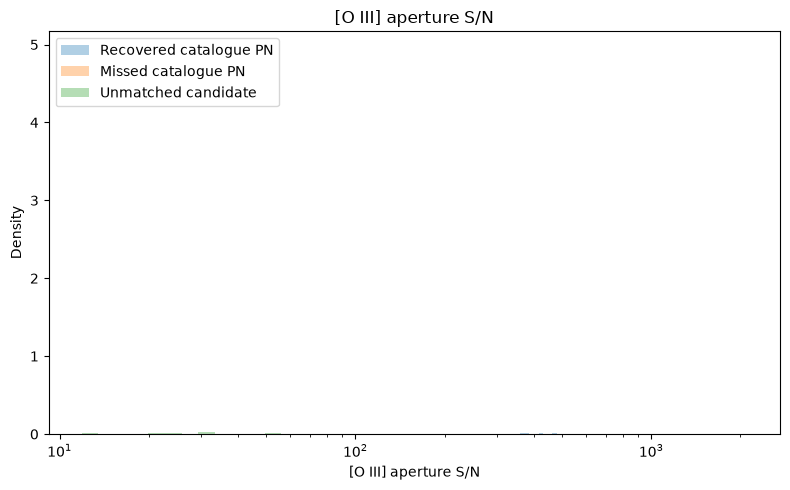

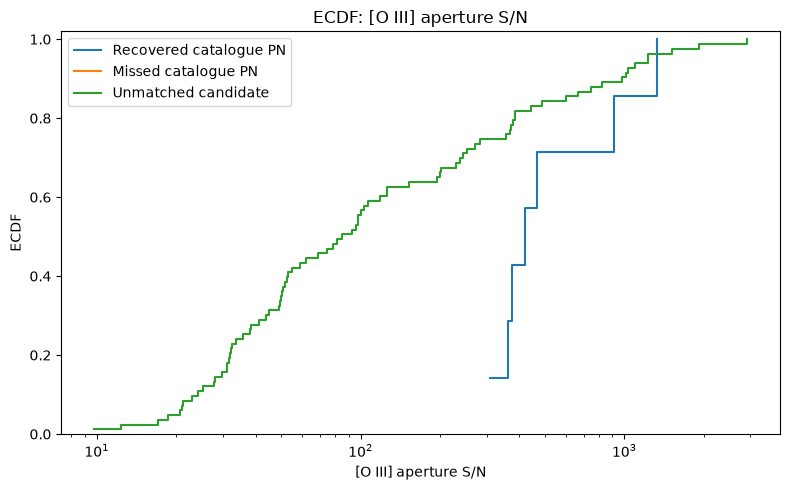

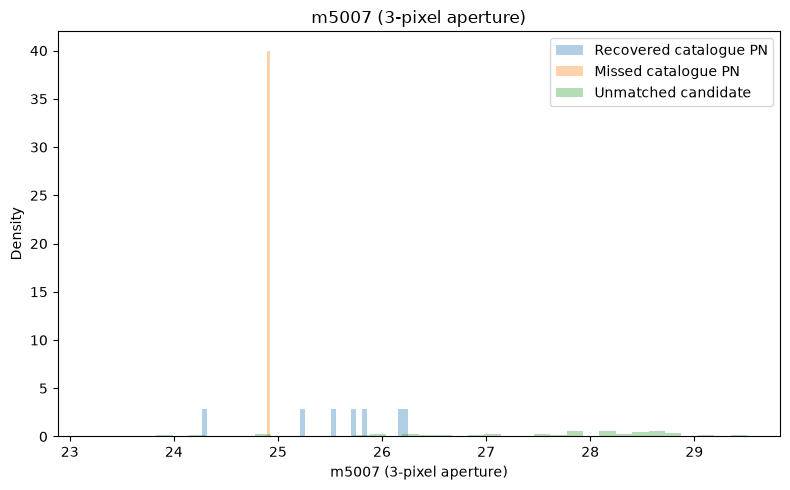

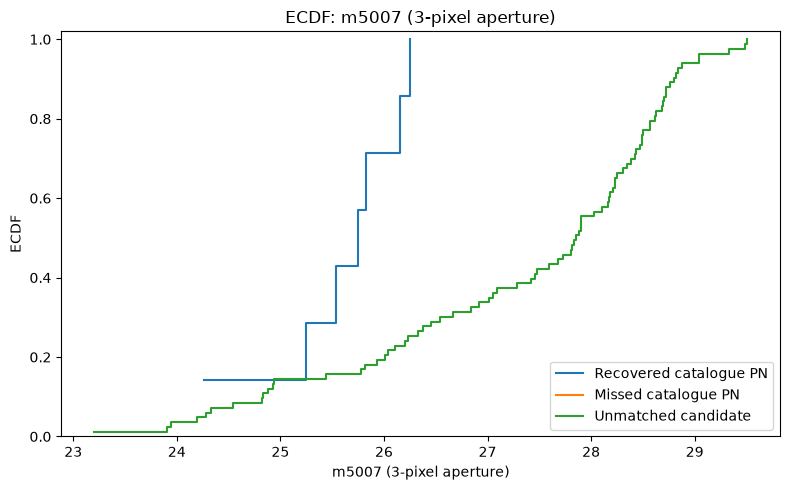

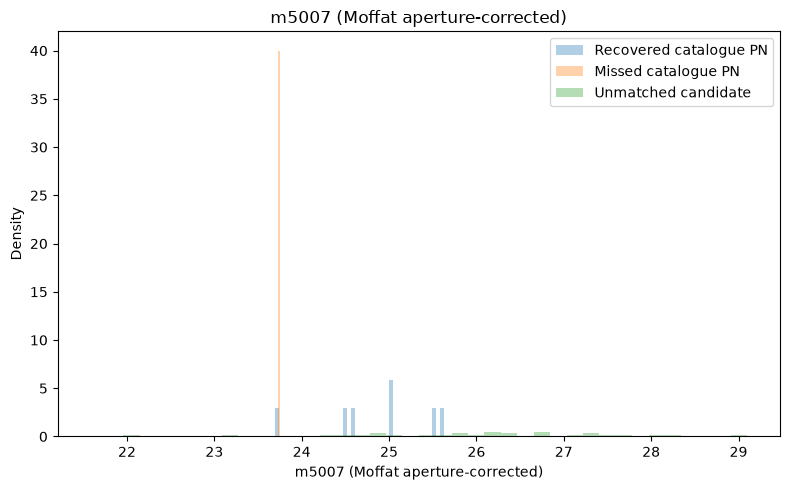

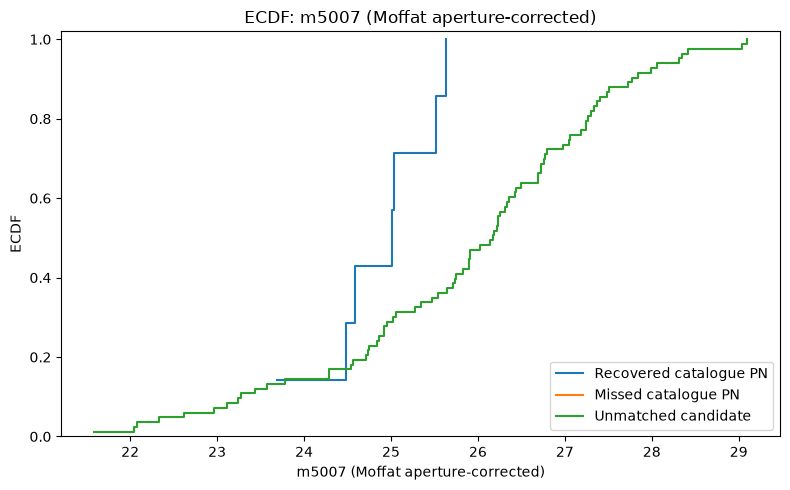

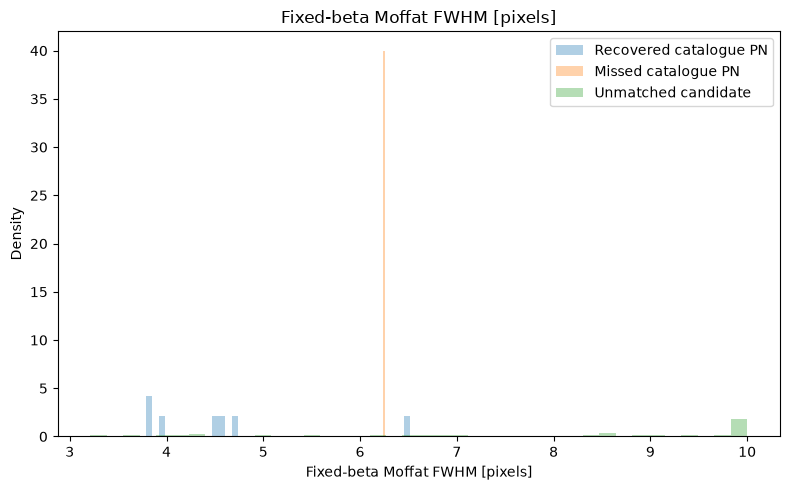

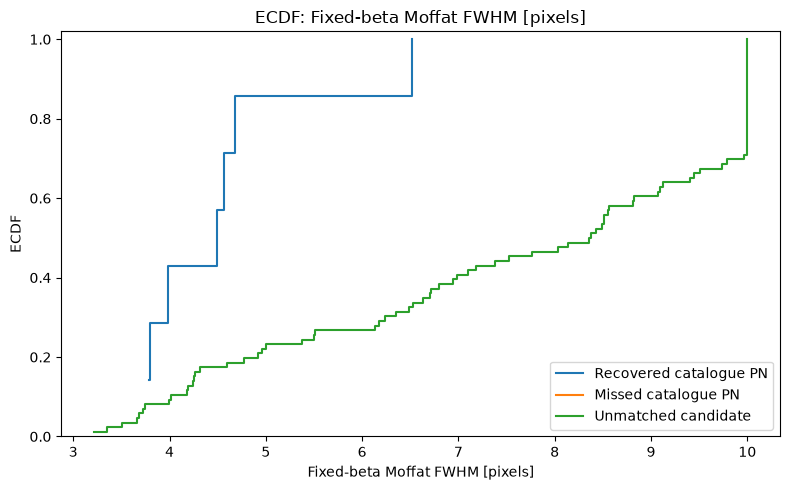

/Users/golta/miniconda3/envs/tf311/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


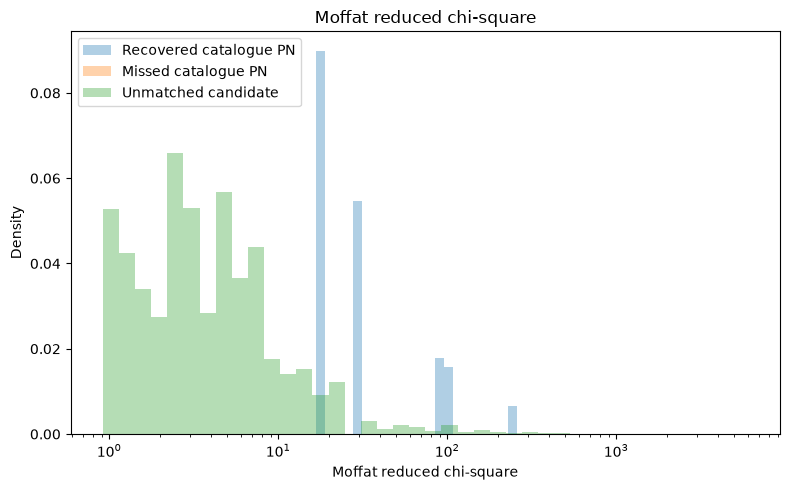

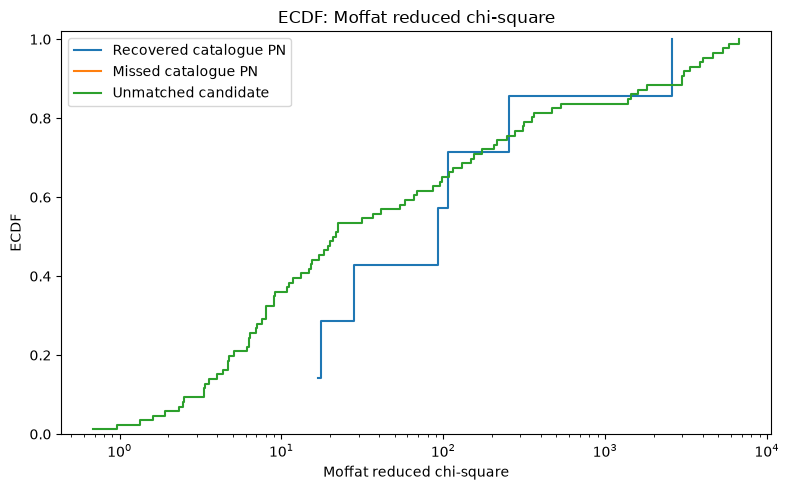

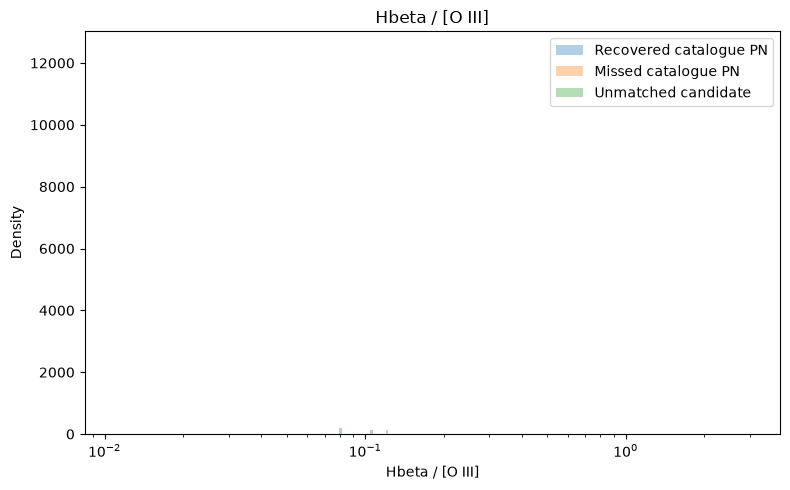

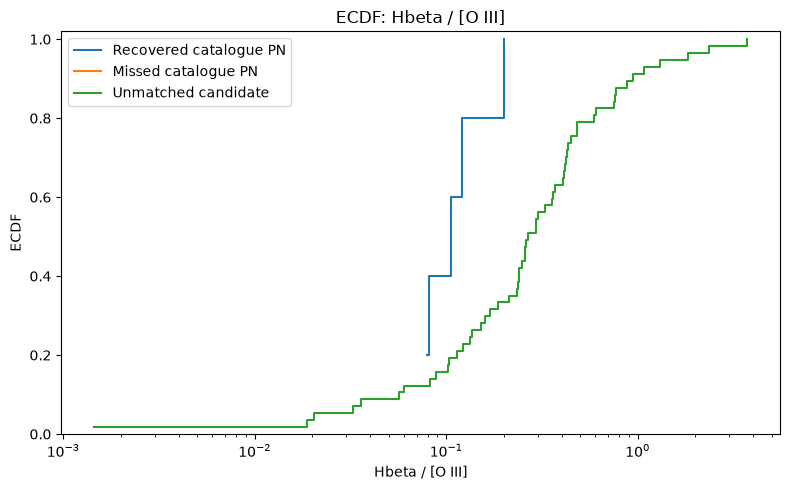

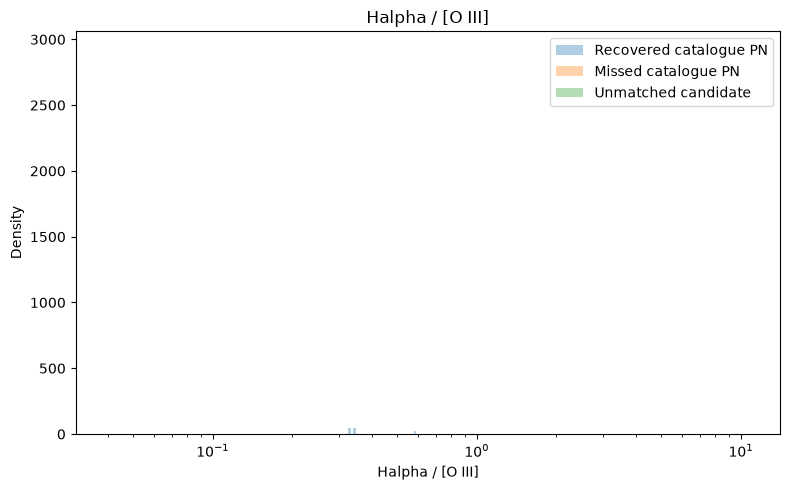

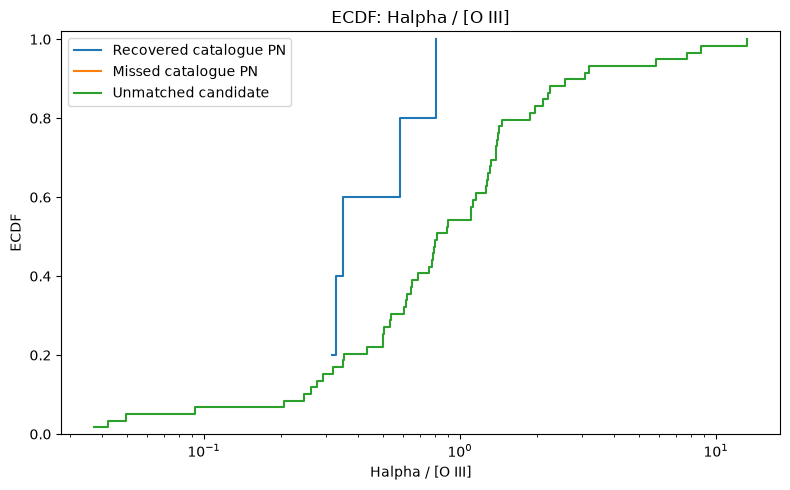

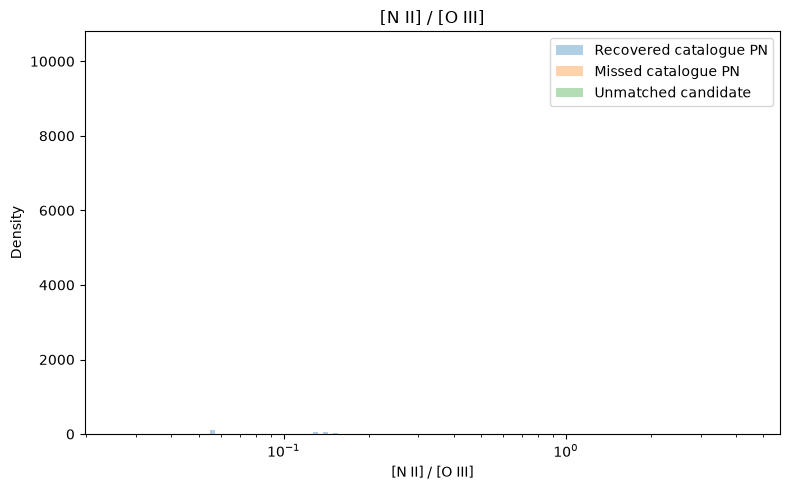

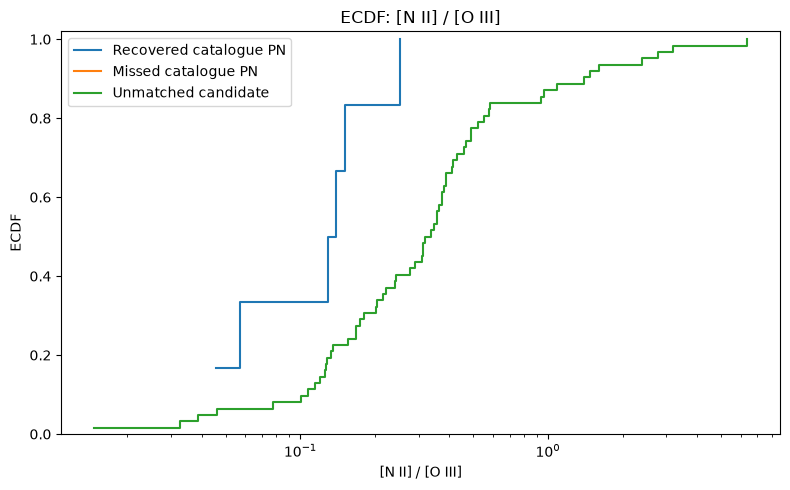

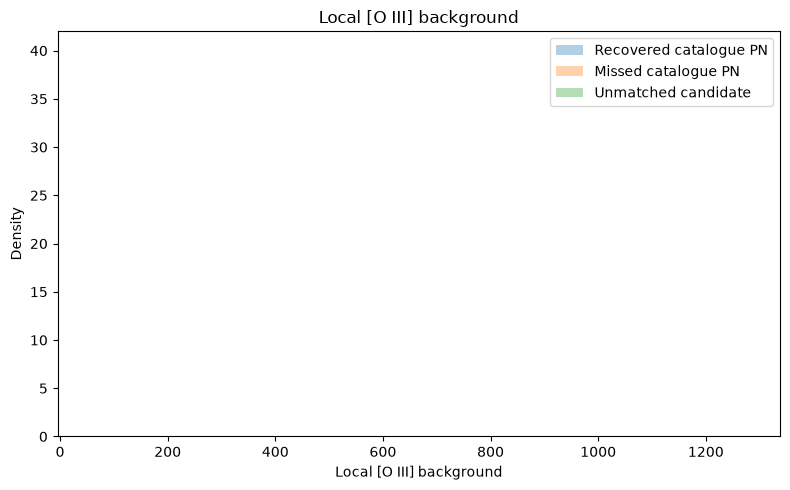

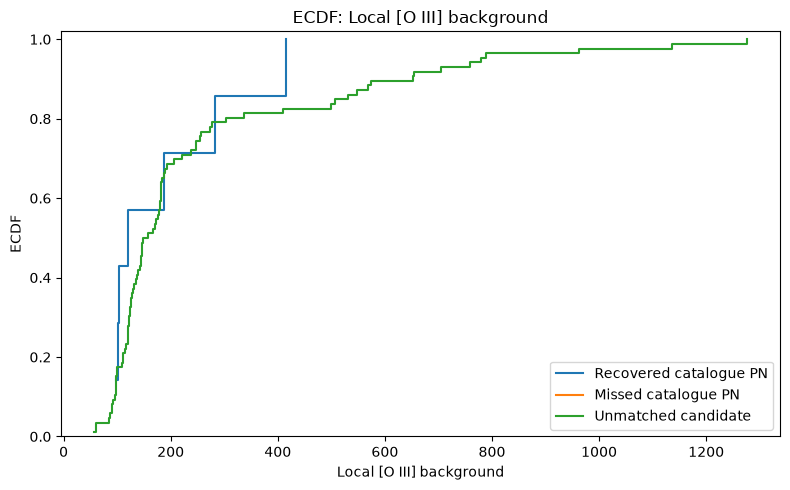

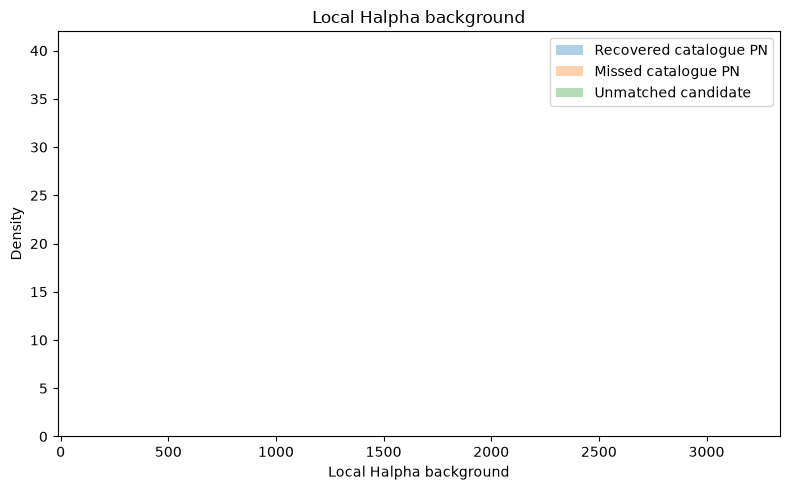

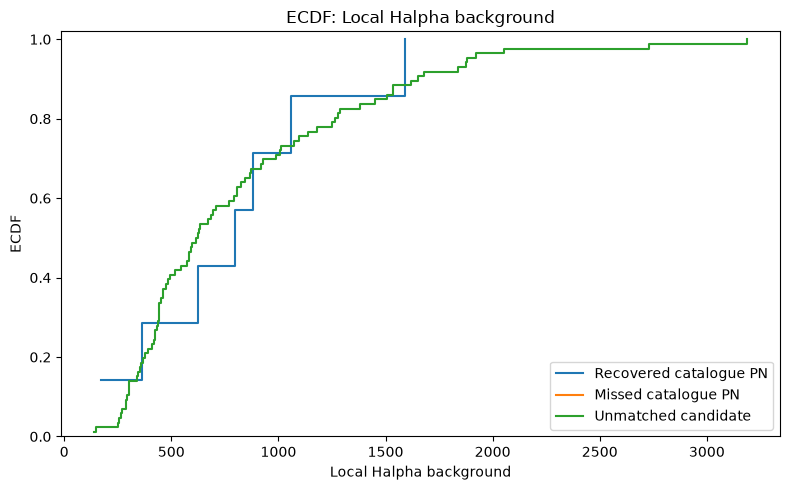

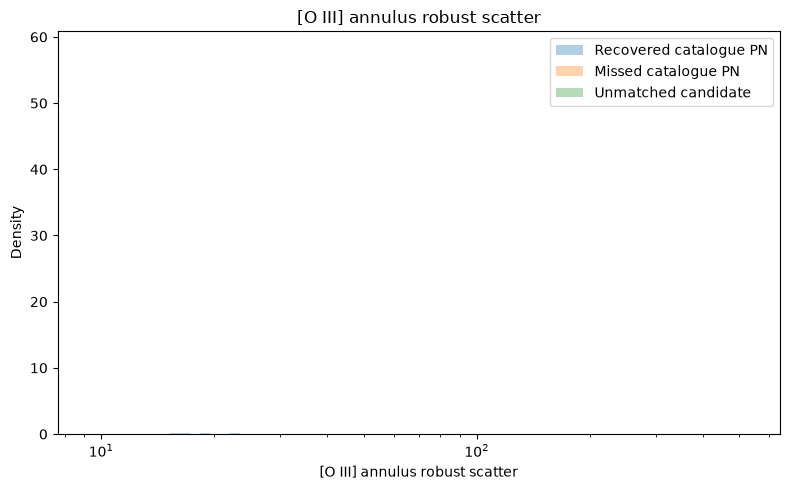

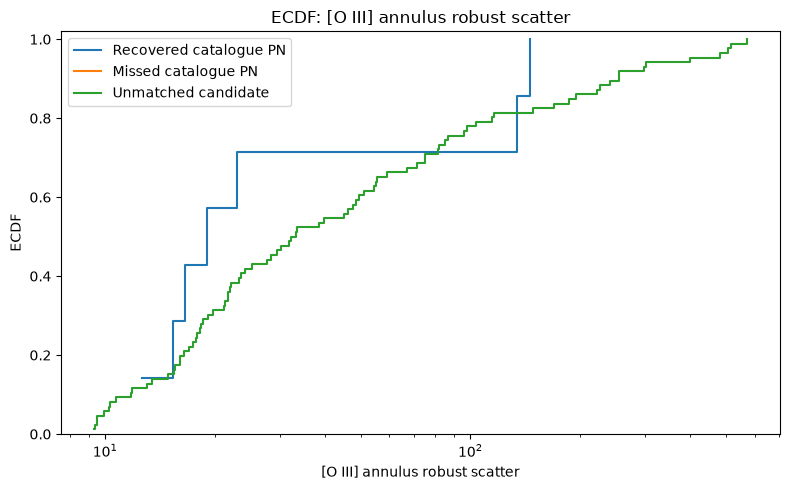

/Users/golta/miniconda3/envs/tf311/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


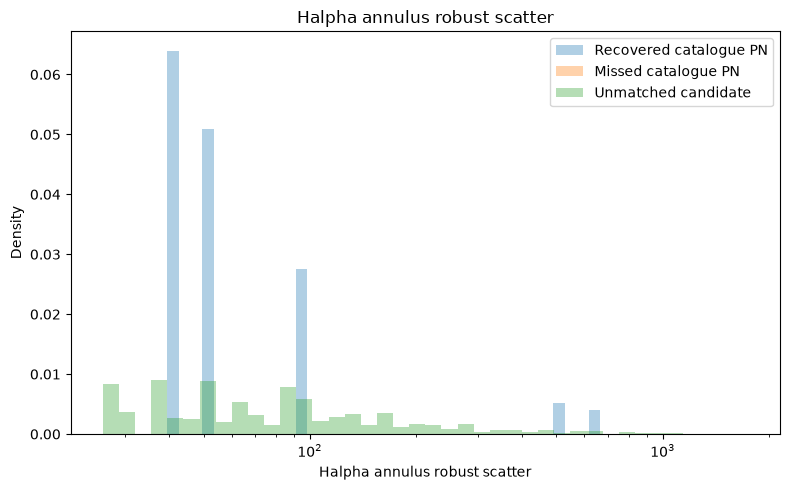

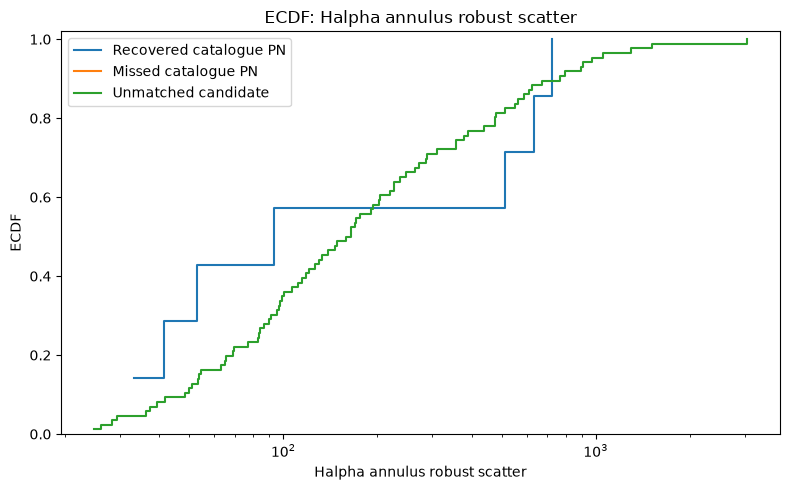

In [178]:
POPULATION_ORDER = [
    "Recovered catalogue PN",
    "Missed catalogue PN",
    "Unmatched candidate",
]


def finite_metric(group, column, positive_only=False):
    vals = group[column].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    if positive_only:
        vals = vals[vals > 0]
    return vals


def plot_metric_histogram(column, xlabel, log_x=False, bins=40):
    plt.figure(figsize=(8, 5))
    any_data = False
    for population in POPULATION_ORDER:
        group = analysis_table[analysis_table["population"] == population]
        vals = finite_metric(group, column, positive_only=log_x)
        if len(vals) == 0:
            continue
        any_data = True
        if log_x:
            lo, hi = np.percentile(vals, [1, 99])
            lo = max(lo, np.min(vals[vals > 0]))
            if hi <= lo:
                hi = lo * 1.01
            edges = np.logspace(np.log10(lo), np.log10(hi), bins + 1)
            plt.hist(vals, bins=edges, density=True, alpha=0.35, label=population)
        else:
            plt.hist(vals, bins=bins, density=True, alpha=0.35, label=population)
    if not any_data:
        return
    if log_x:
        plt.xscale("log")
    plt.xlabel(xlabel)
    plt.ylabel("Density")
    plt.title(f"{xlabel}")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_metric_ecdf(column, xlabel, log_x=False):
    plt.figure(figsize=(8, 5))
    any_data = False
    for population in POPULATION_ORDER:
        group = analysis_table[analysis_table["population"] == population]
        vals = finite_metric(group, column, positive_only=log_x)
        if len(vals) == 0:
            continue
        any_data = True
        vals = np.sort(vals)
        y = np.arange(1, len(vals) + 1) / len(vals)
        plt.step(vals, y, where="post", label=population)
    if not any_data:
        return
    if log_x:
        plt.xscale("log")
    plt.xlabel(xlabel)
    plt.ylabel("ECDF")
    plt.ylim(0, 1.02)
    plt.title(f"ECDF: {xlabel}")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_specs = [
    ("oiii_snr", "[O III] aperture S/N", True),
    ("m5007_aperture", "m5007 (3-pixel aperture)", False),
    ("m5007_moffat_corrected", "m5007 (Moffat aperture-corrected)", False),
    ("moffat_fwhm_pix", "Fixed-beta Moffat FWHM [pixels]", False),
    ("moffat_reduced_chi2", "Moffat reduced chi-square", True),
    ("hb_over_oiii", "Hbeta / [O III]", True),
    ("ha_over_oiii", "Halpha / [O III]", True),
    ("nii_over_oiii", "[N II] / [O III]", True),
    ("oiii_bkg", "Local [O III] background", False),
    ("ha_bkg", "Local Halpha background", False),
    ("oiii_bkg_scatter", "[O III] annulus robust scatter", True),
    ("ha_bkg_scatter", "Halpha annulus robust scatter", True),
]

for column, xlabel, log_x in plot_specs:
    plot_metric_histogram(column, xlabel, log_x=log_x)
    plot_metric_ecdf(column, xlabel, log_x=log_x)


## Spatial distribution and edge diagnostics

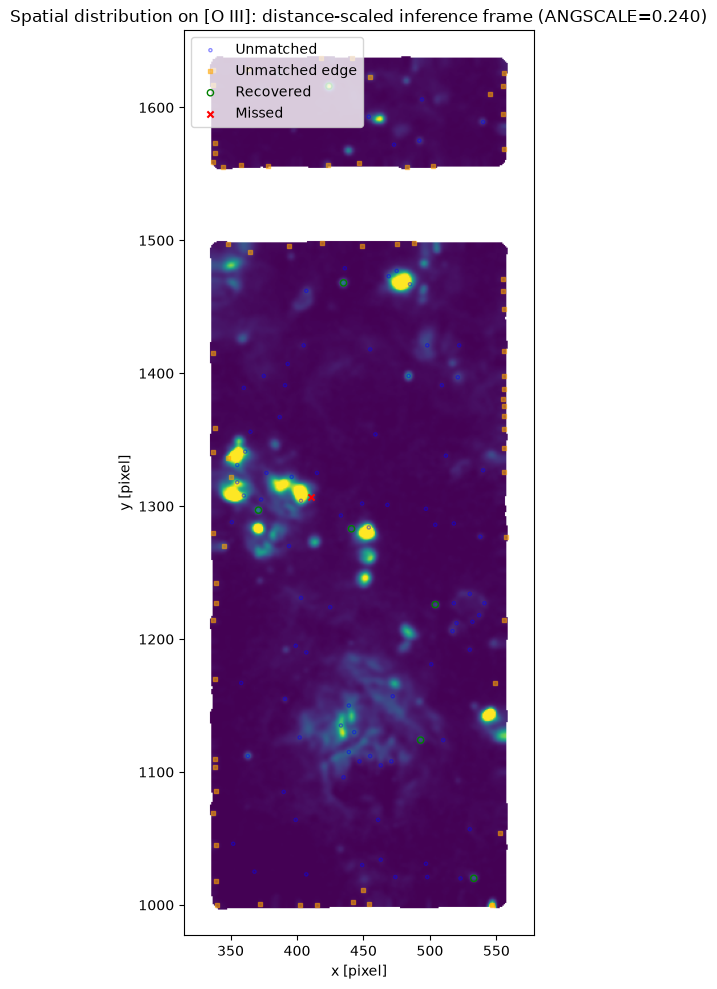

,population,edge_count,total,edge_fraction
0,Missed catalogue PN,0,1,0.000000
1,Recovered catalogue PN,0,7,0.000000
2,Unmatched candidate,69,155,0.445161


In [180]:
# Plot the [O III] channel from the exact native-unit cube used for inference.
plot_oiii = oiii_flux
finite_oiii = plot_oiii[np.isfinite(plot_oiii)]
vmin, vmax = np.percentile(finite_oiii, [5, 99.5]) if len(finite_oiii) else (0, 1)

plt.figure(figsize=(10, 10))
plt.imshow(plot_oiii, origin="lower", vmin=vmin, vmax=vmax)

unmatched_nonedge = diagnostic_table[
    (diagnostic_table["population"] == "Unmatched candidate") & (~diagnostic_table["edge_object"])
]
unmatched_edge = diagnostic_table[
    (diagnostic_table["population"] == "Unmatched candidate") & (diagnostic_table["edge_object"])
]
recovered = diagnostic_table[diagnostic_table["population"] == "Recovered catalogue PN"]
missed = diagnostic_table[diagnostic_table["population"] == "Missed catalogue PN"]

plt.scatter(unmatched_nonedge["center_x"], unmatched_nonedge["center_y"], s=5, label="Unmatched", alpha=0.45, facecolors="None", edgecolors="blue")
plt.scatter(unmatched_edge["center_x"], unmatched_edge["center_y"], s=12, marker="s", alpha=0.55, label="Unmatched edge", color="orange")
plt.scatter(recovered["center_x"], recovered["center_y"], s=20, marker="o", edgecolors="g", facecolors="None", label="Recovered")
plt.scatter(missed["center_x"], missed["center_y"], s=20, marker="x", label="Missed", color="r")
# The distance-scaled footprint occupies only ANGSCALE of the original linear
# size inside the unchanged canvas. Zoom to the finite inference footprint so
# the valid region is not rendered as a tiny patch in a mostly empty image.
valid_y, valid_x = np.where(oiii_valid_mask)
if len(valid_x):
    plot_margin = 20
    plt.xlim(max(0, valid_x.min() - plot_margin), min(width - 1, valid_x.max() + plot_margin))
    plt.ylim(max(0, valid_y.min() - plot_margin), min(height - 1, valid_y.max() + plot_margin))
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plot_frame = (
    f"distance-scaled inference frame (ANGSCALE={DISTANCE_ANGULAR_SCALE:.3f})"
    if not np.isclose(DISTANCE_ANGULAR_SCALE, 1.0)
    else "native inference frame"
)
plt.title(f"Spatial distribution on [O III]: {plot_frame}")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("M33.png")
plt.show()

edge_summary = (
    diagnostic_table.groupby("population")["edge_object"]
    .agg(edge_count="sum", total="count")
    .reset_index()
)
edge_summary["edge_fraction"] = edge_summary["edge_count"] / edge_summary["total"]
display(edge_summary)


## Interpretation guide

Use the diagnostics in this order:

1. **FWHM + reduced χ²:** if unmatched candidates are broader or systematically poorer Moffat fits than recovered PNe, morphology is a major discriminator.
2. **Line-ratio distributions:** if morphology overlaps but Hβ/[O III], Hα/[O III], or [N II]/[O III] differs, the synthetic spectral coverage is the likely bottleneck.
3. **Background level/scatter + spatial map:** if unmatched candidates cluster in high-background or highly structured regions, real environmental context is driving the domain gap.
4. **Missed PNe:** compare their local network score, morphology, line ratios, and environment with recovered PNe to identify what the model suppresses.
5. If unmatched candidates overlap recovered catalogue PNe in morphology, spectral ratios, S/N, and environment, do not assume they are false positives solely because they are absent from the catalogue; their astrophysical nature needs separate validation.

No PSF-normalized FWHM quantity is computed, by design.

In [181]:
# ============================================================
# Save all recovered and missed catalogue objects as PNG pages
# ============================================================
'''
CATALOGUE_PNG_DIR = OUTPUT_DIR / "all_catalogue_object_pngs"
CATALOGUE_PNG_DIR.mkdir(parents=True, exist_ok=True)

CATALOGUE_PAGE_SIZE = 20
CATALOGUE_SCALING = "local"
CATALOGUE_DPI = 200

def catalogue_annotation_no_chi2(r):
    """Create a catalogue-object label without reduced chi-square."""

    hb_ratio = fmt_ratio_with_status(
        r,
        "hb_over_oiii",
        "hb_over_oiii_status",
        "Hb/OIII",
    )

    ha_ratio = fmt_ratio_with_status(
        r,
        "ha_over_oiii",
        "ha_over_oiii_status",
        "Ha/OIII",
    )

    nii_ratio = fmt_ratio_with_status(
        r,
        "nii_over_oiii",
        "nii_over_oiii_status",
        "NII/OIII",
    )

    return (
        f"{r['population']} | {r['object_id']}\n"
        f"score={fmt_value(r['network_score'], '.3f')}  "
        f"OIII S/N={fmt_value(r['oiii_snr'], '.1f')}\n"
        f"m5007(ap)={fmt_value(r['m5007_aperture'], '.2f')}  "
        f"FWHM={fmt_value(r['moffat_fwhm_pix'], '.2f')} px\n"
        f"{hb_ratio}  {ha_ratio}  {nii_ratio}"
    )

        
def save_all_catalogue_object_pages(
    table,
    output_dir,
    page_size=8,
    scaling="local",
    dpi=200,
):

    selected = table[
        table["population"].isin([
            "Recovered catalogue PN",
            "Missed catalogue PN",
            "Unmatched candidate"
        ])
    ].copy()

    if selected.empty:
        print("No recovered or missed catalogue objects were found.")
        return []

    # Recovered objects first, then missed; descending network score within each.
    population_order = {
        "Recovered catalogue PN": 0,
        "Missed catalogue PN": 1,
        "Unmatched candidate": 2,
    }

    selected["_population_order"] = (
        selected["population"].map(population_order)
    )

    selected = (
        selected
        .sort_values(
            ["_population_order", "network_score", "object_id"],
            ascending=[True, False, True],
            na_position="last",
        )
        .drop(columns="_population_order")
        .reset_index(drop=True)
    )

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    channel_names = list(DISPLAY_MAPS.keys())

    common_scales = (
        common_scales_for_sample(selected)
        if scaling == "common"
        else None
    )

    saved_files = []
    number_of_pages = int(np.ceil(len(selected) / page_size))

    for page_number, start in enumerate(
        range(0, len(selected), page_size),
        start=1,
    ):
        page = selected.iloc[start:start + page_size]

        fig, axes = plt.subplots(
            nrows=len(page),
            ncols=len(channel_names),
            figsize=(16, 3.2 * len(page)),
            squeeze=False,
        )

        for row_index, (_, row) in enumerate(page.iterrows()):
            for column_index, channel_name in enumerate(channel_names):
                ax = axes[row_index, column_index]
                image_map = DISPLAY_MAPS[channel_name]

                cutout, origin = extract_centered_cutout(
                    image_map,
                    row["center_x"],
                    row["center_y"],
                    size=DIAG_CUTOUT_SIZE,
                )

                if cutout is None:
                    ax.text(
                        0.5,
                        0.5,
                        "Cutout outside image",
                        ha="center",
                        va="center",
                        transform=ax.transAxes,
                    )
                    ax.axis("off")
                    continue

                if channel_name == "PN heatmap":
                    vmin, vmax = 0.0, 1.0
                elif scaling == "common":
                    vmin, vmax = common_scales[channel_name]
                else:
                    vmin, vmax = robust_limits(cutout)

                ax.imshow(
                    cutout,
                    origin="lower",
                    cmap="viridis",
                    vmin=vmin,
                    vmax=vmax,
                )

                local_x = row["center_x"] - origin[0]
                local_y = row["center_y"] - origin[1]

                ax.scatter(
                    [local_x],
                    [local_y],
                    marker="+",
                    s=65,
                    linewidths=1.4,
                    color="red",
                )

                if row_index == 0:
                    ax.set_title(channel_name)

                ax.set_xticks([])
                ax.set_yticks([])

            axes[row_index, 0].set_ylabel(
                catalogue_annotation_no_chi2(row),
                fontsize=8,
                rotation=0,
                ha="right",
                va="center",
                labelpad=12,
            )

        first_object = start + 1
        last_object = start + len(page)

        fig.suptitle(
            "All recovered and missed catalogue PNe\n"
            f"Objects {first_object}–{last_object} of {len(selected)} | "
            f"{scaling} scaling",
            fontsize=14,
        )

        fig.tight_layout(rect=[0, 0, 1, 0.96])

        output_path = output_dir / (
            f"M33_all_catalogue_objects_"
            f"page_{page_number:03d}_of_{number_of_pages:03d}.png"
        )

        fig.savefig(
            output_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )
        plt.close(fig)

        saved_files.append(output_path)
        print("Saved:", output_path)

    # Also save the exact rows included in the figures.
    catalogue_csv = output_dir / "M33_all_catalogue_objects.csv"
    selected.to_csv(catalogue_csv, index=False)
    print("Saved catalogue table:", catalogue_csv)

    print(
        f"\nSaved all {len(selected)} catalogue objects "
        f"across {len(saved_files)} PNG page(s)."
    )

    return saved_files


catalogue_png_files = save_all_catalogue_object_pages(
    table=diagnostic_table,
    output_dir=CATALOGUE_PNG_DIR,
    page_size=CATALOGUE_PAGE_SIZE,
    scaling=CATALOGUE_SCALING,
    dpi=CATALOGUE_DPI,
)
'''

Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_001_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_002_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_003_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_004_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_005_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_catalogue_object_pngs/M33_all_catalogue_objects_page_006_of_009.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/M33_pn_diagnostics_v5/all_cata